# Estimación de la motilidad espermática en videos microscópicos mediante detección, seguimiento y Deep Learning (VISEM)

**Curso:** Deep Learning, EAFIT. **Integrantes:** Felipe Giraldo y Santiago Villamizar. **Fecha:** 11 de noviembre de 2026.

**Resumen.** Estimamos los porcentajes de motilidad progresiva, no progresiva e inmóvil de las 85 muestras del dataset VISEM a partir de su video. Un detector YOLO11n (preentrenado con EVISAN y afinado con VISEM-Tracking) y ByteTrack producen la trayectoria de cada espermatozoide; 24 descriptores de movimiento alimentan un Ridge y una red de conjuntos (Deep Sets), y su promedio es el sistema final. Con validación cruzada agrupada por participante (70) el error absoluto medio es de 7,11 puntos porcentuales, y de 6,32 en un test de 15 participantes, frente a 12,80 y 13,22 de predecir el promedio y unos 9 puntos de cuatro redes que aprenden directamente del video. El sistema es un apoyo al análisis de calidad seminal: no diagnostica fertilidad.

Los scripts de `src/` generan los datos intermedios y los modelos; el orden de ejecución está en `README.md`.

## 0. Configuración y reproducibilidad

Fijamos semillas y registramos versiones y hardware para que los resultados se puedan repetir.

In [1]:
import os, random, platform
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

try:
    import torch
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    print("PyTorch:", torch.__version__, "| CUDA runtime:", torch.version.cuda)
    print("GPU disponible:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
except ImportError:
    print("PyTorch no está instalado todavía.")

print("Python:", platform.python_version(), "| SO:", platform.system())

PyTorch: 2.11.0+cu128 | CUDA runtime: 12.8
GPU disponible: True
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
VRAM (GB): 12.8
Python: 3.13.14 | SO: Windows


### Rutas del proyecto

Las carpetas originales quedaron en la raíz (`visem-dataset/` y `EVISAN/`) en lugar de `data/raw/`; las rutas se ajustaron a esa disposición. En Colab, cambiar `ROOT` a la carpeta de Drive. Los datos originales **no se modifican**.

In [2]:
ROOT = Path(".").resolve()          # raíz del proyecto (el cuaderno vive en la raíz, junto a src/ y reports/)
VISEM_DIR = ROOT / "visem-dataset"  # originales de VISEM (no se modifican)
EVISAN_DIR = ROOT / "EVISAN"        # originales de EVISAN (no se modifican)
PROCESSED = ROOT / "data" / "processed"
SPLITS = ROOT / "data" / "splits"
MODELS = ROOT / "models"
FIGURES = ROOT / "reports" / "figures"

for p in (PROCESSED, SPLITS, MODELS, FIGURES):
    p.mkdir(parents=True, exist_ok=True)

print("Raíz del proyecto:", ROOT)
print("VISEM:", VISEM_DIR.exists(), "| EVISAN:", EVISAN_DIR.exists())

Raíz del proyecto: C:\Users\Lenovo\Desktop\AA - Proyecto - RN
VISEM: True | EVISAN: True


## 1. Planteamiento del problema y objetivos

**Título.** Estimación de la motilidad espermática en videos microscópicos mediante detección, seguimiento y Deep Learning (VISEM)

**Problema y relevancia.** La motilidad (qué fracción de los espermatozoides se mueve y cómo lo hace) es uno de los parámetros básicos del análisis seminal del manual de la OMS. Hoy se evalúa mirando la muestra al microscopio: es lento y el resultado depende de quién mira (en VISEM cada video lo evaluó una sola persona, entre cinco evaluadores distintos). Los sistemas CASA automatizan la medición, pero requieren equipos dedicados. Un sistema que estime la motilidad a partir de un video común serviría de apoyo y de segunda lectura. Queremos estimar, a partir del video, los porcentajes de motilidad (progresiva, no progresiva, inmóvil) como apoyo al análisis de calidad seminal. **No se diagnostica fertilidad.**

**Objetivo general.** Desarrollar un sistema de Deep Learning que, a partir de videos microscópicos de VISEM, detecte y siga espermatozoides y estime la motilidad de la muestra (progresiva, no progresiva e inmóvil) como apoyo al análisis de calidad seminal.

**Objetivos específicos:**
1. Entrenar un detector YOLO con EVISAN y evaluar su transferencia a VISEM, midiendo mAP en EVISAN y en las anotaciones de VISEM-Tracking, y la calidad del seguimiento de trayectorias.
2. Extraer características de movimiento (conteo, velocidad y linealidad) y usarlas para estimar los porcentajes de motilidad, evaluando MAE y RMSE frente a los valores de laboratorio con validación cruzada agrupada por participante.
3. Comparar este enfoque con una línea base directa (CNN/modelo de video sobre clips) y analizar en qué casos y por qué falla cada uno.

**Cómo se verifica cada objetivo:**
- **O1:** mAP@0.5 y mAP@0.5:0.95 de los detectores A (EVISAN), B (EVISAN→VISEM) y C (solo VISEM-Tracking) en EVISAN-test y VISEM-Tracking (val y test); calidad del seguimiento con las trayectorias de `labels_ftid` de VISEM-Tracking.
- **O2:** MAE y RMSE por tipo de motilidad, validación cruzada sobre los 70 participantes (media ± desviación) y sobre el test fijo de 15.
- **O3:** tabla comparativa con la línea base de video, sobre los mismos participantes, y análisis de errores.

### Mapa del documento
**Todo el trabajo está en este único cuaderno.** Las secciones 1 a 7 presentan el trabajo (problema y objetivos, datos y preprocesamiento, arquitectura, entrenamiento, resultados, conclusiones, referencias). Al final, los **Anexos A a F** conservan completos los experimentos de investigación (hipótesis, configuración, curvas, resultados y análisis); cada sección de resultados resume el anexo que le corresponde.

| Anexo | Pregunta que responde | Resumen en |
| --- | --- | --- |
| A · ResNet18 sobre imágenes de movimiento | ¿Un modelo preentrenado sobre imágenes de movimiento mejora la línea base de video? | 5.4 |
| B · CNN 3D regularizada | ¿Regularizar la CNN 3D mejora la línea base? | 5.4 |
| C · Ablaciones sobre trayectorias | ¿Qué detector, qué características y cuánto video hacen falta? ¿Una red neuronal sobre trayectorias mejora al Ridge? | 5.3, 5.6 |
| D · Mejoras de Deep Learning | Variable no progresiva, ajuste anidado, modelo de video preentrenado e incertidumbre | 5.4, 6 |
| E · Características CASA adicionales | ¿ALH, BCF y giro medio mejoran la estimación, sobre todo la no progresiva? | 5.8 |
| F · Detector más grande (YOLO11s) | ¿Más capacidad en el detector mejora la detección y la motilidad? | 5.1, 6 |


## 2. Base de datos y preprocesamiento

### 2.1 VISEM (dataset principal)
Haugen et al. (2019), *VISEM: A Multimodal Video Dataset of Human Spermatozoa*, MMSys'19 (https://dl.acm.org/doi/10.1145/3304109.3325814). 85 participantes hombres mayores de edad, recolectados en Noruega entre 2008 y 2013; licencia solo para investigación y educación. Hechos verificados en los archivos locales:

- 85 videos `.avi` en `visem-dataset/videos/`, uno por participante; 6 CSV y `descriptions.txt`.
- Los CSV usan **`;` como separador y `,` como decimal**, con BOM (`encoding="utf-8-sig"`), y contienen texto como `Not reported` en columnas numéricas.
- `fatty_acids_spermatoza.csv` (sin la "r") es el nombre real del archivo de ácidos grasos de espermatozoides.
- `videos.csv` tiene columnas `ID;video`.
- Variable objetivo (en `semen_analysis_data.csv`): `Progressive motility (%)`, `Non progressive sperm motility (%)`, `Immotile sperm (%)`. Las tres **suman exactamente 100 en los 85 participantes**: es una composición, no tres variables independientes (ver 2.2 y 3).
- El nombre del video termina con el código de quien lo evaluó (SSW 30, JMA 27, HH 18, OW 7, IVS 3) y 14 nombres traen notas de calidad (`drift`, `minor drift`, `lots of debris`).

In [3]:
# Exploración inicial de las tablas de VISEM (formato: separador ';', decimal ',', BOM)
csv_files = sorted(VISEM_DIR.glob("*.csv"))
print("CSV encontrados:", [f.name for f in csv_files] or "ninguno")

tables = {
    f.stem: pd.read_csv(f, sep=";", decimal=",", encoding="utf-8-sig", na_values=["Not reported"])
    for f in csv_files
}
for name, df in tables.items():
    print(f"\n== {name}: {df.shape[0]} filas x {df.shape[1]} columnas | nulos: {int(df.isna().sum().sum())}")
    display(df.head(3))

CSV encontrados: ['fatty_acids_serum.csv', 'fatty_acids_spermatoza.csv', 'participant_related_data.csv', 'semen_analysis_data.csv', 'sex_hormones.csv', 'videos.csv']

== fatty_acids_serum: 85 filas x 16 columnas | nulos: 0


,ID,Serum C14:0 (myristic acid),Serum C16:0 (palmitic acid),Serum C16:1 (palmitoleic acid),Serum C18:0 (stearic acid),Serum C18:1 n-9 (oleic acid),Serum total C18:1,"Serum C18:2 n-6 (linoleic acid, LA)","Serum C18:3 n-6 (gamma-linoleic acid, GLA)",Serum C20:1 n-9,Serum C20:2 n-6,Serum C20:3 n-6,Serum C20:4 n-6,"Serum C20:5 n-3 (eicosapentaenoic acid, EPA)","Serum C22:5 n-3 (docosapentaenoic acid, DPA)","Serum C22:6 n-3 (docosahexaenoic acid, DHA)"
0,1,0.36,29.72,0.64,13.67,9.00,10.90,19.48,0.30,0.16,0.31,3.37,12.07,2.15,1.35,5.53
1,2,0.28,31.22,0.47,11.84,9.02,11.29,20.34,0.22,0.25,0.26,2.06,11.64,2.80,1.04,6.31
2,3,0.36,27.95,0.47,16.57,8.65,10.36,23.75,0.26,0.19,0.35,3.10,7.37,1.95,0.98,6.34



== fatty_acids_spermatoza: 85 filas x 24 columnas | nulos: 0


,ID,Sperm C14:0 (myristic acid),Sperm C15:0 (pentadecanoic acid),Sperm C16:0 (palmitic acid),Sperm C16:1 n-7 (palmitoleic acid),Sperm C17:0,Sperm C18:0 (stearic acid),Sperm C18:1 trans n-6 to n-11,Sperm C18:1 n-9 (oleic acid),Sperm C18:1 n-7 to n-11,...,Sperm C20:1 n-9,Sperm C20:2 n-6,Sperm C22:0,Sperm C20:3 n-6,Sperm C20:4 n-6 and C22:1 n-9 combined,"Sperm C20:5 n-3 (eicosapentaenoic acid, EPA)",Sperm C24:0,Sperm C24:1 n-9,"Sperm C22:5 n-3 (docosapentaenoic acid, DPA)","Sperm C22:6,n3 (docosahexaenoic acid, DHA)"
0,1,1.3,0.2,24.3,0.9,0.3,9.7,0.8,9.8,2.4,...,0.4,0.5,0.1,4.2,2.5,0.06,1.0,1.2,1.3,25.3
1,2,1.5,0.2,26.3,1.3,0.3,8.9,0.9,12.1,2.7,...,0.3,0.9,2.1,2.6,2.6,0.14,1.4,1.6,1.6,17.3
2,3,1.1,0.2,24.8,0.9,0.2,9.0,0.5,12.3,2.3,...,0.4,0.4,1.9,2.2,3.2,0.17,1.7,2.0,1.1,21.5



== participant_related_data: 85 filas x 4 columnas | nulos: 1


,ID,Abstinence time(days),Body mass index (kg/m²),Age (years)
0,1,4.0,32.5,36
1,2,4.0,33.7,61
2,3,2.0,62.7,51


... (2 outputs left out)


== sex_hormones: 85 filas x 9 columnas | nulos: 0


,ID,Seminal plasma anti-Müllerian hormone (AMH) (pmol/L),Serum total testosterone (nmol/L),Serum oestradiol (nmol/L),"Serum sex hormone-binding globulin, SHBG (nmol/L)","Serum follicle-stimulating hormone, FSH (IU/L)","Serum Luteinizing hormone, LH (IU/L)",Serum inhibin B (ng/L),"Serum anti-Müllerian hormone, AMH (pmol/L)"
0,1,64,16.8,0.13,15,2.3,4.2,289,54
1,2,423,15.0,0.15,43,7.2,2.7,164,19
2,3,37,8.2,0.18,32,4.2,4.8,67,47



== videos: 85 filas x 2 columnas | nulos: 0


,ID,video
0,1,1_09.09.02_SSW.avi
1,2,2_09.09.03_lots of debris_SSW.avi
2,3,3_11.01.21_JMA.avi


**Observaciones de la exploración (calculadas sobre los CSV locales):**

| Variable | Media | Desv. | Mín | Máx |
| --- | --- | --- | --- | --- |
| Progresiva (%) | 42.7 | 20.1 | 0 | 76 |
| No progresiva (%) | 27.7 | 9.5 | 4 | 54 |
| Inmóvil (%) | 29.6 | 17.7 | 10 | 96 |

- Las tres suman 100: conviene predecir una salida que respete eso (p. ej. softmax o predecir dos y derivar la tercera) y reportar MAE/RMSE de las tres.
- Cada participante tiene **un solo evaluador** y las etiquetas tienen variabilidad entre evaluadores: es un techo de calidad que hay que mencionar en limitaciones.
- La relación entre evaluador, calidad del video y error del modelo se analiza en la sección 5.5.

### 2.2 División en entrenamiento, validación y prueba

**Regla:** dividir **por participante**, nunca por frame o clip. Los fotogramas consecutivos son casi idénticos; si caen en conjuntos distintos, el modelo "ve" la prueba durante el entrenamiento y la métrica se infla.

**Diseño adoptado** (generado por `src/make_splits.py`, semilla 42, guardado en `data/splits/folds.csv`):
- **Test fijo: 15 participantes**, 4 con cajas de VISEM-Tracking y 11 sin ellas. No se usan para entrenar ni el detector ni el regresor.
- **70 participantes restantes** en **5 folds agrupados por participante** (14 por fold) para validación cruzada; se reporta media ± desviación.
- **Estratificación por motilidad progresiva**: cada fold y el test cubren todo el rango de la variable objetivo (media del test 41,9 % frente a 42,7 % global).
- Los 20 participantes con cajas se reparten entre folds (4/3/3/3/3): el detector entrena con los folds 1–4 y valida con el fold 0. Así el detector nunca ve las cajas de un participante de test.

**Por qué no solo validación cruzada de los 85:** exigiría reentrenar el detector en cada fold y no cabe en el tiempo disponible. El costo es que el test (15) es pequeño y ruidoso; por eso se reporta también la validación cruzada de los 70.

**Limitación conocida:** el test queda desbalanceado por evaluador (9 de 15 son de JMA; JMA evaluó 27 de 85 videos). Como la etiqueta tiene variabilidad entre evaluadores, hay que mencionarlo al interpretar el error.

In [4]:
# Splits por participante: los genera src/make_splits.py (una sola vez); aquí solo se leen.
# Para regenerarlos: .venv\Scripts\python.exe src\make_splits.py (NO hacerlo una vez empiecen los experimentos).
folds = pd.read_csv(SPLITS / "folds.csv")
print(folds.groupby("split").size().to_dict())
display(folds[folds.split == "trainval"].groupby("fold").agg(
    n=("ID", "size"), con_cajas=("has_tracking", "sum"),
    prog_media=("progressive", "mean"), inmovil_media=("immotile", "mean")).round(1))

{'test': 15, 'trainval': 70}


,n,con_cajas,prog_media,inmovil_media
fold,,,,
0,14,4,40.5,30.9
1,14,3,43.1,35.9
2,14,3,43.4,26.2
3,14,3,43.0,29.9
4,14,3,44.1,24.8


### 2.3 Extracción de clips y frames (una sola vez)

Decodificar 35 GB de video en cada época es inviable, así que cada fuente se extrae **una vez** a disco y se entrena desde ahí. Hay tres productos, todos generados por scripts de `src/` (reanudables):

| Producto | Script | Qué contiene | Por qué |
| --- | --- | --- | --- |
| Clips en gris | `extract_videos.py` | 4 ventanas de **30 s reales** por participante (0–120 s), 750 frames a **25 fps** efectivos, 320×240, `uint8` | El fps real varía entre 37 y 50 según el video, así que se indexa por **tiempo** y no por número de frame. 25 fps y 320×240 bastan para ver movimiento en un clip de 1,28 s (32 frames). Ocupan unos 20 GB frente a los 35 GB originales, pero se leen por ventanas con acceso directo (sin decodificar video en cada época). |
| Dataset YOLO de EVISAN | `prepare_detector_data.py` | XML Pascal VOC → YOLO, **una sola clase** (`sperm`), split por **secuencia** | Las clases `black`/`white` no están documentadas; fusionarlas hace comparables los mAP con VISEM-Tracking. |
| Dataset YOLO de VISEM-Tracking | `prepare_detector_data.py` | 1 de cada 5 frames, split por **participante** según `folds.csv` | Frames consecutivos son casi idénticos; submuestrear evita entrenar y validar con imágenes duplicadas. |

El **seguimiento** (velocidad) no usa estos arrays reducidos: corre sobre el video original, a su fps real, durante los primeros 120 s, porque la velocidad depende del fps y del tamaño de píxel.

La celda siguiente verifica lo que quedó en disco.

In [5]:
manifest = pd.read_csv(PROCESSED / "visem_gray" / "manifest.csv")
print("fps y duración de los 85 videos:")
display(manifest[["fps", "duration_s"]].describe().round(1).T)

npy = list((PROCESSED / "visem_gray").glob("*.npy"))
print(f"{len(npy)} arrays de 30 s (esperado 85 x 4 = 340) | {sum(f.stat().st_size for f in npy) / 1e9:.1f} GB en disco")

rows = []
for ds in ("evisan_yolo", "visem_yolo"):
    for split in ("train", "val", "test"):
        rows.append(dict(dataset=ds, split=split, imagenes=len(list((PROCESSED / ds / split / "images").glob("*.jpg")))))
display(pd.DataFrame(rows).pivot(index="dataset", columns="split", values="imagenes"))

fps y duración de los 85 videos:


,count,mean,std,min,25%,50%,75%,max
fps,85.0,49.2,2.1,37.3,49.3,49.8,49.9,50.2
duration_s,85.0,214.9,66.7,120.4,171.0,209.4,242.5,425.6


340 arrays de 30 s (esperado 85 x 4 = 340) | 19.6 GB en disco


split,test,train,val
dataset,,,
evisan_yolo,1000,4000,1000
visem_yolo,1170,3528,1141


### 2.4 Normalización y aumento de datos

Cada decisión sigue una idea: **conservar lo que mide la motilidad (cuánto se mueve cada célula) y quitar lo que no es información.**

- **Brillo normalizado por clip** `(x − media) / desviación`: los videos tienen iluminación distinta según la sesión, y eso no debe influir en la motilidad.
- **Dos canales para la CNN 3D:** el frame normalizado y el frame menos la media temporal del clip. La media temporal es el fondo estático (y el residuo no móvil); lo que queda al restarla es lo que se mueve.
- **Aumentos espaciales** (recorte aleatorio de 160×160 y volteos horizontal y vertical): bajo el microscopio no hay "arriba", y el recorte multiplica las posiciones vistas sin tocar la dinámica.
- **No se alteran la rapidez ni el orden del movimiento** en la línea base (nada de submuestreo temporal aleatorio ni cambios de fps): la velocidad aparente es exactamente lo que se quiere medir. En el experimento 02 se prueba la inversión temporal, que conserva la magnitud de la velocidad.
- **YOLO:** aumentos por defecto de Ultralytics (mosaico, color, volteo horizontal, escala). El detector D añade volteo vertical y más variación de saturación/valor, porque el detector entrenado en pocos participantes falló en una muestra con residuo y contraste distintos (participante 19).

La celda siguiente muestra los dos canales para el participante de **menor** y el de **mayor** motilidad progresiva del conjunto de entrenamiento/validación: en el primero casi no queda residuo al restar el fondo.

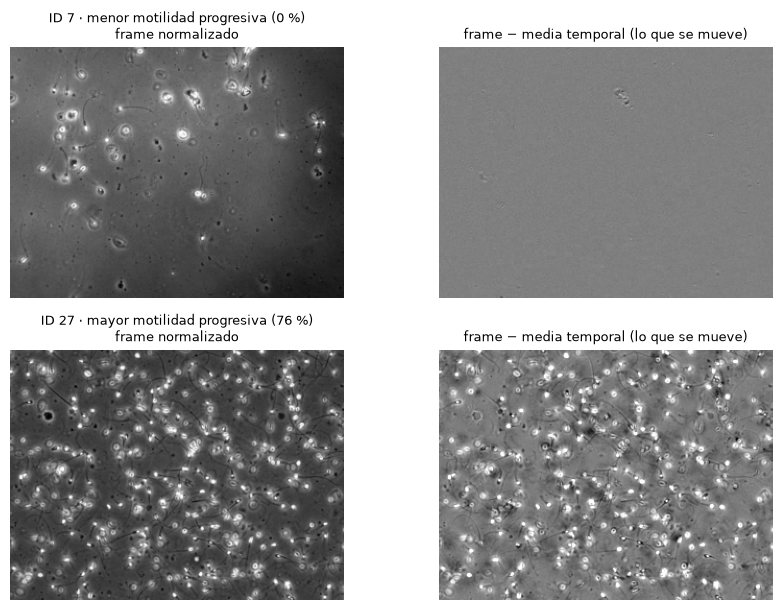

In [6]:
import sys, warnings
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", message="The given NumPy array")
import matplotlib.pyplot as plt
from baseline_video import make_channels

tv = folds[folds.split == "trainval"].set_index("ID")
picks = {"menor motilidad progresiva": tv.progressive.idxmin(), "mayor motilidad progresiva": tv.progressive.idxmax()}
fig, axes = plt.subplots(2, 2, figsize=(9, 6.2))
for r, (title, pid) in enumerate(picks.items()):
    clip = np.load(PROCESSED / "visem_gray" / f"{pid}_w0.npy", mmap_mode="r")[200:232]
    ch = make_channels(clip)               # (2, T, H, W)
    axes[r, 0].imshow(ch[0, 16], cmap="gray"); axes[r, 0].set_title(f"ID {pid} · {title} ({tv.progressive[pid]:.0f} %)\nframe normalizado", fontsize=9)
    axes[r, 1].imshow(ch[1, 16], cmap="gray", vmin=-3, vmax=3); axes[r, 1].set_title("frame − media temporal (lo que se mueve)", fontsize=9)
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.savefig(FIGURES / "clip_channels.png", dpi=130); plt.show()

### 2.5 EVISAN (apoyo para el detector)
Hechos verificados en `EVISAN/`:
- 6.000 imágenes JPEG (`images/1.jpg` … `6000.jpg`), 6.000 XML Pascal VOC (`xml_file/`) y 2 videos `.wmv` (`video/test_200x.wmv`, `test_600x.wmv`).
- Todas las imágenes son de **1200×936**. Imágenes 1–3000 a 200X, 3001–6000 a 600X.
- Dos clases en los XML: `black` (82.349 cajas) y `white` (5.113 cajas). El readme no explica qué significan, así que **no se asume su significado**: ambas se fusionan en una clase.
- Cajas por imagen: 16,7 en promedio a 200X y 12,4 a 600X (máximo 45; ninguna imagen sin anotaciones).
- Los XML traen solo clase y caja, **sin identificador de trayectoria**: EVISAN sirve para evaluar detección pero no trae verdad de terreno de seguimiento. Para eso se usa VISEM-Tracking.

**División por secuencia** (bloques de 1.000 imágenes): entrenamiento = secuencias 1, 2, 4, 5; validación = 3 (200X); **prueba = 6 (600X)**. El readme no indica a qué donante corresponde cada secuencia, así que no se puede garantizar separación por donante: es una limitación.

**Escala de objetos.** A 1200 px de ancho las cajas de EVISAN miden ~40 px; al reescalar a 640 px miden ~21 px, casi igual que las de VISEM-Tracking (~23 px a resolución nativa). Por eso los detectores A, B y C usan `imgsz=640` (objetos del mismo tamaño en ambos dominios).

La celda siguiente aplica la misma función de conversión que usa el pipeline sobre un XML real, para ver el formato resultante.

In [7]:
from prepare_detector_data import voc_to_yolo_lines

lines = voc_to_yolo_lines(EVISAN_DIR / "xml_file" / "1.xml")
print(f"1.xml -> {len(lines)} cajas en formato YOLO (clase xc yc ancho alto, normalizados). Primeras 3:")
print("\n".join(lines[:3]))

1.xml -> 15 cajas en formato YOLO (clase xc yc ancho alto, normalizados). Primeras 3:
0 0.060833 0.175748 0.033333 0.041667
0 0.303750 0.181624 0.032500 0.040598
0 0.185833 0.357906 0.030000 0.047009


## 3. Arquitectura del modelo

El sistema tiene dos caminos que se comparan (objetivo 3): uno **por trayectorias** (detectar → seguir → características de movimiento → regresor) y uno **directo** (CNN sobre clips de video).

| Componente | Arquitectura | Referencia | Justificación / modificaciones |
| --- | --- | --- | --- |
| Detector | YOLO11n (Ultralytics), una clase `sperm` | Jocher, G. y Qiu, J. (2024). *Ultralytics YOLO11*. https://github.com/ultralytics/ultralytics | Detector de una etapa, rápido (procesa 510.000 frames) y pequeño (2,6 M de parámetros), adecuado a 12 GB de VRAM. Modificación: una sola clase y entrenamiento en dos etapas (EVISAN → VISEM-Tracking) para probar la transferencia. |
| Seguimiento | ByteTrack | Zhang, Y. et al. (2022). *ByteTrack: Multi-Object Tracking by Associating Every Detection Box*. ECCV. | Asocia también las detecciones de baja confianza en una segunda pasada, útil con objetos pequeños y borrosos. Se usa tal cual viene en Ultralytics, con `conf` ajustado en validación. |
| Características de movimiento | Parámetros tipo CASA por trayectoria: VCL, VAP, VSL, LIN, STR y fracciones de trayectorias casi quietas, con **corrección de deriva** | Definiciones de velocidad y linealidad del análisis seminal asistido por computador (WHO, *Laboratory manual for the examination and processing of human semen*) | La deriva de la muestra (14 videos traen notas de *drift*) se estima como el desplazamiento mediano entre frames y se resta. Las velocidades quedan en **px/s**: VISEM no trae la escala µm/píxel. |
| Regresor de motilidad | Ridge (regresión lineal con penalización L2) sobre 24 características; se comparan Random Forest y Gradient Boosting | Hoerl, A. y Kennard, R. (1970). *Ridge regression*. Technometrics. | Con 70 participantes un modelo simple y regularizado limita el sobreajuste. Salida normalizada para que las tres cifras sumen 100. |
| Línea base directa | CNN 3D pequeña, entrada de 2 canales (frame normalizado y frame − media temporal) sobre clips de 32 frames | Inspirada en Tran, D. et al. (2015). *Learning Spatiotemporal Features with 3D Convolutional Networks*. ICCV. | Arquitectura propia y reducida (4 bloques Conv3D + BatchNorm + ReLU, pooling global, dropout 0,3, capa lineal de 3 salidas). Pérdida **KL** sobre un softmax: respeta que las tres variables sumen 100. |
| Variantes (anexos A y B) | ResNet18 preentrenada sobre imágenes de movimiento; CNN 3D regularizada | He, K. et al. (2016). *Deep Residual Learning for Image Recognition*. CVPR. | Atacan el sobreajuste de la CNN 3D por dos vías distintas. |

La celda siguiente instancia los modelos y cuenta parámetros, para dimensionar cada enfoque frente a los 56 participantes de entrenamiento por fold.

In [8]:
from ultralytics import YOLO
from baseline_video import Baseline3D
from exp_variants import ResNetMotion, Reg3D

def n_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))

yolo = YOLO(str(MODELS / "detector" / "D_evisan_to_visem_960" / "weights" / "best.pt")).model
rows = [("YOLO11n (detector D)", n_params(yolo), n_params(yolo, True)),
        ("CNN 3D (línea base)", n_params(Baseline3D()), n_params(Baseline3D(), True)),
        ("CNN 3D regularizada (anexo B)", n_params(Reg3D()), n_params(Reg3D(), True)),
        ("ResNet18 movimiento (anexo A)", n_params(ResNetMotion()), n_params(ResNetMotion(), True))]
display(pd.DataFrame(rows, columns=["modelo", "parámetros", "entrenables"]).style.format({"parámetros": "{:,}", "entrenables": "{:,}"}))

,modelo,parámetros,entrenables
0,YOLO11n (detector D),"2,604,883",0
1,CNN 3D (línea base),"293,811","293,811"
2,CNN 3D regularizada (anexo B),"74,331","74,331"
3,ResNet18 movimiento (anexo A),"11,178,051","8,395,267"


## 4. Entrenamiento y configuración experimental

**Recursos de cómputo.** Portátil con CPU Intel Core Ultra 9 275HX, 31,4 GB de RAM y GPU NVIDIA GeForce RTX 5070 Ti Laptop (12 GB de VRAM, arquitectura Blackwell), Windows 11, Python 3.13.14, PyTorch 2.11 con CUDA 12.8 y Ultralytics 8.4. Las redes de video y los detectores se entrenaron en la GPU con precisión mixta (AMP); la red de conjuntos y el Ridge, en la CPU (son pequeños). Semillas fijas (`random`, `numpy`, `torch`): 42 y, para los ensambles, 7 y 123. Las versiones exactas están en `requirements.txt`.

| Experimento | Modelo | Pérdida | Optimizador | LR | Batch | Épocas (máx.) | Tiempo | Notas |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Detector A | YOLO11n, COCO → EVISAN | Ultralytics (caja + clase + DFL) | Auto (Ultralytics) | auto | 16 | 50 | ver tabla abajo | `imgsz=640`; train = secuencias 1, 2, 4, 5 |
| Detector B | A → VISEM-Tracking | ídem | Auto | auto | 16 | 30 | ver tabla | `imgsz=640`; 12 participantes de entrenamiento |
| Detector C | COCO → VISEM-Tracking | ídem | Auto | auto | 16 | 50 | ver tabla | Control: ¿sirve pasar por EVISAN? |
| Detector D | A → VISEM-Tracking | ídem | Auto | 0,003 | 8 | 30 | ver tabla | `imgsz=960`, volteo vertical, más color; ganó en seguimiento sobre validación |
| CNN 3D | Línea base, 5 folds × 3 semillas | KL(objetivo ‖ softmax) | AdamW, wd 0,01 | 1e-3, coseno | 16 | 15 | ~10 s por época | 24 clips por participante y época; se usa **siempre la última época** |
| Red de conjuntos | Deep Sets, 1.478 parámetros, 5 folds × 3 semillas | KL(objetivo ‖ softmax) | AdamW, wd 0,01 | 3e-3, coseno | 4 minilotes por época (~14 participantes) | 300 | ~1 min por fold (CPU) | Aumento: ventana temporal aleatoria de 45 a 120 s y submuestreo de trayectorias; última época; sin ajuste de hiperparámetros (la CV anidada del Anexo D no mejora) |
| Ridge | Regresión lineal penalizada sobre 24 descriptores estandarizados | mínimos cuadrados + α‖w‖² | solución cerrada | α = 10 | — | — | segundos | Elegido por CV frente a Random Forest y Gradient Boosting |
| Detector E (Anexo F) | YOLO11s, COCO → EVISAN → VISEM-Tracking | ídem detectores | Auto | 0,001 en VISEM | 8 | 30 (paciencia 5) | ~0,8 h + 0,2 h | 960 px; no se adopta (peor motilidad en CV) |

**Por qué se usa la última época de la CNN:** elegir la mejor época con el mismo fold que luego se reporta sesgaría el error hacia abajo (se estaría eligiendo sobre los datos de evaluación).

**Selección del detector (en dos pasos; se reportan ambos).** El criterio previo, fijado antes de ver D, fue el seguimiento en validación (MOTA e IDF1 sobre 4 participantes), y por él ganó D (MOTA 0,29 contra 0,06 de B). Pero al evaluar la **tarea final** (estimar motilidad) con validación cruzada de 70 participantes, B resultó mejor que D (sección 5.6), y en test los dos empatan en seguimiento (sección 5.2). **El sistema final usa B.** Esta elección se hizo con la validación cruzada, nunca con el test, y es posterior a ver los resultados de D: se reporta como tal.

La celda siguiente grafica las curvas de los cuatro detectores (pérdida de caja en entrenamiento y validación, y mAP@0.5 de validación) y resume cuándo ocurre el mejor punto.

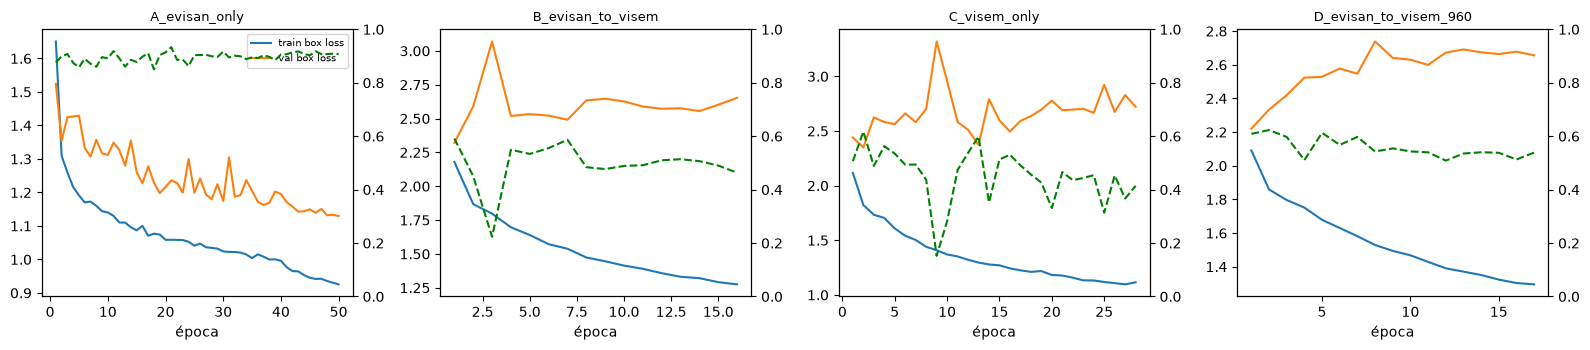

,epocas_corridas,mejor_epoca_ultralytics,mAP50_val_en_mejor,mAP50_val_final,val_box_loss_min,val_box_loss_final,train_box_loss_final,minutos
experimento,,,,,,,,
A_evisan_only,50,46,0.918,0.907,1.129,1.129,0.926,38.053
B_evisan_to_visem,16,1,0.591,0.464,2.321,2.653,1.275,9.903
C_visem_only,28,13,0.598,0.414,2.349,2.722,1.116,17.366
D_evisan_to_visem_960,17,2,0.623,0.539,2.220,2.657,1.295,28.458


In [9]:
exps = ["A_evisan_only", "B_evisan_to_visem", "C_visem_only", "D_evisan_to_visem_960"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=False)
summary = []
for ax, e in zip(axes, exps):
    d = pd.read_csv(MODELS / "detector" / e / "results.csv"); d.columns = [c.strip() for c in d.columns]
    ax.plot(d.epoch, d["train/box_loss"], label="train box loss"); ax.plot(d.epoch, d["val/box_loss"], label="val box loss")
    ax2 = ax.twinx(); ax2.plot(d.epoch, d["metrics/mAP50(B)"], color="green", ls="--", label="val mAP@0.5"); ax2.set_ylim(0, 1)
    ax.set_title(e, fontsize=9); ax.set_xlabel("época")
    fit = 0.1 * d["metrics/mAP50(B)"] + 0.9 * d["metrics/mAP50-95(B)"]; best = int(fit.idxmax())
    summary.append(dict(experimento=e, epocas_corridas=len(d), mejor_epoca_ultralytics=int(d.epoch[best]),
                        mAP50_val_en_mejor=d["metrics/mAP50(B)"][best], mAP50_val_final=d["metrics/mAP50(B)"].iloc[-1],
                        val_box_loss_min=d["val/box_loss"].min(), val_box_loss_final=d["val/box_loss"].iloc[-1],
                        train_box_loss_final=d["train/box_loss"].iloc[-1], minutos=d["time"].iloc[-1] / 60))
axes[0].legend(fontsize=7, loc="upper right"); plt.tight_layout(); plt.savefig(FIGURES / "curvas_detectores.png", dpi=130); plt.show()
display(pd.DataFrame(summary).round(3).set_index("experimento"))

La segunda gráfica muestra la línea base de video: error de validación y pérdida de entrenamiento por época, media ± desviación entre los 5 folds, para las 3 semillas.

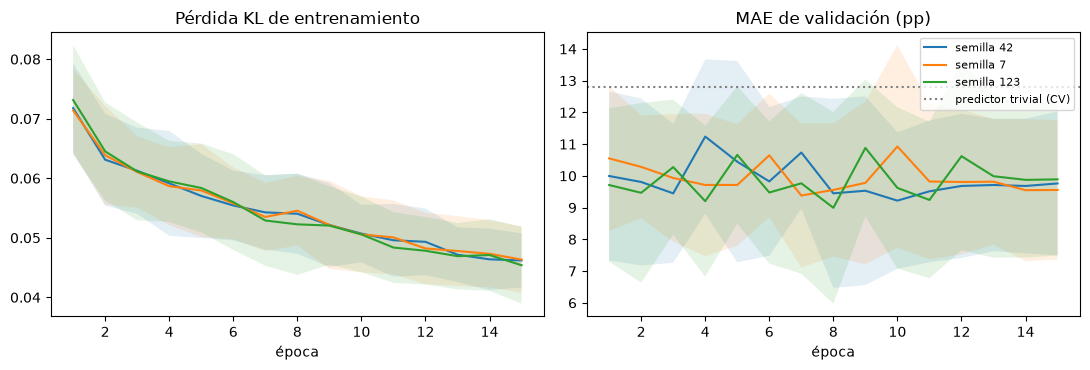

In [10]:
seeds = {"semilla 42": "baseline", "semilla 7": "baseline_s7", "semilla 123": "baseline_s123"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for label, folder in seeds.items():
    H = np.stack([pd.read_csv(MODELS / folder / f"fold{k}" / "history.csv")[["train_kl", "val_mae_pp"]].values for k in range(5)])
    ep = np.arange(1, H.shape[1] + 1)
    for j, ax in enumerate(axes):
        m, s = H[:, :, j].mean(0), H[:, :, j].std(0)
        ax.plot(ep, m, label=label); ax.fill_between(ep, m - s, m + s, alpha=0.12)
axes[0].set_title("Pérdida KL de entrenamiento"); axes[1].set_title("MAE de validación (pp)")
axes[1].axhline(12.80, color="gray", ls=":", label="predictor trivial (CV)"); axes[1].legend(fontsize=8)
for ax in axes: ax.set_xlabel("época")
plt.tight_layout(); plt.savefig(FIGURES / "curvas_cnn3d.png", dpi=130); plt.show()

La tercera gráfica muestra la **red de conjuntos**, la parte de Deep Learning del sistema final: pérdida KL de entrenamiento (último minilote de cada época registrada) y MAE de validación, media de los 5 folds y las 3 semillas.

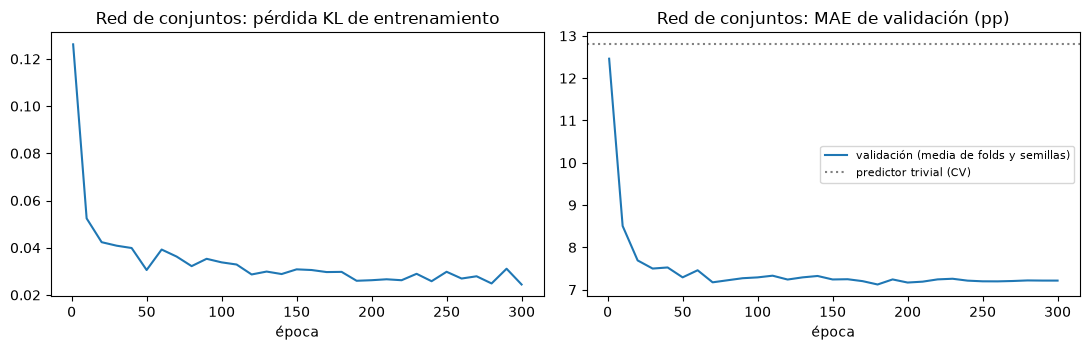

,train_kl,val_mae
epoch,,
1,0.126,12.461
10,0.052,8.507
50,0.031,7.292
100,0.034,7.291
200,0.026,7.169
300,0.024,7.215


In [11]:
hs = pd.concat([pd.read_csv(ROOT / "reports" / f"trackset_history_s{k}.csv").assign(seed=k) for k in (42, 7, 123)])
hm = hs.groupby("epoch")[["train_kl", "val_mae"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(hm.index, hm.train_kl); axes[0].set_title("Red de conjuntos: pérdida KL de entrenamiento"); axes[0].set_xlabel("época")
axes[1].plot(hm.index, hm.val_mae, label="validación (media de folds y semillas)"); axes[1].axhline(12.80, color="gray", ls=":", label="predictor trivial (CV)")
axes[1].set_title("Red de conjuntos: MAE de validación (pp)"); axes[1].set_xlabel("época"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(hm.loc[[1, 10, 50, 100, 200, 300]].round(3))

### Análisis de las curvas

**Detectores (primera figura).**
- **A (solo EVISAN)** converge de forma sana: la pérdida de validación baja de 1,52 a 1,13 junto con la de entrenamiento (1,65 → 0,93) y alcanza su mínimo al final; el mAP@0.5 de validación se mantiene entre ~0,86 y ~0,93 sin tendencia a caer. No hay señal clara de sobreajuste, algo esperable con 4.000 imágenes de entrenamiento.
- **B, C y D (con VISEM-Tracking) sobreajustan casi de inmediato.** La pérdida de **entrenamiento baja** de forma continua (B: 2,18 → 1,28; D: 2,09 → 1,30) mientras la de **validación sube** (B: 2,32 → 2,65; D: 2,22 → 2,66), y el mejor mAP@0.5 de validación aparece en las épocas 1–2 (B 0,59; C 0,62; D 0,62) para luego caer (al final B 0,46; C 0,41; D 0,54). Con solo 12 participantes de entrenamiento (3.528 frames muy parecidos entre sí), la red memoriza a esos participantes en pocas épocas.
- **La validación es muy ruidosa**: en B la pérdida de validación salta a 3,07 en la época 3 y en C el mAP cae a ~0,15 en la época 9 para recuperarse después. Son solo 4 participantes de validación, y basta que uno tenga residuo o un contraste distinto para mover toda la métrica. Por eso el `best.pt` (elegido por Ultralytics con una combinación de mAP@0.5 y mAP@0.5:0.95 sobre esa validación) es una selección ruidosa; esto se suma a la incertidumbre de los resultados con 4 participantes de test.
- **Implicación:** más épocas no ayudan; lo que ayudaría es más participantes anotados, congelar capas o regularizar más. Es una limitación de datos.

**Línea base de video (segunda figura).**
- La pérdida de entrenamiento baja de forma estable (≈ 0,072 → 0,046), pero el MAE de validación **no mejora** con las épocas: oscila entre ~9 y ~11 pp desde la primera época y la diferencia entre semillas es del mismo orden que la variación entre épocas. La red aprende en la primera época una señal gruesa de "cuánto movimiento hay" y las épocas siguientes la dedican a memorizar participantes.
- Es **sobreajuste sin descenso del error de validación**, no subajuste ni falta de convergencia: el modelo tiene capacidad de sobra (56 participantes de entrenamiento por fold) y el límite es la cantidad de datos.
- **Decisión que se derivó:** no seleccionar época con el fold evaluado (usar la última), promediar semillas, y explorar dos formas de combatir el sobreajuste en los anexos A (características preentrenadas) y B (regularización).

**Red de conjuntos (tercera figura).**
- El MAE de validación baja de 12,46 pp en la época 1 (casi el predictor trivial) a 8,51 en la 10 y 7,29 en la 50, y desde ahí **se queda plano** (7,22 en la 300). La KL de entrenamiento pasa de 0,126 a 0,024 (es la del último minilote, por eso es ruidosa).
- **Converge y no sobreajusta**: la validación no empeora mientras el entrenamiento sigue bajando. Con 1.478 parámetros y el aumento de datos (cada época ve una ventana temporal distinta de cada video) tiene poca capacidad para memorizar participantes, al contrario que la CNN 3D de 293.811 parámetros.
- **Decisiones que se derivaron:** se dejaron las 300 épocas (con 50 habría bastado) para no elegir el punto de parada con la validación; no se ajustaron hiperparámetros, y la CV anidada del Anexo D confirmó que ajustar no mejora (7,22 contra 7,21).

## 5. Resultados y evaluación

Todos los números de esta sección se calculan sobre participantes **no vistos** en el entrenamiento del modelo que se evalúa: validación cruzada agrupada por participante (70) y test fijo (15). Se reporta media ± desviación entre folds. El test se usó **una sola vez** por modelo, después de fijar las decisiones con validación.

### 5.1 Detector (objetivo 1): transferencia EVISAN → VISEM
La tabla da mAP@0.5 y mAP@0.5:0.95 en tres conjuntos: EVISAN-test (secuencia 6), VISEM-Tracking validación (4 participantes) y VISEM-Tracking **test** (4 participantes que ningún detector vio). El mAP en VISEM-test mide la transferencia.

In [12]:
ev = pd.read_csv(ROOT / "reports" / "detector_eval.csv")
order = ["A_evisan_only", "B_evisan_to_visem", "C_visem_only", "D_evisan_to_visem_960"]
for metric in ("mAP50", "mAP50_95"):
    print(metric)
    display(ev.pivot(index="experiment", columns="eval_set", values=metric).loc[order, ["EVISAN_test", "VISEM_val", "VISEM_test"]].round(3))

mAP50


eval_set,EVISAN_test,VISEM_val,VISEM_test
experiment,,,
A_evisan_only,0.886,0.226,0.264
B_evisan_to_visem,0.273,0.594,0.470
C_visem_only,0.125,0.599,0.458
D_evisan_to_visem_960,0.524,0.623,0.492


mAP50_95


eval_set,EVISAN_test,VISEM_val,VISEM_test
experiment,,,
A_evisan_only,0.344,0.055,0.072
B_evisan_to_visem,0.115,0.184,0.148
C_visem_only,0.041,0.198,0.108
D_evisan_to_visem_960,0.177,0.194,0.142


**Lectura.**
- **A** es casi perfecto en su propio dominio (mAP@0.5 de 0,886 en EVISAN-test) y **cae a 0,264 en VISEM-test**: la transferencia directa falla. Es el cambio de dominio esperado (otro microscopio, otra magnificación, otro contraste) y es un hallazgo del proyecto, no un error de implementación.
- Afinar con VISEM-Tracking recupera el rendimiento (B 0,470, D 0,492 en VISEM-test) a costa de **olvidar EVISAN** (B baja a 0,273 en EVISAN-test): es el olvido típico al afinar en un dominio distinto.
- **¿Sirve preentrenar con EVISAN?** B (con EVISAN) y C (sin EVISAN) quedan casi empatados en mAP@0.5 (0,470 contra 0,458) y B localiza mejor (mAP@0.5:0.95 de 0,148 contra 0,108). Con 4 participantes de test no se puede afirmar una ventaja firme; lo que sí se observa es que EVISAN **no hace daño** y ayuda un poco a la localización.
- En VISEM el mAP@0.5:0.95 es bajo en todos los detectores (≤ 0,20). Las cajas de VISEM-Tracking son de ~23×23 px, y a ese tamaño un desplazamiento de pocos píxeles baja mucho el IoU; para contar y seguir células importa más el mAP@0.5.
- **D** (960 px, más aumentos) mejora a B en validación (0,623 contra 0,594) y en test (0,492 contra 0,470), una mejora pequeña. D se eligió inicialmente por el seguimiento en validación; el sistema final usa B (ver 5.2 y 5.6).

### 5.1.1 Demostración: qué detecta cada modelo
Las tablas dicen cuánto acierta cada detector; aquí **se ve**. Verde: espermatozoides anotados (EVISAN o VISEM-Tracking). Rojo: detecciones del modelo con confianza ≥ 0,4, el mismo umbral que usa el seguimiento. Primero, dos imágenes de EVISAN (una de validación a 200x y una de test a 600x) con el detector A, que se entrenó con EVISAN; después, un frame de cada uno de los 4 participantes de **test** de VISEM-Tracking, con los detectores A, B y D. Las figuras las genera `src/demo_figures.py`.

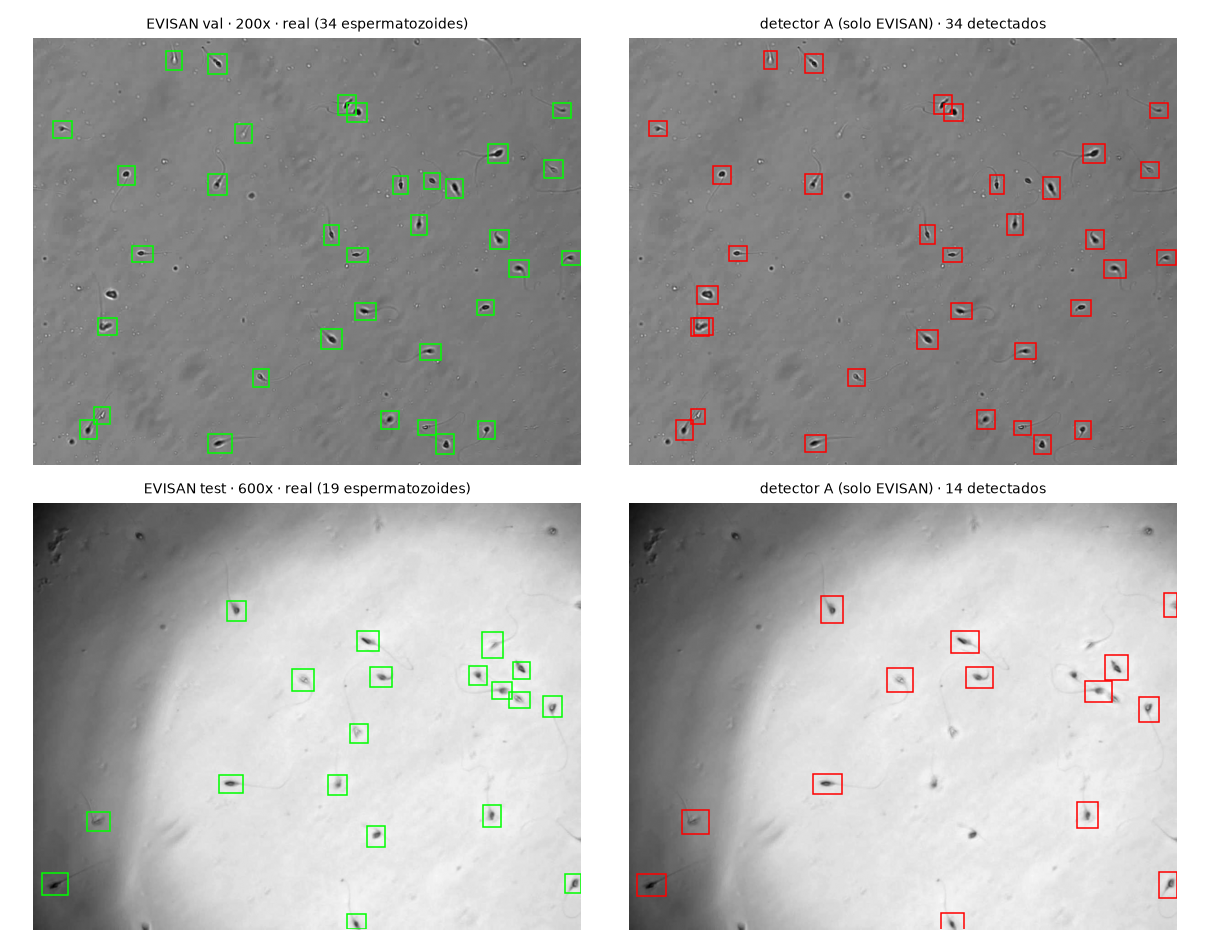

In [13]:
from IPython.display import Image
display(Image(filename=str(FIGURES / "demo_evisan_imagenes.png")))

Ahora VISEM: un frame (el 100 de la ventana) de cada participante de **test** con cajas anotadas (13, 14, 35 y 60), con los detectores A, B y D, y la tabla de cuántos objetos marca cada uno frente a los anotados.

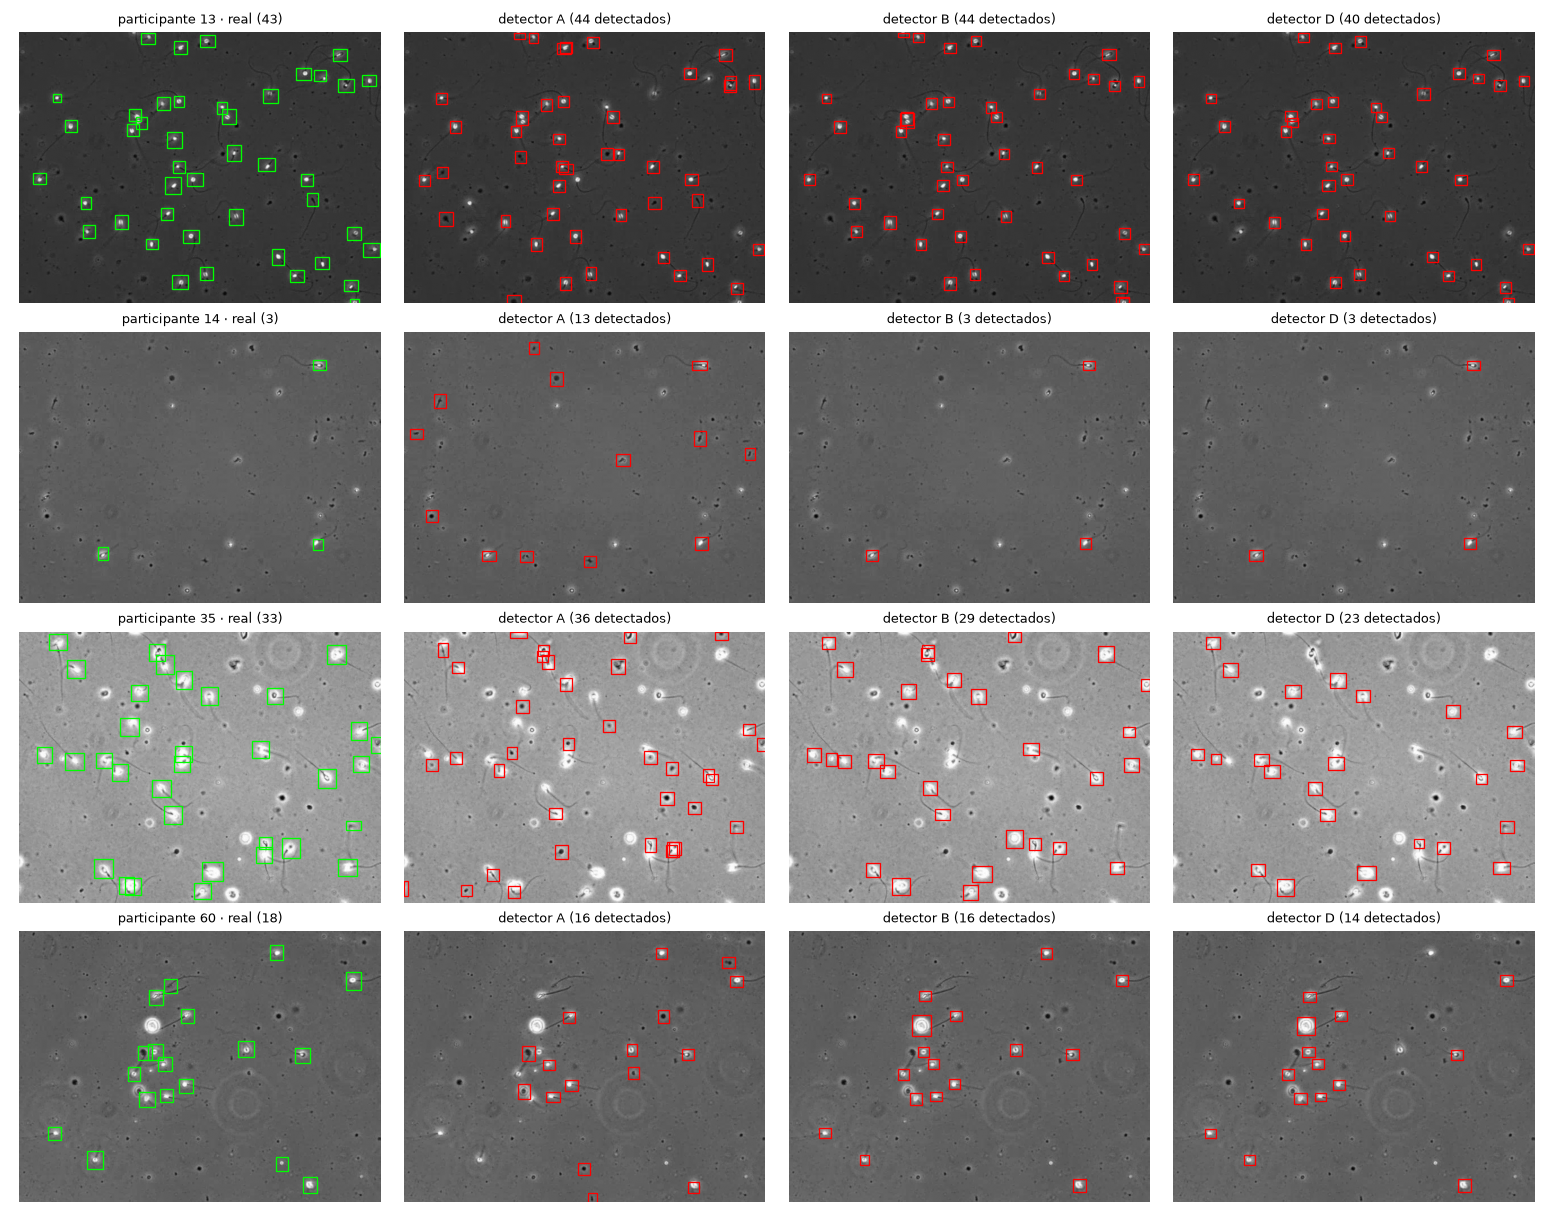

,A,B,D,anotados
participante,,,,
13,44,44,40,43
14,13,3,3,3
35,36,29,23,33
60,16,16,14,18


In [14]:
display(Image(filename=str(FIGURES / "demo_visem_test.png")))
cnt = pd.read_csv(ROOT / "reports" / "demo_conteos_visem.csv")
display(cnt.pivot(index="participante", columns="detector", values="detectados").join(cnt.groupby("participante").reales.first()).rename(columns={"reales": "anotados"}))

**Lectura.**
- **En su propio dominio (EVISAN) el detector A funciona:** en la imagen de validación a 200x marca 34 objetos para 34 anotados, con cajas prácticamente sobre las mismas células, y en la de test a 600x marca 14 para 19 anotados (se le escapan varias, entre ellas células tenues). Es coherente con su mAP@0,5 de 0,886.
- **En VISEM, A no transfiere, y se ve el motivo.** En el participante 14 hay 3 espermatozoides anotados y A marca **13** objetos: pone cajas sobre residuo oscuro. B y D marcan exactamente 3. En el 35 y el 60 A también coloca varias cajas sobre objetos oscuros que no parecen espermatozoides, aunque el número se parezca al real; **que el conteo coincida no significa que las cajas estén en las células correctas** (la tabla de conteos es una guía, no una medida de acierto; la medida de acierto es el mAP).
- **B y D son más conservadores y fallan por omisión.** En el 35 (fondo claro, células con halo brillante) detectan 29 y 23 de 33 anotadas; en el 60, 16 y 14 de 18. Es coherente con un recall de ~0,55 a 0,58 en VISEM-test. D omite más que B; no probamos si eso influye en la estimación de motilidad.
- Es **un solo frame por participante**, elegido por posición (el frame 100 de la ventana), no por resultado; ilustra, no demuestra.

### 5.1.2 Evaluación externa: los 2 videos de prueba de EVISAN
Para medir la generalización con datos externos se usan los dos videos de prueba que trae EVISAN, **independientes de las imágenes de entrenamiento**. Se aplica el detector A (el único entrenado solo con EVISAN; B y D olvidaron ese dominio). Estos videos **no traen anotaciones**, así que **no se puede calcular mAP, precisión ni recall**: la evaluación es cualitativa (frames con detecciones) y de consistencia (conteo de detecciones por frame a lo largo del video). Detalle técnico: `test_200x` es de 1200×936, igual que las imágenes de entrenamiento, pero `test_600x` es de **2448×2048**; sus frames se reescalan a 1200 px de ancho para que las células tengan el tamaño que el detector vio al entrenar.

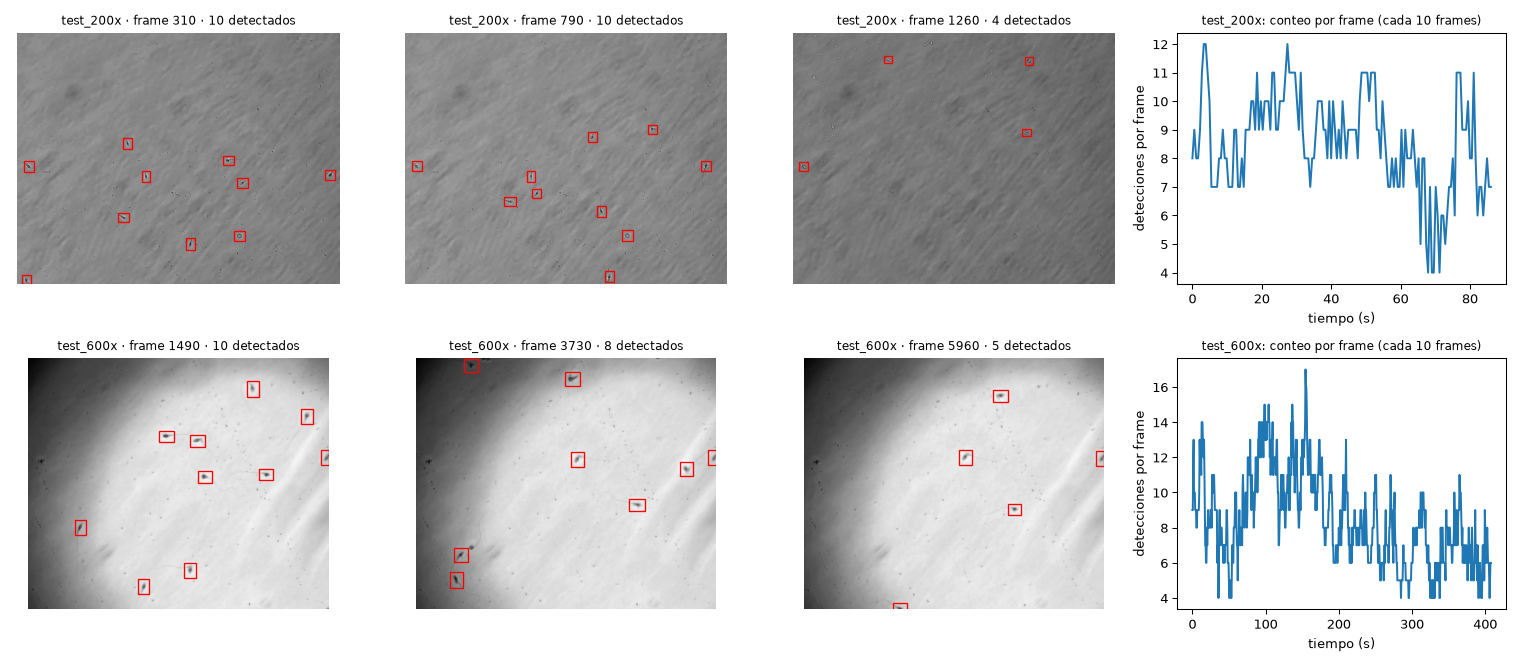

,frames_muestreados,media,desv,minimo,maximo,resolucion
video,,,,,,
test_200x,158,8.6,1.7,4,12,1200x936
test_600x,745,8.4,2.6,4,17,2448x2048


In [15]:
display(Image(filename=str(FIGURES / "demo_evisan_videos.png")))
display(pd.read_csv(ROOT / "reports" / "evisan_test_videos.csv").set_index("video"))

**Lectura.** En ambos videos el detector marca unas 8 a 9 células por frame (media 8,6 ± 1,7 en `test_200x` y 8,4 ± 2,6 en `test_600x`; rango de 4 a 17), con un conteo que varía de forma gradual y sin saltos entre frames contiguos. En los frames mostrados las cajas caen sobre células. Lo que **no** podemos decir es cuántas se escapan o cuántas son falsos positivos, porque no hay anotación: es evidencia de que el detector generaliza de forma razonable a videos de EVISAN no vistos, no una medida de su precisión.

### 5.1.3 Video anotado de la demostración
Para ver el sistema en funcionamiento se generó un video por participante con las detecciones y las trayectorias de los últimos 2 s, **coloreadas por velocidad** (azul: lenta; naranja y amarillo: rápida), a la velocidad real (`src/demo_video.py`, detector B). Están en `reports/demo/`: el participante 13 (test), el 67 (motilidad alta) y el 80 (casi inmóvil). Aquí se muestra un frame de cada uno.

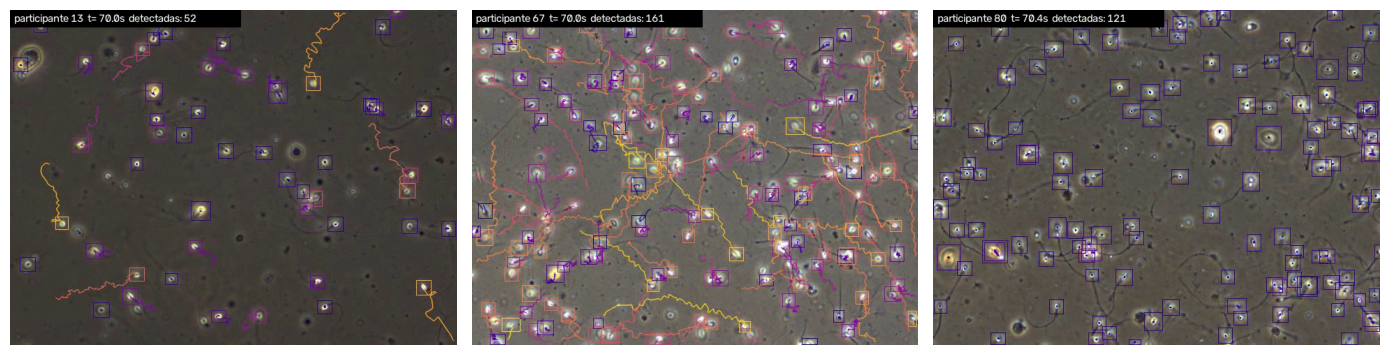

In [16]:
import cv2
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, pid in zip(ax, (13, 67, 80)):
    cap = cv2.VideoCapture(str(ROOT / "reports" / "demo" / f"B_evisan_to_visem_participante_{pid}.mp4")); cap.set(cv2.CAP_PROP_POS_FRAMES, 250)
    ok, fr = cap.read(); cap.release(); a.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); a.axis("off")
plt.tight_layout(); plt.savefig(FIGURES / "demo_video_frames.png", dpi=110); plt.show()

**Lectura.** En el 13 se ven decenas de células, la mayoría con trayectorias cortas y de color frío (lentas) y unas pocas con trayectorias largas y cálidas (rápidas y rectilíneas, las que cuentan como progresivas). En el 67 hay muchas más células y trayectorias largas; en el 80 casi todas son puntos sin recorrido. Es lo que el regresor usa para estimar la motilidad. Los frames son uno por video (el 250 del clip), elegidos por posición, no por resultado.

### 5.2 Calidad del seguimiento (objetivo 1)
Se comparan las trayectorias de YOLO+ByteTrack con las de `labels_ftid` de VISEM-Tracking en los primeros 30 s de los participantes anotados (emparejamiento por IoU ≥ 0,5, `py-motmetrics`). MOTA mide errores de detección y de identidad juntos; IDF1 mide cuánto tiempo se mantiene la identidad correcta. El umbral de confianza (0,4) se eligió comparando 0,10, 0,25 y 0,40 **solo con B en validación**; D se evaluó con ese mismo umbral, sin ajustarlo.

In [17]:
rep = ROOT / "reports"
runs = {"B · validación": "tracking_eval_B_evisan_to_visem_val_conf0.4.csv",
        "D · validación": "tracking_eval_D_evisan_to_visem_960_val_conf0.4.csv",
        "B · test (una evaluación)": "tracking_eval_B_evisan_to_visem_test_conf0.4.csv",
        "D · test (una evaluación)": "tracking_eval_D_evisan_to_visem_960_test_conf0.4.csv"}
tab = {k: pd.read_csv(rep / v, index_col=0) for k, v in runs.items()}
display(pd.DataFrame({k: v.loc["media"] for k, v in tab.items()}).T[["mota", "idf1", "num_switches", "precision", "recall"]].round(3))
print("Detalle por participante (validación: 11, 12, 19, 23; test: 13, 14, 35, 60):")
display(pd.concat({k: v.drop(index="media")[["mota", "idf1", "num_switches"]] for k, v in tab.items()}).round(2))

,mota,idf1,num_switches,precision,recall
B · validación,0.056,0.451,315.75,0.524,0.632
D · validación,0.294,0.511,324.00,0.661,0.655
B · test (una evaluación),0.301,0.558,166.50,0.659,0.629
D · test (una evaluación),0.298,0.559,100.00,0.671,0.575


Detalle por participante (validación: 11, 12, 19, 23; test: 13, 14, 35, 60):


mota  idf1  num_switches
B · validación            11  0.47  0.66         164.0
                          12  0.36  0.39         952.0
                          19 -0.48  0.15         145.0
                          23 -0.13  0.61           2.0
D · validación            11  0.54  0.68         122.0
                          12  0.31  0.36        1010.0
                          19  0.15  0.34         160.0
                          23  0.19  0.67           4.0
B · test (una evaluación) 13  0.45  0.64         119.0
                          14  0.57  0.71          22.0
                          35  0.07  0.44         405.0
                          60  0.12  0.44         120.0
D · test (una evaluación) 13  0.30  0.60         109.0
                          14  0.68  0.76          20.0
                          35  0.26  0.50         183.0
                          60 -0.05  0.37          88.0

**Lectura.**
- En **validación**, D supera a B con claridad (MOTA 0,29 contra 0,06; IDF1 0,51 contra 0,45), pero casi toda la diferencia viene de los participantes **19 y 23**: en el 19 (residuo y células redondas brillantes) B marcaba como espermatozoide lo que no lo era (precisión de 0,22).
- En **test**, B y D **empatan**: MOTA 0,30 y 0,30, IDF1 0,56 y 0,56. La ventaja de D en validación depende de uno o dos participantes con residuo y no se repite en los 4 de test. Es una advertencia concreta sobre lo ruidoso que es elegir con 4 participantes de validación.
- El seguimiento es **imperfecto** en ambos: precisión de ~0,66 y recall de ~0,6 en test, y entre decenas y cientos de cambios de identidad por participante (las trayectorias se parten). Los peores del test son el 35 (MOTA 0,07 con B) y el 60 (0,12 con B; −0,05 con D, donde los errores superan a los objetos anotados). Esto limita la calidad de las características de velocidad.

### 5.3 Estimación de motilidad con características de movimiento (objetivo 2)
Se calcularon 24 características por participante a partir de las trayectorias del detector B sobre los primeros 120 s de cada video (conteo de detecciones y trayectorias, VCL, VAP, VSL, LIN, STR en media, mediana y percentiles, fracción de trayectorias casi quietas, fracción con LIN > 0,5). Se comparan tres regresores con validación cruzada agrupada por participante sobre los 70, y la **referencia trivial** (predecir siempre la media del entrenamiento): un modelo solo es útil si la supera con claridad.

In [18]:
exp = "B_evisan_to_visem"   # detector del sistema final (ver sección 4 y 5.6)
cvt = pd.read_csv(ROOT / "reports" / f"regression_cv_{exp}.csv")
tet = pd.read_csv(ROOT / "reports" / f"regression_test_{exp}.csv")
print("Validación cruzada (70 participantes, 5 folds): MAE en pp")
display(cvt.set_index("model"))
print("Test (15 participantes), una sola evaluación del modelo elegido por CV:")
display(tet.set_index("model"))

Validación cruzada (70 participantes, 5 folds): MAE en pp


,cv_mae_mean,cv_mae_std,mae_prog,mae_nonprog,mae_immot,rmse
model,,,,,,
media_entrenamiento,12.80,1.37,17.01,8.20,13.19,16.52
ridge,7.31,1.16,8.02,7.32,6.59,9.66
random_forest,7.67,1.46,8.62,6.94,7.46,10.17
gradient_boosting,7.62,0.74,8.79,6.73,7.33,9.77


Test (15 participantes), una sola evaluación del modelo elegido por CV:


,test_mae,test_rmse,mae_prog
model,,,
media_entrenamiento,13.22,16.64,17.37
ridge,6.33,8.53,7.58


Para entender qué usa el regresor, la celda siguiente muestra la correlación de cada característica con la motilidad progresiva **solo en los 70 participantes de entrenamiento/validación** (el test no interviene).

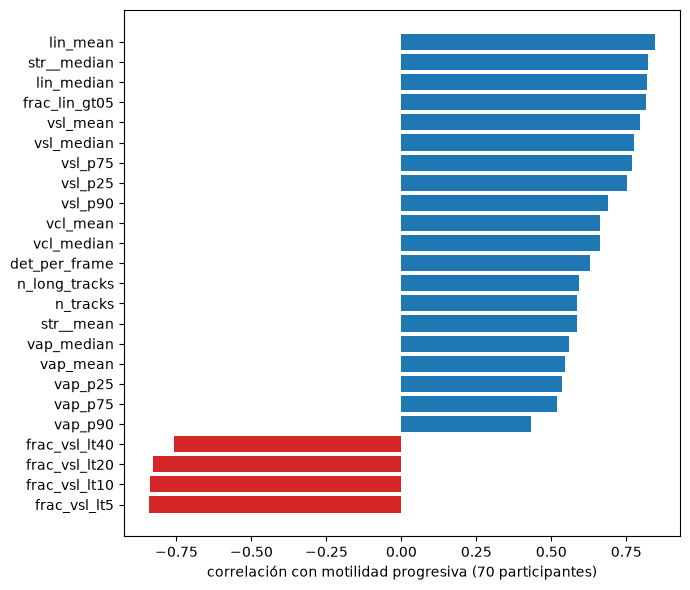

In [19]:
feat = pd.read_csv(PROCESSED / f"features_{exp}.csv").set_index("ID")
tvf = folds.set_index("ID") if "ID" in folds.columns else folds
tvf = tvf[tvf.split == "trainval"]
corr = feat.loc[tvf.index].corrwith(tvf.progressive).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr.index, corr.values, color=["tab:red" if v < 0 else "tab:blue" for v in corr.values])
ax.set_xlabel("correlación con motilidad progresiva (70 participantes)"); plt.tight_layout()
plt.savefig(FIGURES / "correlacion_features.png", dpi=130); plt.show()

**Lectura.** El modelo Ridge supera con claridad a la referencia trivial: MAE de CV de 7,31 ± 1,16 pp frente a 12,80 ± 1,37, y de 6,33 frente a 13,22 en test (RMSE de 8,53 frente a 16,64). Por variable, en CV la progresiva baja de 17,0 a 8,0 y la inmóvil de 13,2 a 6,6. Las características más informativas son las de **linealidad y velocidad neta** (LIN y VSL medias, correlación ≈ 0,8 con la progresiva) y la **fracción de trayectorias casi quietas** (correlación de ≈ −0,8): es lo esperable, porque la motilidad progresiva es movimiento rápido y rectilíneo y la inmóvil es ausencia de movimiento. Los modelos de árboles no mejoran al lineal (7,67 y 7,62 contra 7,31), lo que sugiere una relación mayormente lineal. La **no progresiva** es la variable más difícil (7,3 contra 8,2 del trivial): es una categoría intermedia y la más sujeta al criterio del evaluador.

_Con el detector D el mismo regresor da 7,97 ± 1,20 en CV y 6,81 en test (ver 5.6)._

### 5.3.1 Línea base por reglas, sin aprendizaje de pesos
Una referencia externa (el cuaderno `punya-tat` de la carpeta de referencias) estima la motilidad **clasificando cada trayectoria por umbrales** y contando porcentajes: inmóvil si casi no avanza, progresiva si avanza en línea recta, no progresiva en otro caso. Se replica la idea con dos umbrales (`src/rule_baseline.py`): desplazamiento neto por segundo (VSL) y linealidad (LIN). **No hay pesos que aprender, solo dos números**, y se ajustan con los folds de entrenamiento (en la referencia son fijos y arbitrarios, y su único resultado fue 100 % progresiva en un video con 38 % real). Sirve de contrapeso: ¿cuánto del resultado viene de una regla simple y cuánto del aprendizaje?

In [20]:
from results_utils import load_regression_predictions, load_cnn_predictions, per_participant_error, score, trivial_predictions, load_folds, PRED
F = load_folds()   # folds fijos (se vuelve a usar en 5.4)
rule_cv = pd.read_csv(ROOT / "reports" / "rule_cv_pred_B_evisan_to_visem.csv").set_index("ID")[PRED]
rule_te = pd.read_csv(ROOT / "reports" / "rule_test_pred_B_evisan_to_visem.csv").set_index("ID")[PRED]
display(pd.read_csv(ROOT / "reports" / "rule_thresholds_B_evisan_to_visem.csv").round(2))
ridge_p = load_regression_predictions("B_evisan_to_visem")
cnn_p = load_cnn_predictions([ROOT / "reports" / "baseline_predictions.csv", ROOT / "reports" / "baseline_predictions_s7.csv", ROOT / "reports" / "baseline_predictions_s123.csv"])
mods_r = {"Predictor trivial (media)": trivial_predictions(F), "Regla de 2 umbrales (sin pesos)": (rule_cv, rule_te), "CNN 3D (ensamble)": cnn_p, "Ridge + trayectorias (B)": ridge_p}
display(pd.DataFrame({k: score(*v, F) for k, v in mods_r.items()}).T[["cv_mae", "cv_mae_std", "cv_rmse", "test_mae", "test_rmse"]].round(2))
Er = pd.DataFrame({k: pd.concat([per_participant_error(v[0], F), per_participant_error(v[1], F)]) for k, v in mods_r.items()})
rng_r = np.random.default_rng(42)
for a, b in [("Regla de 2 umbrales (sin pesos)", "Ridge + trayectorias (B)"), ("Regla de 2 umbrales (sin pesos)", "CNN 3D (ensamble)")]:
    d_ = (Er[a] - Er[b]).values; bs_ = [d_[rng_r.integers(0, len(d_), len(d_))].mean() for _ in range(10000)]
    print(f"error({a}) − error({b}) = {d_.mean():+.2f} pp  IC95 [{np.percentile(bs_, 2.5):+.2f}, {np.percentile(bs_, 97.5):+.2f}]  (85 participantes fuera de muestra)")

,fold,t_vsl,t_lin,mae_train
0,0,2.0,0.3,9.34
1,1,2.0,0.3,9.61
2,2,2.0,0.3,9.16
3,3,2.0,0.3,9.37
4,4,3.0,0.3,9.00
5,todos(70),2.0,0.3,9.31


,cv_mae,cv_mae_std,cv_rmse,test_mae,test_rmse
Predictor trivial (media),12.80,1.37,16.52,13.22,16.64
Regla de 2 umbrales (sin pesos),9.50,1.03,11.65,9.21,11.21
CNN 3D (ensamble),9.71,2.28,13.89,7.00,9.58
Ridge + trayectorias (B),7.31,1.16,9.66,6.33,8.53


error(Regla de 2 umbrales (sin pesos)) − error(Ridge + trayectorias (B)) = +2.31 pp  IC95 [+1.23, +3.34]  (85 participantes fuera de muestra)
error(Regla de 2 umbrales (sin pesos)) − error(CNN 3D (ensamble)) = +0.21 pp  IC95 [-1.58, +1.82]  (85 participantes fuera de muestra)


**Lectura.** Una regla de dos umbrales ya reduce el error frente a predecir la media (MAE de CV 9,50 contra 12,80; test 9,21 contra 13,22) y queda **a la par de la CNN 3D de 294 mil parámetros** (9,71 en CV). El Ridge sobre las mismas trayectorias es mejor que la regla (ver la diferencia pareada arriba): aprender cómo combinar 24 características aporta unos 2 pp sobre contar trayectorias con dos umbrales. Los umbrales elegidos son estables entre folds (≈ 2 a 3 píxeles/s de desplazamiento neto y linealidad de 0,3), pero no tienen unidades físicas porque VISEM no trae la escala µm/píxel, así que no son los umbrales de la OMS. Dos conclusiones: (i) **la representación en trayectorias es lo que hace el trabajo pesado**, y (ii) un modelo de video que no supere a una regla de dos parámetros no está aprovechando la señal.

### 5.4 Comparación con la línea base directa (objetivo 3)
Misma partición, mismas métricas. La CNN 3D se reporta con una semilla (42) y como ensamble de las 3 semillas (promedio de predicciones). También se evalúa el promedio simple 50/50 de la CNN y el regresor, con pesos **fijos** (no ajustados).

,cv_mae,cv_mae_std,cv_rmse,test_mae,test_rmse,cv_mae_prog,test_mae_prog
Predictor trivial (media),12.80,1.37,16.52,13.22,16.64,17.01,17.37
CNN 3D (semilla 42),9.76,2.26,14.14,7.11,9.62,10.69,8.09
CNN 3D (ensamble 3 semillas),9.71,2.28,13.89,7.00,9.58,10.56,7.88
Características + Ridge (detector B),7.31,1.16,9.66,6.33,8.53,8.02,7.58
Promedio 50/50 CNN 3D + Ridge,7.80,1.87,10.86,6.39,8.76,7.99,7.25
ResNet18 afinada (anexo A),9.00,2.03,11.94,8.13,10.60,10.55,9.24
ResNet18 sonda lineal (anexo A),10.65,1.99,13.59,9.98,12.85,13.39,11.96
CNN 3D regularizada (anexo B),9.04,2.00,12.10,7.82,10.43,10.19,8.36
Red de conjuntos sobre trayectorias (anexo C),7.18,1.39,9.43,6.45,8.81,8.04,8.00


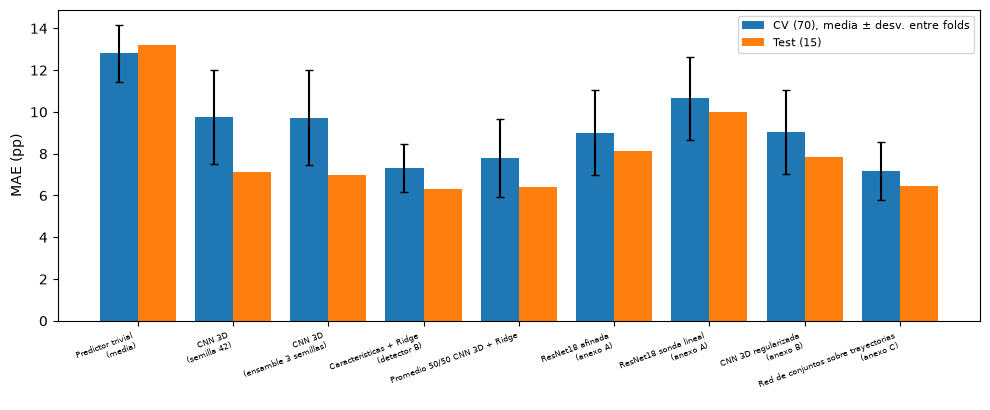

In [21]:
from results_utils import (load_folds, load_cnn_predictions, load_regression_predictions, trivial_predictions,
                           score, per_participant_error, TARGETS, PRED)
F = load_folds()
rep = ROOT / "reports"
cnn1 = load_cnn_predictions([rep / "baseline_predictions.csv"])
cnn3 = load_cnn_predictions([rep / "baseline_predictions.csv", rep / "baseline_predictions_s7.csv", rep / "baseline_predictions_s123.csv"])
ridge = load_regression_predictions(exp)
dl = {n: load_cnn_predictions([rep / f"baseline_predictions_{v}_s{k}.csv" for k in (42, 7, 123)])
      for n, v in {"ResNet18 afinada (anexo A)": "resnet", "ResNet18 sonda lineal (anexo A)": "resnet_probe",
                   "CNN 3D regularizada (anexo B)": "reg3d", "Red de conjuntos sobre trayectorias (anexo C)": "trackset"}.items()}
avg = ((cnn3[0].loc[ridge[0].index] + ridge[0]) / 2, (cnn3[1].loc[ridge[1].index] + ridge[1]) / 2)
models = {"Predictor trivial (media)": trivial_predictions(F), "CNN 3D (semilla 42)": cnn1, "CNN 3D (ensamble 3 semillas)": cnn3,
          "Características + Ridge (detector B)": ridge, "Promedio 50/50 CNN 3D + Ridge": avg} | dl
comp = pd.DataFrame({k: score(*v, folds=F) for k, v in models.items()}).T
comp.to_csv(rep / "comparacion_modelos.csv")
display(comp[["cv_mae", "cv_mae_std", "cv_rmse", "test_mae", "test_rmse", "cv_mae_prog", "test_mae_prog"]].round(2))

fig, ax = plt.subplots(figsize=(10, 4.2)); x = np.arange(len(comp))
ax.bar(x - 0.2, comp.cv_mae, 0.4, yerr=comp.cv_mae_std, label="CV (70), media ± desv. entre folds", capsize=3)
ax.bar(x + 0.2, comp.test_mae, 0.4, label="Test (15)")
ax.set_xticks(x); ax.set_xticklabels([n.replace(" (", "\n(") for n in comp.index], fontsize=6, rotation=20, ha="right"); ax.set_ylabel("MAE (pp)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "comparacion_modelos.png", dpi=130); plt.show()

Con 15 participantes de test, una diferencia de 0,3 o de 1 pp no dice nada por sí sola. Por eso se comparan los modelos de forma **pareada** sobre los 85 participantes fuera de muestra (los 70 de CV, predichos por modelos que no los vieron, y los 15 de test): para cada participante, error con un modelo menos error con el otro, con un intervalo de confianza del 95 % por *bootstrap* de participantes. Si el intervalo incluye 0, la diferencia no se distingue del azar.

In [22]:
rng = np.random.default_rng(SEED)
E = pd.DataFrame({k: pd.concat([per_participant_error(v[0], F), per_participant_error(v[1], F)]) for k, v in models.items()})
def paired(a, b, n=10000):
    d = (E[a] - E[b]).values; bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), *np.percentile(bs, [2.5, 97.5])
R_ = "Características + Ridge (detector B)"
rows = []
for a, b in [("CNN 3D (ensamble 3 semillas)", R_), ("ResNet18 afinada (anexo A)", R_), ("CNN 3D regularizada (anexo B)", R_),
             ("CNN 3D (ensamble 3 semillas)", "ResNet18 afinada (anexo A)"), ("CNN 3D (ensamble 3 semillas)", "CNN 3D regularizada (anexo B)"),
             (R_, "Promedio 50/50 CNN 3D + Ridge")]:
    m, lo, hi = paired(a, b); rows.append(dict(modelo_A=a, modelo_B=b, dif_media_A_menos_B=m, IC95_bajo=lo, IC95_alto=hi, distinguible_de_cero=bool(lo > 0 or hi < 0)))
pd.DataFrame(rows).round(2).to_csv(rep / "comparaciones_pareadas.csv", index=False)
display(pd.DataFrame(rows).round(2))
print("MAE sobre los 85 participantes fuera de muestra:"); print(E.mean().round(2).to_string())

,modelo_A,modelo_B,dif_media_A_menos_B,IC95_bajo,IC95_alto,distinguible_de_cero
0,CNN 3D (ensamble 3 semillas),Características + Ridge (detector B),2.10,0.98,3.42,True
1,ResNet18 afinada (anexo A),Características + Ridge (detector B),1.71,0.83,2.58,True
2,CNN 3D regularizada (anexo B),Características + Ridge (detector B),1.69,0.82,2.57,True
3,CNN 3D (ensamble 3 semillas),ResNet18 afinada (anexo A),0.39,-0.58,1.57,False
4,CNN 3D (ensamble 3 semillas),CNN 3D regularizada (anexo B),0.41,-0.23,1.16,False
5,Características + Ridge (detector B),Promedio 50/50 CNN 3D + Ridge,-0.42,-1.05,0.16,False


MAE sobre los 85 participantes fuera de muestra:
Predictor trivial (media)                        12.87
CNN 3D (semilla 42)                               9.29
CNN 3D (ensamble 3 semillas)                      9.24
Características + Ridge (detector B)              7.14
Promedio 50/50 CNN 3D + Ridge                     7.55
ResNet18 afinada (anexo A)                        8.84
ResNet18 sonda lineal (anexo A)                  10.53
CNN 3D regularizada (anexo B)                     8.82
Red de conjuntos sobre trayectorias (anexo C)     7.05


La siguiente figura contrasta la motilidad progresiva predicha con la real para los dos enfoques, con las predicciones de **validación cruzada** (cada participante predicho por un modelo que no lo vio) y las de test.

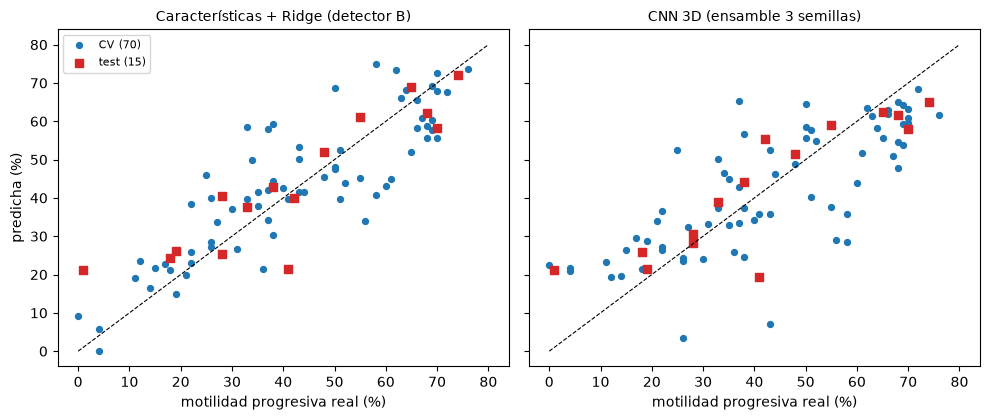

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharex=True, sharey=True)
for ax, (name, (cv, te)) in zip(axes, {"Características + Ridge (detector B)": ridge, "CNN 3D (ensamble 3 semillas)": cnn3}.items()):
    ax.scatter(F.loc[cv.index, "progressive"], cv.pred_progressive, s=18, label="CV (70)")
    ax.scatter(F.loc[te.index, "progressive"], te.pred_progressive, s=26, marker="s", color="tab:red", label="test (15)")
    ax.plot([0, 80], [0, 80], "k--", lw=0.8); ax.set_title(name, fontsize=10); ax.set_xlabel("motilidad progresiva real (%)")
axes[0].set_ylabel("predicha (%)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "pred_vs_real.png", dpi=130); plt.show()

**Lectura.**
- **El método con trayectorias supera de forma significativa a todos los modelos de video directo.** Sobre los 85 participantes fuera de muestra, el error de la CNN 3D menos el del Ridge es de **+2,10 pp (IC 95 % [0,98; 3,42])**; para la ResNet18 afinada, +1,71 [0,83; 2,58]; para la CNN 3D regularizada, +1,69 [0,82; 2,57]. Ninguno de los intervalos incluye 0. En CV el Ridge tiene MAE 7,31 contra 9,71 de la CNN 3D (ensamble), y en test 6,33 contra 7,00.
- **Las variantes de Deep Learning no se distinguen entre sí.** La ResNet afinada y la CNN regularizada mejoran a la CNN 3D base en CV (9,00 y 9,04 contra 9,71) pero empeoran en test (8,13 y 7,82 contra 7,00), y la diferencia pareada sobre los 85 incluye el 0 (+0,39 [−0,58; +1,57] y +0,41 [−0,23; +1,16]). La sonda lineal sobre ResNet congelada es la peor (10,65). El detalle está en los anexos A y B.
- **Deep Learning sobre las trayectorias (anexo C, sección 7).** Una red de conjuntos (Deep Sets, 1.478 parámetros, sin ajuste de hiperparámetros, 3 semillas) obtiene MAE de CV 7,18 ± 1,39 y 6,45 en test: **empata con el Ridge** (diferencia pareada +0,09 [−0,38; 0,53]) y es significativamente mejor que la CNN 3D (+2,19 [1,00; 3,52]). Su error está correlacionado 0,90 con el del Ridge: aprende lo mismo que las características diseñadas a mano.
- **Promediar los dos enfoques no ayuda:** el promedio 50/50 tiene MAE de CV 7,80 contra 7,31 del Ridge solo (en test 6,39 contra 6,33), y la diferencia pareada incluye el 0 (Ridge menos promedio: −0,42 [−1,05; +0,16]).
- **Con 15 participantes de test las diferencias pequeñas no son concluyentes** (la CNN 3D base obtiene 7,00 y el Ridge 6,33 en test; esa diferencia sola no se sostendría), pero sobre los 85 participantes sí lo son.
- **Todas las cifras son frente a un techo de ruido en la etiqueta:** cada video fue evaluado por un solo evaluador y las etiquetas de laboratorio tienen variabilidad entre evaluadores.

### 5.5 Análisis de errores
¿En qué participantes falla cada método, y se parecen? Se usan las predicciones fuera de muestra de los 85 participantes (CV + test). Se miran el evaluador, la nota de calidad del video y el sesgo en motilidad alta y baja.

In [24]:
e_ridge = pd.concat([per_participant_error(ridge[0], F), per_participant_error(ridge[1], F)])
e_cnn = pd.concat([per_participant_error(cnn3[0], F), per_participant_error(cnn3[1], F)])
d = F.loc[e_ridge.index, ["progressive", "evaluator", "quality_note", "has_tracking", "split"]].assign(err_ridge=e_ridge, err_cnn=e_cnn)
print(f"Correlación entre el error de Ridge y el de la CNN por participante: {d.err_ridge.corr(d.err_cnn):.2f}")
print("\nError medio (pp) por evaluador:")
display(d.groupby("evaluator").agg(n=("err_ridge", "size"), ridge=("err_ridge", "mean"), cnn=("err_cnn", "mean")).round(1))
print("Error medio con y sin nota de calidad de video (drift / debris):")
display(d.assign(nota=d.quality_note.notna()).groupby("nota").agg(n=("err_ridge", "size"), ridge=("err_ridge", "mean"), cnn=("err_cnn", "mean")).round(1))
print("Los 8 participantes con mayor error del regresor:")
display(d.sort_values("err_ridge", ascending=False).head(8).round(1))
bias = pd.DataFrame({"n": [(d.progressive >= 50).sum(), (d.progressive < 15).sum()]}, index=["progresiva ≥ 50 %", "progresiva < 15 %"])
for name, (cv, te) in {"sesgo Ridge (pred − real, pp)": ridge, "sesgo CNN 3D (pred − real, pp)": cnn3}.items():
    allp = pd.concat([cv, te]); err = allp.pred_progressive - F.loc[allp.index, "progressive"]
    bias[name] = [err[F.loc[allp.index, "progressive"] >= 50].mean(), err[F.loc[allp.index, "progressive"] < 15].mean()]
display(bias.round(1))

Correlación entre el error de Ridge y el de la CNN por participante: 0.72

Error medio (pp) por evaluador:


,n,ridge,cnn
evaluator,,,
HH,18,7.0,11.4
IVS,3,5.8,10.9
JMA,27,5.5,6.7
OW,7,10.1,9.4
SSW,30,8.1,10.0


Error medio con y sin nota de calidad de video (drift / debris):


,n,ridge,cnn
nota,,,
False,72,6.6,7.9
True,13,10.0,16.4


Los 8 participantes con mayor error del regresor:


,progressive,evaluator,quality_note,has_tracking,split,err_ridge,err_cnn
ID,,,,,,,
7,0,HH,minor drift,False,trainval,25.8,45.5
12,33,SSW,NaN,True,trainval,18.0,18.5
35,1,OW,NaN,True,test,16.8,16.1
11,11,JMA,NaN,True,trainval,15.2,18.6
14,41,SSW,NaN,True,test,14.9,20.9
22,56,SSW,NaN,True,trainval,14.7,18.1
37,38,SSW,NaN,False,trainval,14.2,12.5
25,37,IVS,NaN,False,trainval,14.1,18.8


,n,"sesgo Ridge (pred − real, pp)","sesgo CNN 3D (pred − real, pp)"
progresiva ≥ 50 %,35,-4.4,-7.7
progresiva < 15 %,7,7.0,14.6


**Hallazgos del análisis de errores.**
- **Los dos enfoques fallan en los mismos participantes** (correlación del error por participante: 0,72). Los peores del regresor son el 7, el 12, el 35, el 11 y el 14. El participante **7** (0 % progresiva, 96 % inmóvil, el valor más extremo de todo el conjunto) es el caso más difícil: el regresor estima ~57 % de inmóvil y la CNN ~28 %. Que ambos se equivoquen igual sugiere que el límite está en la información disponible (características y etiquetas), más que en el modelo; el evaluador, como variable, no explica el error (anexo C), así que no se puede afirmar que sea ruido de etiqueta.
- **Cinco de los ocho peores del regresor son participantes con cajas de VISEM-Tracking** (12, 35, 11, 14, 22). Esos 20 participantes tienen una motilidad progresiva media de 25,9 % (frente a 42,7 % en los 85), y los modelos tienden a sobreestimar la motilidad baja: es una explicación plausible, no verificada.
- **Videos con nota de calidad (*drift*, residuo; 13 de 85):** el error del regresor es de 10,0 pp contra 6,6 sin nota; el de la CNN 3D, de 16,4 contra 7,9. La CNN sufre mucho más. El anexo C (sección 6) prueba si la corrección de deriva del pipeline de trayectorias explica esa diferencia.
- **Evaluador:** el menor error es con JMA para ambos (5,5 con el regresor y 6,7 con la CNN, 27 participantes) y el mayor con OW en el regresor (10,1, solo 7 participantes). Con tan pocos participantes por evaluador no se puede separar el efecto del evaluador del de las muestras, pero es coherente con que el criterio de cada evaluador añada ruido a la etiqueta.
- **Contracción hacia la media:** los participantes con motilidad progresiva ≥ 50 % se subestiman (−4,4 pp con el regresor, −7,7 con la CNN) y los de < 15 % se sobreestiman (+7,0 y +14,6). Es un efecto típico de modelos entrenados con pocos participantes y etiquetas ruidosas; el regresor lo sufre menos.

### 5.5.1 Relación con la concentración de laboratorio
Se revisa si el error se relaciona con la concentración. La concentración de espermatozoides (millones por mL, medida de laboratorio, disponible en los 85 participantes) sirve además como **comprobación externa del detector**: si detecta bien, el número de células detectadas por frame debería crecer con la concentración, aunque el detector nunca vio esa variable.

,Spearman: detecciones por frame,Spearman: nº de trayectorias
A · solo EVISAN,0.43,0.67
B · EVISAN → VISEM,0.82,0.75
D · EVISAN → VISEM (960 px),0.80,0.74


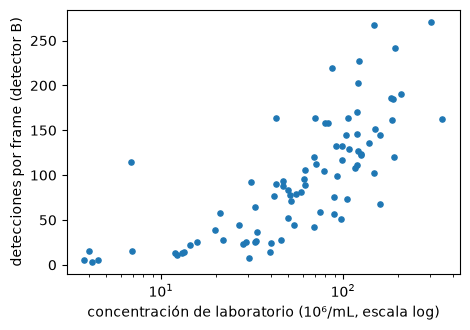

,concentración,Ridge + trayectorias (B),CNN 3D,n
nivel,,,,
baja,22.8,8.5,12.9,29
media,69.0,7.1,7.4,28
alta,154.2,5.7,7.3,28


Spearman(concentración, error) · Ridge + trayectorias (B): -0.23 (p = 0.036)
Spearman(concentración, error) · CNN 3D: -0.20 (p = 0.070)


In [25]:
from scipy.stats import spearmanr
from results_utils import load_regression_predictions, load_cnn_predictions, per_participant_error
sa = pd.read_csv(VISEM_DIR / "semen_analysis_data.csv", sep=";", decimal=",", encoding="utf-8-sig").set_index("ID")
conc = pd.to_numeric(sa["Sperm concentration (x10⁶/mL)"], errors="coerce")
rows = {}
for name, e in {"A · solo EVISAN": "A_evisan_only", "B · EVISAN → VISEM": "B_evisan_to_visem", "D · EVISAN → VISEM (960 px)": "D_evisan_to_visem_960"}.items():
    ft = pd.read_csv(PROCESSED / f"features_{e}.csv").set_index("ID")
    rows[name] = {"Spearman: detecciones por frame": spearmanr(ft.det_per_frame, conc.loc[ft.index])[0],
                  "Spearman: nº de trayectorias": spearmanr(ft.n_tracks, conc.loc[ft.index])[0]}
display(pd.DataFrame(rows).T.round(2))
fb = pd.read_csv(PROCESSED / "features_B_evisan_to_visem.csv").set_index("ID")
fig, ax = plt.subplots(figsize=(4.8, 3.4)); ax.scatter(conc.loc[fb.index], fb.det_per_frame, s=14); ax.set_xscale("log")
ax.set_xlabel("concentración de laboratorio (10⁶/mL, escala log)"); ax.set_ylabel("detecciones por frame (detector B)")
plt.tight_layout(); plt.savefig(FIGURES / "conc_vs_detecciones.png", dpi=130); plt.show()
# error de motilidad por nivel de concentración
E_ = lambda p: pd.concat([per_participant_error(p[0], F), per_participant_error(p[1], F)])
cnn_ = load_cnn_predictions([ROOT / "reports" / "baseline_predictions.csv", ROOT / "reports" / "baseline_predictions_s7.csv", ROOT / "reports" / "baseline_predictions_s123.csv"])
d = pd.DataFrame({"concentración": conc, "Ridge + trayectorias (B)": E_(load_regression_predictions("B_evisan_to_visem")), "CNN 3D": E_(cnn_)}).dropna()
d["nivel"] = pd.qcut(d["concentración"], 3, labels=["baja", "media", "alta"])
display(d.groupby("nivel")[["concentración", "Ridge + trayectorias (B)", "CNN 3D"]].mean().round(1).join(d.groupby("nivel").size().rename("n")))
for m in ("Ridge + trayectorias (B)", "CNN 3D"):
    r, p = spearmanr(d["concentración"], d[m]); print(f"Spearman(concentración, error) · {m}: {r:.2f} (p = {p:.3f})")

**Lectura.**
- **El detector refleja la concentración real.** Con B, las detecciones por frame correlacionan 0,82 (Spearman) con la concentración de laboratorio, y el número de trayectorias 0,75; con D, 0,80 y 0,74. Con A, que no transfiere, la correlación por frame es mucho menor (0,43), aunque el número de trayectorias conserva 0,67. Es una validación independiente de que B y D cuentan células de forma coherente, **sin que el detector haya visto nunca la concentración**. Matiz: la mayoría de los 20 participantes con cajas de VISEM-Tracking se usó para entrenar o validar el detector, de modo que parte de esa correlación es en la muestra.
- **El error de motilidad es mayor en las muestras de baja concentración.** El error medio del Ridge es 8,5 pp en el tercio de menor concentración (3,8 a 43 millones/mL), 7,1 en el medio y 5,7 en el de mayor concentración; la CNN 3D pasa de 12,9 a 7,3. La correlación de Spearman entre concentración y error es de −0,23 para el Ridge (p = 0,036) y −0,20 para la CNN 3D (p = 0,07): una asociación débil y de significación límite. Una explicación plausible (no probada) es que con pocas células hay pocas trayectorias y los porcentajes por muestra son más ruidosos.

### 5.6 Hallazgo: mejor detección o seguimiento no implicó mejor estimación de motilidad
Se repite el mismo regresor (Ridge, CV de 70) con las trayectorias de cada detector. Los detalles, con una comparación pareada y ablaciones, están en el anexo C.

In [26]:
from motility_regression import fit_predict
from results_utils import PRED, score
def ridge_preds(e):
    # el mismo Ridge para los tres detectores: CV con los folds fijos y, aparte, entrenado con los 70 y aplicado al test
    ft = pd.read_csv(ROOT / "data" / "processed" / f"features_{e}.csv").set_index("ID"); cols = list(ft.columns)
    d = F[["split", "fold"] + TARGETS].join(ft); tvd, ted = d[d.split == "trainval"], d[d.split == "test"]
    cv = pd.DataFrame(index=tvd.index, columns=PRED, dtype=float)
    for k in sorted(tvd.fold.unique()):
        tr, va = tvd[tvd.fold != k], tvd[tvd.fold == k]
        cv.loc[va.index] = fit_predict("ridge", tr[cols].values, tr[TARGETS].values, va[cols].values)
    return cv, pd.DataFrame(fit_predict("ridge", tvd[cols].values, tvd[TARGETS].values, ted[cols].values), index=ted.index, columns=PRED)
rows = {}
evr = pd.read_csv(rep / "detector_eval.csv")
for name, e in {"A · solo EVISAN (640 px)": "A_evisan_only", "B · EVISAN → VISEM (640 px)": "B_evisan_to_visem", "D · EVISAN → VISEM (960 px)": "D_evisan_to_visem_960"}.items():
    sc = score(*ridge_preds(e), F)
    r_ = evr[(evr.experiment == e) & (evr.eval_set == "VISEM_test")].iloc[0]
    rows[name] = {"mAP@0.5 VISEM-test": r_.mAP50, "MOTA val": pd.read_csv(rep / f"tracking_eval_{e}_val_conf0.4.csv", index_col=0).loc["media", "mota"],
                  "MAE CV (70)": sc["cv_mae"], "± entre folds": sc["cv_mae_std"], "MAE test (15)": sc["test_mae"]}
display(pd.DataFrame(rows).T.round(3))

,mAP@0.5 VISEM-test,MOTA val,MAE CV (70),± entre folds,MAE test (15)
A · solo EVISAN (640 px),0.264,-0.816,8.100,2.369,7.201
B · EVISAN → VISEM (640 px),0.470,0.056,7.308,1.163,6.331
D · EVISAN → VISEM (960 px),0.492,0.294,7.970,1.196,6.809


**Lectura.** Con el mismo Ridge, **un detector mucho peor no arruina la estimación**: A (MOTA de −0,82 en validación, mAP@0,5 de 0,26 en VISEM-test) da MAE de CV 8,10 contra 7,31 de B y 7,97 de D, y el predictor trivial da 12,80. Las diferencias pareadas sobre los 85 participantes fuera de muestra son B mejor que D en 0,63 pp [0,29; 1,01] y B mejor que A en 0,81 pp [0,02; 1,62]. D, que ganó en seguimiento sobre validación, no es mejor para la tarea final. La explicación más plausible (no probada) es que las características de motilidad son estadísticos agregados sobre cientos de células y toleran falsos positivos y trayectorias partidas; lo que sí mostró el análisis es que MOTA e IDF1 medidos con 4 participantes no predijeron el resultado final. El MAE de test de A se calculó con este Ridge solo para describir, nunca para elegir. Detalle y ablaciones en el anexo C.

### 5.7 Casos: cómo se ve y dónde falla
Cada figura muestra un frame real del video (t = 60 s) con las trayectorias detectadas de los últimos 3 s, coloreadas por su velocidad, y al lado la motilidad real de laboratorio frente a la estimada por cada método. Las predicciones son fuera de muestra: el modelo que predice a cada participante no lo vio. Se eligieron **por criterio, no a dedo**: los mejores aciertos con motilidad alta (67) y baja (80), los peores errores (7 y 35) y los dos participantes problemáticos del seguimiento (19 y 60). Las imágenes quedan en `reports/figures/casos/`.

,real_progressive,real_non_progressive,real_immotile,R_prog,R_nopro,R_inmov,C_prog,C_nopro,C_inmov,evaluador,nota
ID,,,,,,,,,,,
67,69,18,13,69,19,12,64,21,15,JMA,NaN
80,4,15,81,6,25,70,21,31,49,JMA,NaN
7,0,4,96,9,33,57,22,50,28,HH,minor drift
35,1,26,73,21,31,48,21,30,49,OW,NaN
19,58,19,23,41,31,28,29,33,38,JMA,NaN
60,19,44,37,26,33,40,21,33,46,JMA,NaN


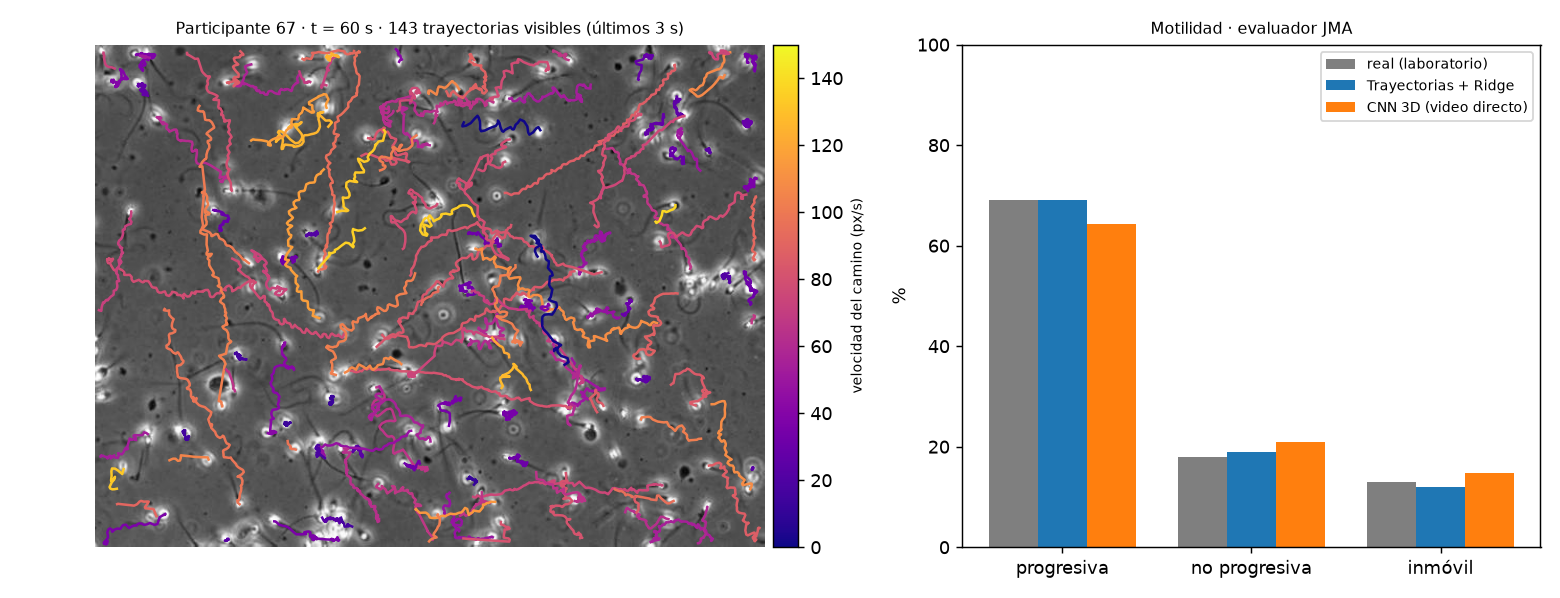

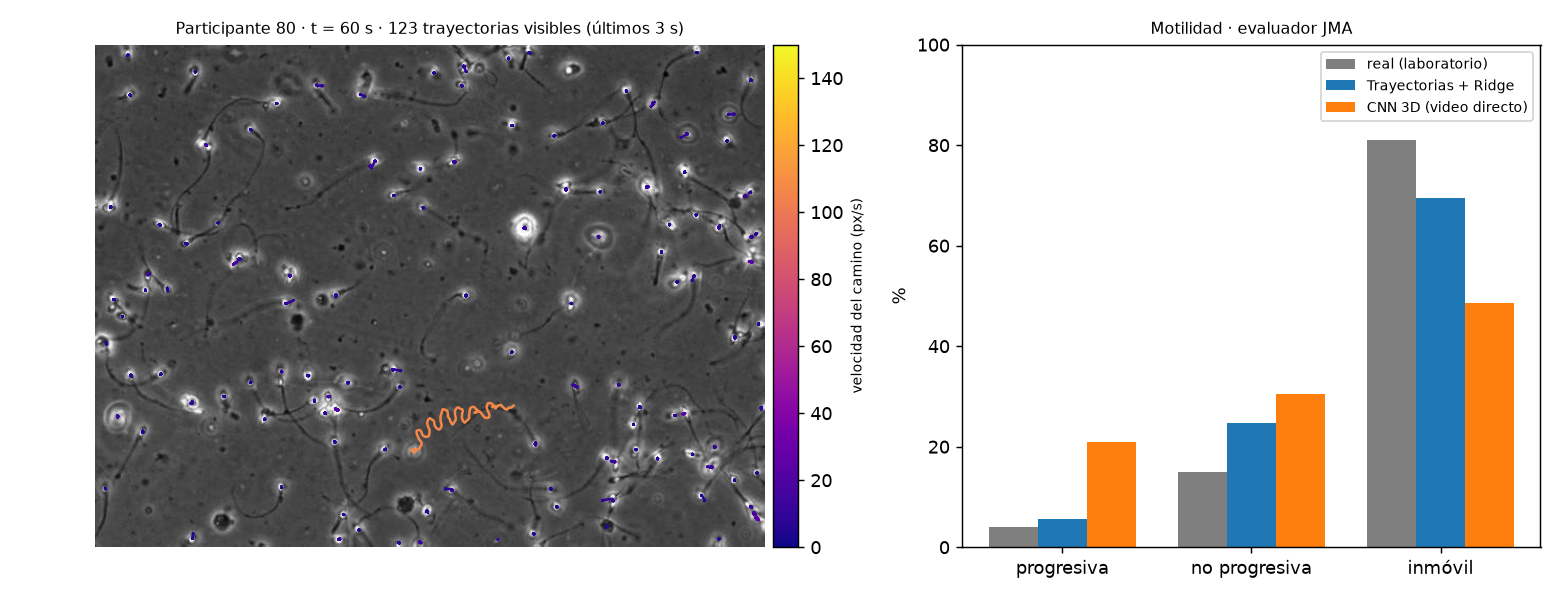

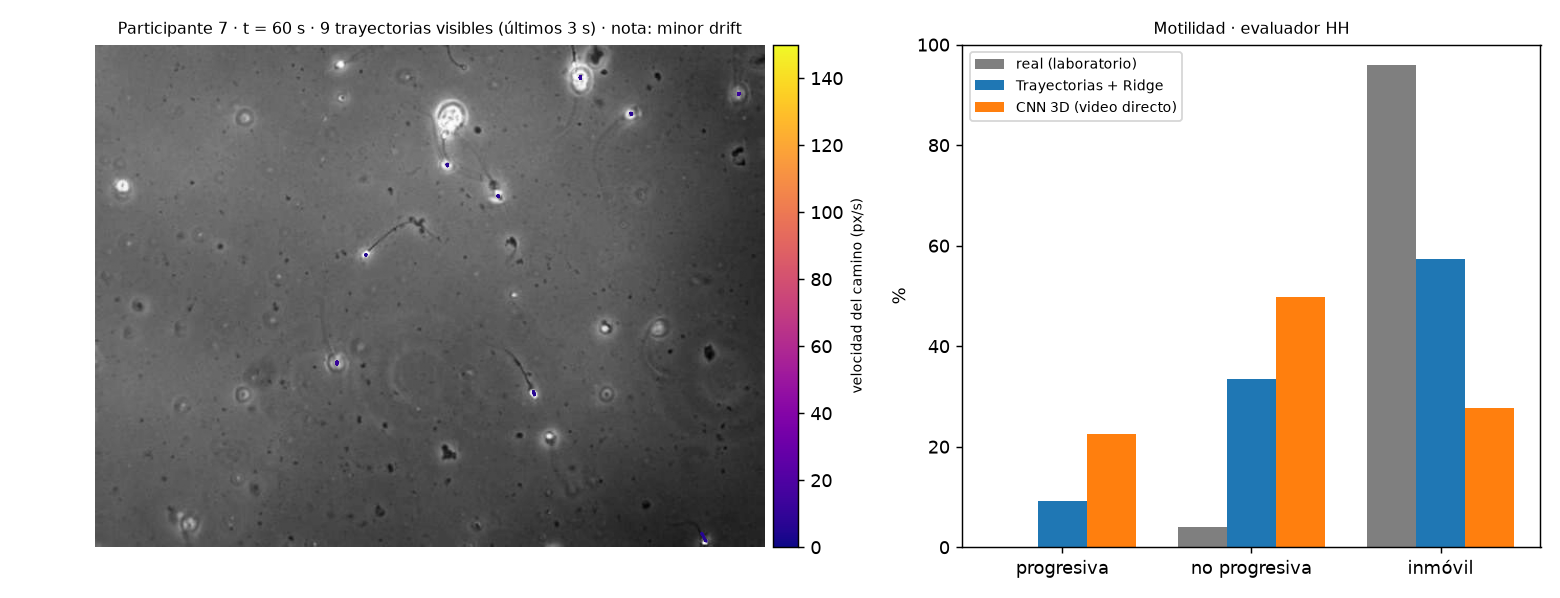

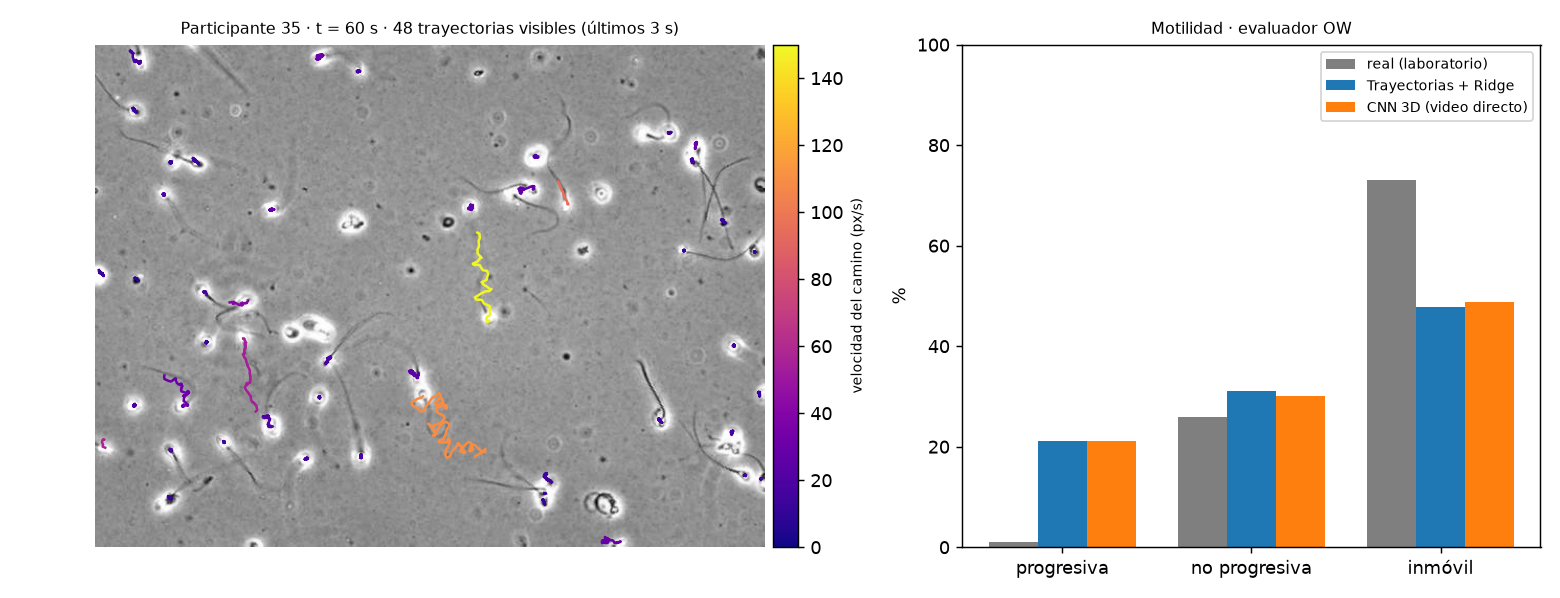

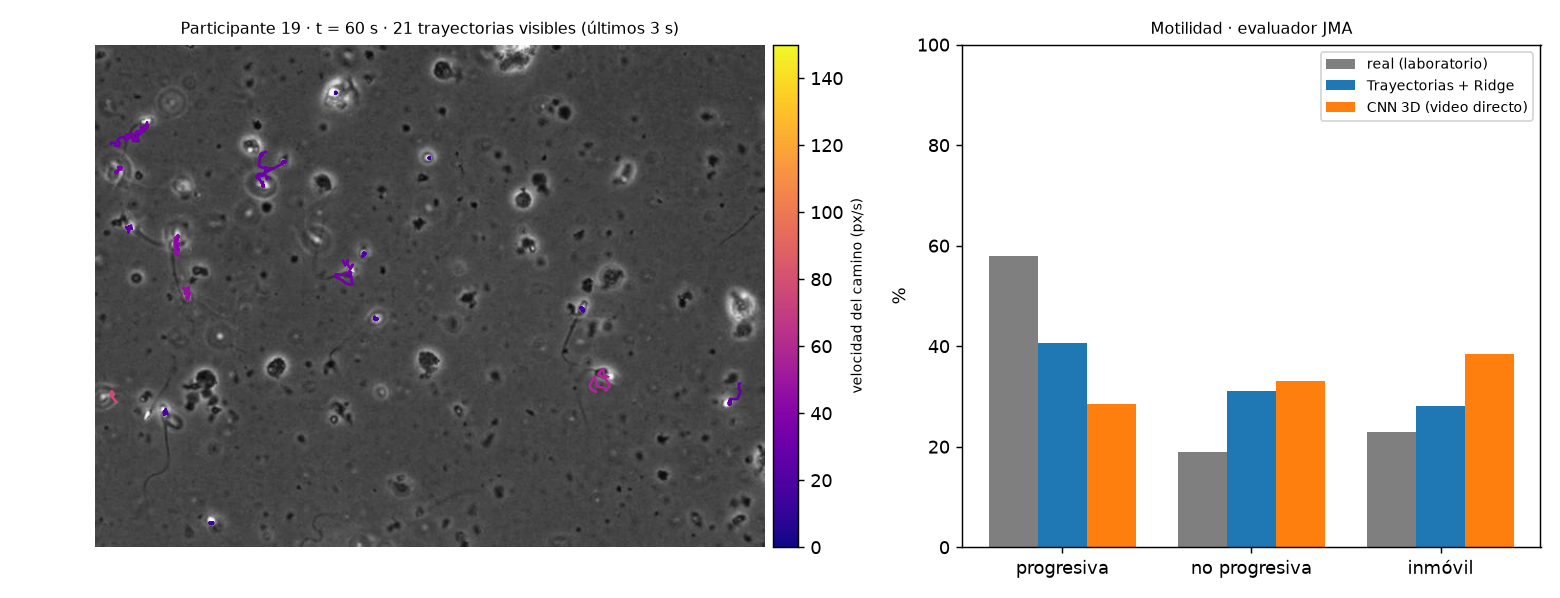

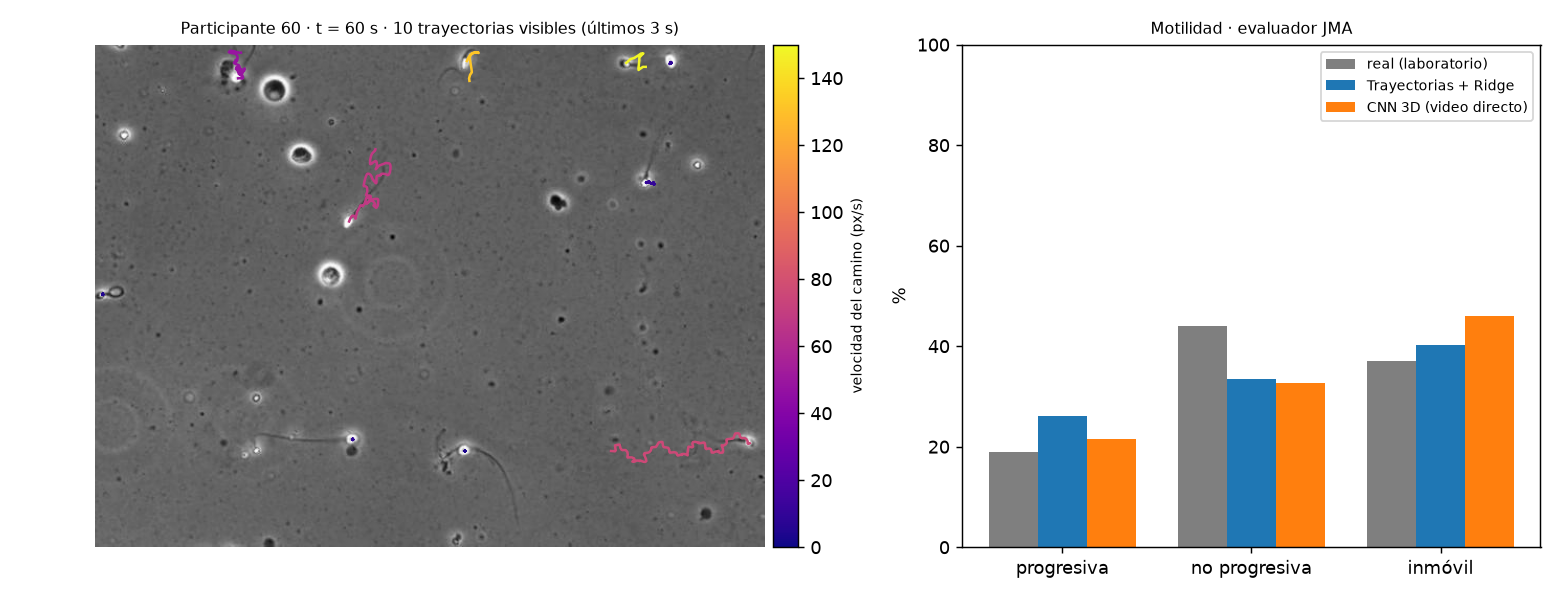

In [27]:
from IPython.display import Image
cases = [67, 80, 7, 35, 19, 60]
pr = {"real": F.loc[cases, TARGETS].round(0).astype(int).add_prefix("real_"),
      "Ridge": pd.concat(ridge).loc[cases, PRED].round(0).astype(int).set_axis(["R_prog", "R_nopro", "R_inmov"], axis=1),
      "CNN 3D": pd.concat(cnn3).loc[cases, PRED].round(0).astype(int).set_axis(["C_prog", "C_nopro", "C_inmov"], axis=1)}
display(pd.concat(pr.values(), axis=1).assign(evaluador=F.loc[cases, "evaluator"], nota=F.loc[cases, "quality_note"]))
for pid in cases:
    display(Image(filename=str(FIGURES / "casos" / f"caso_{pid}.png")))

**Qué enseña cada caso.**
- **67 (motilidad alta, acierto):** 143 trayectorias visibles, largas y rápidas (colores cálidos). El regresor acierta casi exacto y la CNN queda un poco por debajo.
- **80 (motilidad baja, acierto):** 123 células detectadas y casi todas inmóviles (puntos); solo una nada con claridad. El regresor estima ~70 % de inmóviles (real 81 %), mientras la CNN llega solo a ~48 %: es el caso donde ver las trayectorias individuales marca la diferencia.
- **7 (el peor caso):** casi no hay movimiento (9 trayectorias, todas quietas), pero el laboratorio registró 96 % inmóvil y ambos modelos se quedan cortos: es el valor más extremo y los modelos contraen hacia la media. Además tiene nota de *drift*.
- **35 (test, motilidad baja):** hay unas pocas células que sí avanzan rápido (trayectorias amarilla y naranja) y los dos métodos estiman ~21 % de progresiva frente a 1 % registrado. Es un ejemplo de cómo unas pocas células rápidas en una muestra mayormente quieta confunden a ambos métodos.
- **19 (residuo):** el video está lleno de residuo y células redondas brillantes y solo se siguen ~21 trayectorias; la motilidad real (58 % progresiva) se subestima. Es el participante que hacía fallar al detector sin afinar.
- **60 (test, pocas células):** muestra con pocas células (10 trayectorias visibles). Es de los peores del test en seguimiento (MOTA de 0,12 con B y −0,05 con D) y aun así las estimaciones de motilidad quedan razonables (error de ~7 pp).

### 5.8 Historial: cómo llegamos al mejor resultado
Cada fila es un paso del proyecto, en el orden en que se hizo, con su error en validación cruzada (70 participantes) y en test (15). **La tabla y la figura se calculan a partir de las predicciones guardadas**, no están escritas a mano. La columna de decisión recoge lo que aprendimos y por qué se siguió por un camino y no por otro; incluye los intentos que no funcionaron, que son parte del resultado.

,intento,MAE_CV,sd_folds,MAE_test,decision
paso,,,,,
0,Referencia: predecir siempre la media,12.80,1.37,13.22,Piso: todo modelo debe superarlo.
1,Regla de 2 umbrales sobre trayectorias (B),9.50,1.03,9.21,Sin pesos que aprender ya reduce el error: las trayectorias contienen la señal.
2,"CNN 3D sobre video (línea base, 3 semillas)",9.71,2.28,7.00,"Aprende, pero sobreajusta: el entrenamiento mejora y la validación no."
3,ResNet18 preentrenada sobre imágenes de movimiento,9.00,2.03,8.13,Mejora la CV y no el test; no se distingue de la línea base.
4,CNN 3D regularizada,9.04,2.00,7.82,"Menos sobreajuste, pero predicciones más conservadoras; mismo nivel."
5,"r3d_18 preentrenado en video (24,9 M parámetros)",9.59,2.45,7.18,El preentrenamiento en video no ayuda; sobreajusta. Se cierra el video directo.
6,"Trayectorias + Ridge, detector A (solo EVISAN)",8.10,2.37,7.20,"Incluso con un detector que no transfiere (MOTA −0,82) las trayectorias bastan para ganar al video."
7,"Trayectorias + Ridge, detector D (960 px)",7.97,1.20,6.81,"Ganó en seguimiento sobre validación, pero no en la tarea final."
8,"Trayectorias + Ridge, detector B (EVISAN → VISEM)",7.31,1.16,6.33,"Mejor detector para la tarea final, elegido por CV (decisión posterior a ver D)."


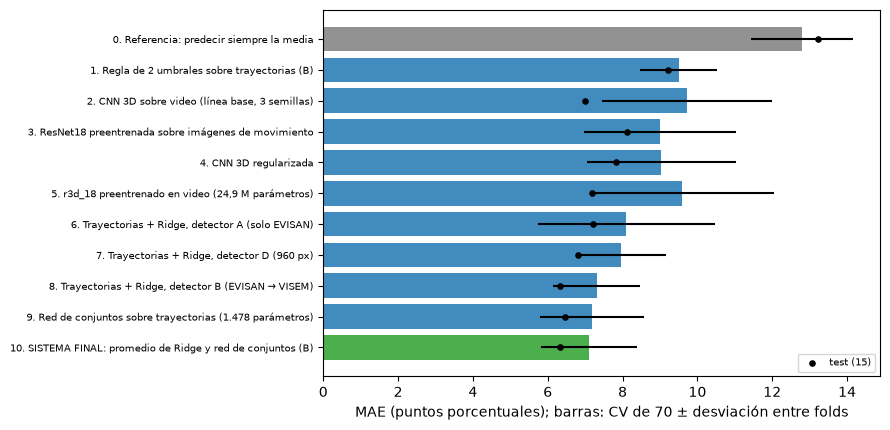

error(CNN 3D sobre video (línea base, 3 semillas)) − error(sistema final) = +2.27 pp  IC95 [+1.16, +3.62]  (85 participantes fuera de muestra)
error(Trayectorias + Ridge, detector B (EVISAN → VISEM)) − error(sistema final) = +0.17 pp  IC95 [-0.06, +0.39]  (85 participantes fuera de muestra)
error(Red de conjuntos sobre trayectorias (1.478 parámetros)) − error(sistema final) = +0.08 pp  IC95 [-0.16, +0.32]  (85 participantes fuera de muestra)


In [28]:
from results_utils import load_regression_predictions, load_cnn_predictions, per_participant_error, score, trivial_predictions
SEEDS_ = (42, 7, 123)
ld = lambda v: load_cnn_predictions([ROOT / "reports" / f"baseline_predictions_{v}_s{k}.csv" for k in SEEDS_])
cnn_h = load_cnn_predictions([ROOT / "reports" / "baseline_predictions.csv", ROOT / "reports" / "baseline_predictions_s7.csv", ROOT / "reports" / "baseline_predictions_s123.csv"])
ridge_B = ridge_preds("B_evisan_to_visem"); sets_h = ld("trackset")
avg_h = ((ridge_B[0] + sets_h[0]) / 2, (ridge_B[1] + sets_h[1]) / 2)
steps = [
 ("Referencia: predecir siempre la media", trivial_predictions(F), "Piso: todo modelo debe superarlo."),
 ("Regla de 2 umbrales sobre trayectorias (B)", (rule_cv, rule_te), "Sin pesos que aprender ya reduce el error: las trayectorias contienen la señal."),
 ("CNN 3D sobre video (línea base, 3 semillas)", cnn_h, "Aprende, pero sobreajusta: el entrenamiento mejora y la validación no."),
 ("ResNet18 preentrenada sobre imágenes de movimiento", ld("resnet"), "Mejora la CV y no el test; no se distingue de la línea base."),
 ("CNN 3D regularizada", ld("reg3d"), "Menos sobreajuste, pero predicciones más conservadoras; mismo nivel."),
 ("r3d_18 preentrenado en video (24,9 M parámetros)", ld("r3d"), "El preentrenamiento en video no ayuda; sobreajusta. Se cierra el video directo."),
 ("Trayectorias + Ridge, detector A (solo EVISAN)", ridge_preds("A_evisan_only"), "Incluso con un detector que no transfiere (MOTA −0,82) las trayectorias bastan para ganar al video."),
 ("Trayectorias + Ridge, detector D (960 px)", ridge_preds("D_evisan_to_visem_960"), "Ganó en seguimiento sobre validación, pero no en la tarea final."),
 ("Trayectorias + Ridge, detector B (EVISAN → VISEM)", ridge_B, "Mejor detector para la tarea final, elegido por CV (decisión posterior a ver D)."),
 ("Red de conjuntos sobre trayectorias (1.478 parámetros)", sets_h, "Deep Learning sobre el método ganador: empata con el Ridge."),
 ("SISTEMA FINAL: promedio de Ridge y red de conjuntos (B)", avg_h, "Menor error de CV; elegido por CV, no por test. La diferencia con el Ridge solo no es distinguible."),
]
rows = []
for k, (name, pred, note) in enumerate(steps):
    sc = score(*pred, F); rows.append(dict(paso=k, intento=name, MAE_CV=sc["cv_mae"], sd_folds=sc["cv_mae_std"], MAE_test=sc["test_mae"], decision=note))
H = pd.DataFrame(rows).set_index("paso"); pd.set_option("display.max_colwidth", 120)
display(H.round(2))
fig, ax = plt.subplots(figsize=(9, 4.4)); y = np.arange(len(H))[::-1]
ax.barh(y, H.MAE_CV, xerr=H.sd_folds, color=["tab:gray"] + ["tab:blue"] * (len(H) - 2) + ["tab:green"], alpha=0.85)
ax.scatter(H.MAE_test, y, color="k", zorder=3, s=14, label="test (15)")
ax.set_yticks(y); ax.set_yticklabels([f"{i}. {n}" for i, n in zip(H.index, H.intento)], fontsize=7); ax.set_xlabel("MAE (puntos porcentuales); barras: CV de 70 ± desviación entre folds")
ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.savefig(FIGURES / "historial_mae.png", dpi=130); plt.show()
Eh = pd.DataFrame({n: pd.concat([per_participant_error(p[0], F), per_participant_error(p[1], F)]) for n, p, _ in steps})
fin = Eh.iloc[:, -1]; rng_h = np.random.default_rng(42)
for n in (Eh.columns[2], Eh.columns[-3], Eh.columns[-2]):
    d_ = (Eh[n] - fin).values; bs_ = [d_[rng_h.integers(0, len(d_), len(d_))].mean() for _ in range(10000)]
    print(f"error({n}) − error(sistema final) = {d_.mean():+.2f} pp  IC95 [{np.percentile(bs_, 2.5):+.2f}, {np.percentile(bs_, 97.5):+.2f}]  (85 participantes fuera de muestra)")

**Cómo se lee.** (1) Lo que más pesa es **pasar de video a trayectorias**: una regla de dos umbrales ya queda al nivel de la CNN 3D de video (diferencia no distinguible, +0,21 pp [−1,58; 1,82]), y aprender sobre las trayectorias (Ridge) mejora a la regla en 2,31 pp [1,23; 3,34]. (2) **Cambiar de arquitectura de video** (preentrenar, regularizar, afinar) no mueve el resultado: todas quedan entre 9 y 9,7. (3) **Cambiar de detector** mueve poco (7,3 a 8,1) aunque el seguimiento sea muy distinto. (4) **Deep Learning sobre las trayectorias** iguala al Ridge, y el promedio de ambos es el mejor número, pero sin una ventaja distinguible; por eso se declara como sistema final el promedio (es de punta a punta una red neuronal más un ancla lineal) sabiendo que el Ridge solo sería igual de defendible. El sistema final se eligió por validación cruzada y **no por el test**.

**Versión resumida.** Los 11 pasos se agrupan en cuatro hitos; la figura compara además con los resultados publicados (que usan otras particiones; ver 5.10).

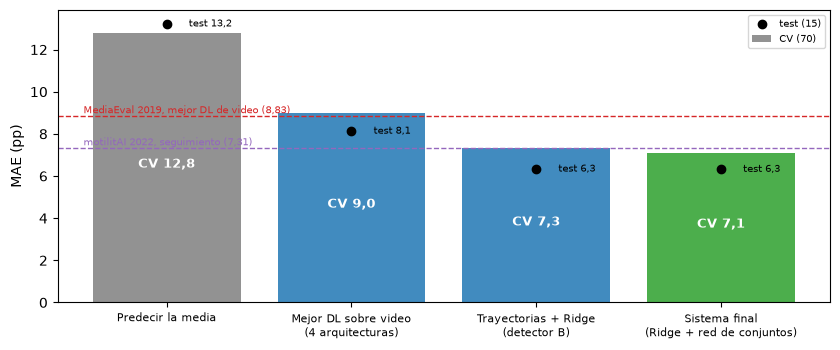

In [29]:
hitos = [("Predecir la media", H.loc[0, "MAE_CV"], H.loc[0, "MAE_test"]), ("Mejor DL sobre video\n(4 arquitecturas)", H.loc[[2, 3, 4, 5], "MAE_CV"].min(), H.loc[H.loc[[2, 3, 4, 5], "MAE_CV"].idxmin(), "MAE_test"]),
         ("Trayectorias + Ridge\n(detector B)", H.loc[8, "MAE_CV"], H.loc[8, "MAE_test"]), ("Sistema final\n(Ridge + red de conjuntos)", H.loc[10, "MAE_CV"], H.loc[10, "MAE_test"])]
fig, ax = plt.subplots(figsize=(8.5, 3.6)); x_ = np.arange(len(hitos))
ax.bar(x_, [h[1] for h in hitos], color=["tab:gray", "tab:blue", "tab:blue", "tab:green"], alpha=0.85, label="CV (70)")
ax.scatter(x_, [h[2] for h in hitos], color="k", zorder=3, label="test (15)")
for v_, lab_, c_ in ((8.83, "MediaEval 2019, mejor DL de video (8,83)", "tab:red"), (7.31, "motilitAI 2022, seguimiento (7,31)", "tab:purple")):
    ax.axhline(v_, ls="--", color=c_, lw=1); ax.text(-0.45, v_ + 0.15, lab_, color=c_, fontsize=7, ha="left")
for xi, h in zip(x_, hitos):
    ax.text(xi, h[1] / 2, f"CV {h[1]:.1f}".replace(".", ","), ha="center", fontsize=9, color="white", fontweight="bold")
    ax.text(xi + 0.12, h[2], f"test {h[2]:.1f}".replace(".", ","), va="center", fontsize=7)
ax.set_xticks(x_); ax.set_xticklabels([h[0] for h in hitos], fontsize=8); ax.set_ylabel("MAE (pp)"); ax.legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.savefig(FIGURES / "resumen_presentacion.png", dpi=150); plt.show()

### 5.9 El sistema en uso: de un video a la estimación
`src/predict_video.py` aplica el sistema final a un video: detector B y ByteTrack (120 s) → corrección de deriva → Ridge sobre los 24 descriptores y red de conjuntos sobre las trayectorias → promedio. Devuelve los tres porcentajes, un **intervalo conformal** por variable (90 %, calibrado con los residuos de CV de los 70 participantes de entrenamiento: ±18,6 pp en progresiva, ±15,4 en no progresiva y ±14,2 en inmóvil) y un **aviso** cuando hay pocas trayectorias largas (menos de 1.365, el tercil inferior del entrenamiento): en ese tercio el error de CV del sistema fue de 9,46 pp contra 5,68 en el resto (diferencia con IC 95 % de [1,66; 5,98]). Los modelos se entrenaron con los 70 participantes de entrenamiento (`src/final_system.py`); el Ridge reproduce exactamente las predicciones de test del protocolo, y la red de conjuntos difiere en ~1,5 pp porque en la evaluación se promediaron los modelos de cada fold.

Se muestra con dos participantes de **test** (no intervienen en ninguna elección): el 13, un caso típico, y el 35, uno de los peores del proyecto. **Solo es válido para videos como los de VISEM** (mismo microscopio, aumento y resolución) y **no diagnostica fertilidad**.

In [30]:
from predict_video import predict
rows_u = []
for pid in (13, 35):
    out_u, _ = predict(next((VISEM_DIR / "videos").glob(f"{pid}_*.avi")), "90")
    for t, lab in zip(TARGETS, ["progresiva", "no progresiva", "inmóvil"]):
        lo, hi = out_u["intervalo"][lab]
        rows_u.append(dict(participante=pid, variable=lab, real=F.loc[pid, t], estimado=out_u["prediccion"][lab], intervalo_90=f"[{lo}; {hi}]",
                           dentro=bool(lo <= F.loc[pid, t] <= hi), trayectorias_largas=out_u["trayectorias_largas"], aviso=bool(out_u["aviso"])))
display(pd.DataFrame(rows_u).set_index(["participante", "variable"]))

real  estimado  intervalo_90  dentro  \
participante variable                                              
13           progresiva       33      36.9  [18.3; 55.5]    True   
             no progresiva    30      29.2  [13.8; 44.6]    True   
             inmóvil          37      33.9  [19.6; 48.1]    True   
35           progresiva        1      23.1   [4.5; 41.7]   False   
             no progresiva    26      31.5  [16.1; 46.9]    True   
             inmóvil          73      45.4  [31.1; 59.6]   False   

                            trayectorias_largas  aviso  
participante variable                                   
13           progresiva                     715   True  
             no progresiva                  715   True  
             inmóvil                        715   True  
35           progresiva                     697   True  
             no progresiva                  697   True  
             inmóvil                        697   True

**Lectura.** En el **13** (33 / 30 / 37 reales) el sistema estima 36,9 / 29,2 / 33,9 y los tres valores reales caen dentro del intervalo. En el **35** (1 / 26 / 73) estima 23,1 / 31,5 / 45,4: la progresiva y la inmóvil quedan **fuera** del intervalo del 90 %. Es el caso de la sección 5.7: unas pocas células rápidas en una muestra casi inmóvil, en un video con fondo claro y halos, hacen creer al sistema que hay más motilidad. Los dos videos activaron el aviso de pocas trayectorias (715 y 697), lo que muestra lo que el aviso es y lo que no: una **señal de riesgo** (con aviso, el error medio de CV fue 9,5 pp en lugar de 5,7), **no un detector de errores** (el 13 lo activa y su estimación es buena). Para el laboratorio, la lectura correcta es: estimación orientativa con su intervalo, y revisión manual cuando salta el aviso.

### 5.10 Comparación con las referencias y con la literatura
Se compara el sistema con dos tipos de referencia. **(1) Los cuadernos de referencia** (`reference-notebooks/`): solo `punya-tat` estima la motilidad; los otros dos no son comparables (`sperm-detection-project` entrena un detector con 240 imágenes de otro dataset y lo valida con 24 del mismo dominio; `sperm-morophology` clasifica "fértil / infértil" con el CSV clínico y obtiene accuracy 1,00 sobre 17 casos porque la etiqueta se construye con las mismas columnas que usa como entrada: es una **fuga de datos**, y además es la tarea que este proyecto decidió no hacer). **(2) Trabajos publicados sobre el mismo VISEM**: el mejor resultado del reto MediaEval 2019 (Thambawita et al., ResNet-34 preentrenada con flujo óptico denso y un MLP con dropout) y motilitAI (Ottl et al., 2022), que sigue células con Trackpy, agrupa las trayectorias en una bolsa de palabras y usa un SVR lineal.

**El método de `punya-tat` se replica tal cual** (sus umbrales fijos en píxeles: inmóvil si el camino total es < 10 px; progresiva si avance neto / camino > 0,4 y avance neto > 20 px; trayectorias de ≥ 5 puntos; sin corrección de deriva) **sobre nuestras trayectorias del detector B**, que son mucho mejores que las de su detector sin entrenar. **El enfoque de motilitAI se replica** con una configuración fijada de antemano (`src/bow_svr.py`: vocabulario de 100 palabras con k-means sobre los 6 descriptores por trayectoria, histograma por participante, SVR lineal con C elegido por CV interna de 5 folds, como en el artículo), ajustado solo con los participantes de entrenamiento de cada fold.

In [31]:
from pathlib import Path as _P
def punya_tat(max_frames):
    def cls(pts):
        if len(pts) < 5: return None
        tot = np.sqrt((np.diff(pts, axis=0) ** 2).sum(1)).sum(); net = np.linalg.norm(pts[-1] - pts[0])
        if tot < 10: return 2
        return 0 if (net / (tot + 1e-5) > 0.4 and net > 20) else 1
    out = {}
    for f_ in (PROCESSED / "tracks" / "B_evisan_to_visem").glob("*.csv.gz"):
        d_ = pd.read_csv(f_); d_ = d_[d_.frame < max_frames]
        c_ = [x for x in (cls(g.sort_values("frame")[["cx", "cy"]].values) for _, g in d_.groupby("track_id")) if x is not None]
        out[int(f_.name.split(".")[0])] = np.bincount(c_, minlength=3) / len(c_) * 100
    return pd.DataFrame(out, index=PRED).T
rows_ref = {}
for lab, mf in (("punya-tat replicado (6 s, como el original)", 300), ("punya-tat replicado (120 s)", 6000)):
    P_ = punya_tat(mf); e_ = np.abs(P_.values - F.loc[P_.index, TARGETS].values).mean(1); te_m = F.loc[P_.index, "split"].values == "test"
    rows_ref[lab] = dict(MAE_CV=np.nan, MAE_test=e_[te_m].mean(), MAE_85=e_.mean(), nota="sin entrenamiento: los 85 son fuera de muestra")
bow = (pd.read_csv(ROOT / "reports" / "bow_cv_pred_B_evisan_to_visem.csv").set_index("ID")[PRED], pd.read_csv(ROOT / "reports" / "bow_test_pred_B_evisan_to_visem.csv").set_index("ID")[PRED])
for lab, pr_, nota in (("motilitAI replicado (BoW + SVR, config. fija)", bow, "mismas particiones que el resto"), ("Nuestro Ridge + trayectorias (B)", ridge_B, ""),
                       ("Nuestro sistema final", avg_h, ""), ("Nuestra CNN 3D de video", cnn_h, "")):
    sc_ = score(*pr_, F); rows_ref[lab] = dict(MAE_CV=sc_["cv_mae"], MAE_test=sc_["test_mae"], MAE_85=pd.concat([per_participant_error(pr_[0], F), per_participant_error(pr_[1], F)]).mean(), nota=nota)
display(pd.DataFrame(rows_ref).T.round(2))
eb_, er_ = pd.concat([per_participant_error(bow[0], F), per_participant_error(bow[1], F)]), pd.concat([per_participant_error(ridge_B[0], F), per_participant_error(ridge_B[1], F)])
d_ = (eb_ - er_).values; rng_b = np.random.default_rng(42); bs_ = [d_[rng_b.integers(0, len(d_), len(d_))].mean() for _ in range(10000)]
print(f"error(motilitAI replicado) − error(Ridge) = {d_.mean():+.2f} pp  IC95 [{np.percentile(bs_, 2.5):+.2f}, {np.percentile(bs_, 97.5):+.2f}]  (85 fuera de muestra)")

,MAE_CV,MAE_test,MAE_85,nota
"punya-tat replicado (6 s, como el original)",NaN,18.339025,21.088477,sin entrenamiento: los 85 son fuera de muestra
punya-tat replicado (120 s),NaN,18.845878,18.857859,sin entrenamiento: los 85 son fuera de muestra
"motilitAI replicado (BoW + SVR, config. fija)",8.932107,8.154838,8.794942,mismas particiones que el resto
Nuestro Ridge + trayectorias (B),7.308446,6.330875,7.135934,
Nuestro sistema final,7.107576,6.317217,6.968101,
Nuestra CNN 3D de video,9.714573,7.003186,9.236093,


error(motilitAI replicado) − error(Ridge) = +1.66 pp  IC95 [+0.77, +2.60]  (85 fuera de muestra)


**Resultados publicados sobre VISEM** (no son directamente comparables: usan los 3 folds del reto MediaEval y no tienen test aparte, y su mejor cifra se eligió entre varias configuraciones evaluadas sobre esos mismos folds):

| Trabajo | Método | MAE motilidad |
| --- | --- | --- |
| `punya-tat` (cuaderno de Kaggle) | YOLOv8n sin entrenar en espermatozoides + reglas fijas; **1 video** | 41,3 en su único video (100 % progresiva contra 38 % real) |
| Thambawita et al. (MediaEval 2019) | ResNet-34 + flujo óptico denso + MLP con dropout (video directo) | **8,83** (3 folds: 8,61 / 7,87 / 9,99) |
| Ottl et al. (motilitAI, 2022) | Seguimiento (Trackpy) + bolsa de palabras + SVR lineal | **7,31** (3 folds; mejor de una rejilla) |
| **Este trabajo** | Detector B + trayectorias + Ridge / red de conjuntos | **7,31 (Ridge) y 7,11 (final) en CV; 6,33 y 6,32 en test** |

**Lectura.**
- **Ningún cuaderno de referencia resolvió el problema.** El método de `punya-tat`, incluso alimentado con nuestras trayectorias, da un MAE de 18,9 (120 s) a 21,1 (6 s) sobre los 85 participantes: **peor que predecir la media** (12,87). Contar trayectorias con umbrales fijos en píxeles no funciona sin calibrarlos (nuestra regla de dos umbrales ajustados por CV, sección 5.3.1, da 9,45).
- **La literatura confirma de forma independiente nuestro hallazgo central.** El mejor modelo de video directo publicado (8,83) está en el mismo nivel que nuestras redes de video (9,0 a 9,7), y el mejor enfoque publicado basado en seguimiento de células (7,31) está en el mismo nivel que nuestro método con trayectorias (7,31 y 7,11). Dos grupos distintos, con otras particiones y otros modelos, llegan a la misma conclusión: **seguir las células individuales funciona mejor que aprender directamente del video**.
- **Nuestro resultado está a la altura del mejor publicado**, con la ventaja de tener un test independiente (6,32) que ellos no reportan. No afirmamos superarlo: las particiones son distintas y las diferencias son menores que la incertidumbre.
- **La forma de agregar de motilitAI no mejora a la nuestra** sobre los mismos datos: su réplica con configuración fija da 8,93 en CV y 8,15 en test (ver la diferencia pareada arriba). Su 7,31 probablemente depende de sus descriptores de desplazamiento cuadrático medio (Trackpy) y de la elección de la mejor configuración, no del agregador.
- motilitAI reporta, según el resumen del artículo, un R² de 0,74 (progresiva), 0,26 (no progresiva) y 0,66 (inmóvil); el nuestro sobre los 85 es 0,75, 0,19 y 0,73. La no progresiva es la variable débil también para ellos (cifra tomada de un resumen del artículo; confirmar en su tabla antes de citarla).

### 5.11 Desempeño como clasificación: límites de referencia de la OMS
Además del error en puntos porcentuales, el problema se puede discretizar y evaluar con accuracy, F1 y matriz de confusión. Una discretización con sentido clínico son los **límites inferiores de referencia de la OMS (2010)**: motilidad progresiva ≥ 32 % y motilidad total (progresiva + no progresiva) ≥ 40 %. Se pregunta si la muestra queda **por debajo** del límite según la estimación, frente a lo que dice el laboratorio. Estar por debajo de un límite de referencia **no es un diagnóstico de infertilidad**: es una señal de motilidad baja. Se evalúa sobre los 85 participantes fuera de muestra y sobre los 15 de test.

In [32]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
mods_c = {"Sistema final": pd.concat(avg_h), "CNN 3D de video": pd.concat(cnn_h), "Predictor trivial": pd.concat(trivial_predictions(F))}
rows_c = []
for crit, fn, thr in (("progresiva < 32 %", lambda d, y: d[y + "progressive"], 32), ("motilidad total < 40 %", lambda d, y: d[y + "progressive"] + d[y + "non_progressive"], 40)):
    yt = (fn(F, "") < thr).astype(int)
    for k, P_ in mods_c.items():
        yp = (fn(P_, "pred_") < thr).astype(int).reindex(yt.index)
        for lab, m_ in (("85", F.split.notna()), ("test 15", F.split == "test")):
            a_, b_ = yt[m_], yp[m_]
            rows_c.append(dict(criterio=crit, modelo=k, conjunto=lab, casos_bajo_limite=int(a_.sum()), accuracy=accuracy_score(a_, b_), balanced_accuracy=balanced_accuracy_score(a_, b_),
                               F1_bajo_limite=f1_score(a_, b_, zero_division=0), matriz_VN_FP_FN_VP=confusion_matrix(a_, b_, labels=[0, 1]).ravel().tolist()))
display(pd.DataFrame(rows_c).set_index(["criterio", "modelo", "conjunto"]).round(2))
e_fin = np.abs(pd.concat(avg_h).reindex(F.index).values - F[TARGETS].values)
display(pd.DataFrame({"error ≤ 5 pp": (e_fin <= 5).mean(0), "error ≤ 10 pp": (e_fin <= 10).mean(0)}, index=["progresiva", "no progresiva", "inmóvil"]).round(2))

casos_bajo_limite  \
criterio               modelo            conjunto                      
progresiva < 32 %      Sistema final     85                       26   
                                         test 15                   5   
                       CNN 3D de video   85                       26   
                                         test 15                   5   
                       Predictor trivial 85                       26   
                                         test 15                   5   
motilidad total < 40 % Sistema final     85                        6   
                                         test 15                   1   
                       CNN 3D de video   85                        6   
                                         test 15                   1   
                       Predictor trivial 85                        6   
                                         test 15                   1   

                                                   accuracy  \
criterio               modelo            conjunto             
progresiva < 32 %      Sistema final     85            0.88   
                                         test 15       0.87   
                       CNN 3D de video   85            0.87   
                                         test 15       0.93   
                       Predictor trivial 85            0.69   
                                         test 15       0.67   
motilidad total < 40 % Sistema final     85            0.94   
                                         test 15       0.93   
                       CNN 3D de video   85            0.91   
                                         test 15       0.93   
                       Predictor trivial 85            0.93   
                                         test 15       0.93   

                                                   balanced_accuracy  \
criterio               modelo            conjunto                      
progresiva < 32 %      Sistema final     85                     0.85   
                                         test 15                0.85   
                       CNN 3D de video   85                     0.85   
                                         test 15                0.95   
                       Predictor trivial 85                     0.50   
                                         test 15                0.50   
motilidad total < 40 % Sistema final     85                     0.74   
                                         test 15                0.50   
                       CNN 3D de video   85                     0.49   
                                         test 15                0.50   
                       Predictor trivial 85                     0.50   
                                         test 15                0.50   

                                                   F1_bajo_limite  \
criterio               modelo            conjunto                   
progresiva < 32 %      Sistema final     85                  0.80   
                                         test 15             0.80   
                       CNN 3D de video   85                  0.79   
                                         test 15             0.91   
                       Predictor trivial 85                  0.00   
                                         test 15             0.00   
motilidad total < 40 % Sistema final     85                  0.55   
                                         test 15             0.00   
                       CNN 3D de video   85                  0.00   
                                         test 15             0.00   
                       Predictor trivial 85                  0.00   
                                         test 15             0.00   

                                                  matriz_VN_FP_FN_VP  
criterio               modelo            conjunto                     
progresiva < 32 %      Sistema final     

,error ≤ 5 pp,error ≤ 10 pp
progresiva,0.44,0.72
no progresiva,0.49,0.74
inmóvil,0.59,0.78


**Lectura.**
- **Progresiva bajo 32 %** (26 de 85 participantes): el sistema clasifica bien el **88 %** (balanced accuracy 0,85, F1 0,80; 20 de 26 casos bajos detectados y 4 falsas alarmas entre 59). Predecir siempre "normal" acierta el 69 %, así que el accuracy por sí solo engaña: hay que mirar la balanced accuracy y el F1. **En esta clasificación la CNN de video empata** (accuracy 0,87, F1 0,79): la ventaja de las trayectorias está en estimar el porcentaje, no en decidir si cae arriba o abajo de 32 %. En test (15 participantes) ambos aciertan 13 o 14: la diferencia es de un participante.
- **Motilidad total bajo 40 %** solo ocurre en 6 de 85 participantes: el sistema detecta 3 y la CNN ninguno, pero con 6 casos no se puede concluir. Aquí el accuracy (0,94) es casi igual al de predecir siempre "normal" (0,93) y no dice nada.
- **Tolerancia:** el error del sistema es de ≤ 10 pp en el 72 % (progresiva), 74 % (no progresiva) y 78 % (inmóvil) de los participantes, y de ≤ 5 pp en el 44 %, 49 % y 59 %.

## 6. Conclusiones

Todas las cifras son MAE en puntos porcentuales (pp) promediado sobre progresiva, no progresiva e inmóvil, con validación cruzada de 5 folds agrupada por participante (70) y un test de 15 participantes que se evaluó una sola vez por modelo. **El sistema estima la motilidad como apoyo al análisis de calidad seminal; no diagnostica fertilidad.**

**Objetivo 1: detección y seguimiento.**
- Un detector YOLO11n entrenado solo con EVISAN alcanza mAP@0,5 de 0,886 en EVISAN-test pero **no transfiere** a VISEM: 0,264 en VISEM-test y un seguimiento muy malo (MOTA de −0,82 en validación). Ajustarlo con VISEM-Tracking (detector B) sube el mAP@0,5 en VISEM-test a 0,470, y a 0,492 con el detector D (960 px). Ese fallo de transferencia, atribuible al cambio de dominio, es un hallazgo del trabajo.
- **Se ve y se verifica de forma externa.** En frames de test de VISEM, A marca residuo como espermatozoide (13 detectados en un frame con 3 anotados) y B/D no; B y D omiten células con halo brillante (29 y 23 de 33 en el participante 35). Las detecciones por frame de B correlacionan 0,82 con la concentración de laboratorio. En los 2 videos de prueba de EVISAN (sin anotaciones, evaluación solo cualitativa) A detecta ~8,5 células por frame de forma estable.
- Seguimiento en test (4 participantes, una evaluación): B y D empatan (MOTA 0,30 ambos; IDF1 0,56 ambos). Es imperfecto: precisión ~0,66, recall ~0,6 y muchos cambios de identidad.
- La elección de D por seguimiento en validación (4 participantes) no se sostuvo: casi toda su ventaja venía de los participantes 19 y 23, y en la tarea final **B es mejor** (0,63 pp [0,29; 1,01]).
- **Más capacidad no ayuda.** Un detector 3,6 veces mayor (YOLO11s, Anexo F) detecta peor en VISEM-test (mAP@0,5 de 0,448), sigue mejor en validación (MOTA 0,30) y da peor motilidad (MAE de CV 8,04 contra 7,26 de B, ambos con 30 s de video; +0,77 pp [0,35; 1,23]). Con 12 participantes anotados de entrenamiento, el límite del detector parece estar en los datos y no en el modelo.

**Objetivo 2: características de movimiento y motilidad.** Con el detector B, 24 características CASA (VCL, VAP, VSL, LIN, STR y fracciones de trayectorias casi quietas) y un Ridge se obtiene MAE de **7,31 ± 1,16 en CV y 6,33 en test** (RMSE 9,66 y 8,53), frente a 12,80 y 13,22 del predictor que siempre devuelve la media. Lo más informativo es la linealidad y la fracción de trayectorias casi quietas; el conteo y la velocidad por separado aportan menos y la información es redundante entre familias. Con 30 s de video el resultado no empeora de forma apreciable. Las velocidades están en píxeles por segundo.

**Sistema final.** El promedio de ese Ridge y de una red de conjuntos (Deep Sets, 1.478 parámetros) sobre las mismas trayectorias del detector B: MAE de CV 7,11 y de test 6,32 (sección 5.8). Es el de menor error de CV, pero la diferencia con el Ridge solo no es distinguible (+0,17 pp [−0,07; 0,39] sobre los 85 participantes). Se eligió por validación cruzada, no por el test.
`src/predict_video.py` aplica este sistema a un video nuevo y devuelve la estimación con un intervalo al 90 % y un aviso de baja confiabilidad (sección 5.9).

**Objetivo 3: comparación con la línea base directa.**
- Sobre los 85 participantes fuera de muestra, el método con trayectorias supera de forma significativa a todos los modelos de video directo: CNN 3D base +2,10 pp [0,98; 3,42], ResNet18 afinada +1,71 [0,83; 2,58] y CNN 3D regularizada +1,69 [0,82; 2,57] (error del modelo de video menos el del Ridge). Ninguna variante de video se distingue de la CNN 3D base.
- **La ventaja viene de la representación (trayectorias), no del tipo de modelo:** una red de conjuntos entrenada de extremo a extremo sobre las trayectorias empata con el Ridge (7,18 y 6,45; diferencia +0,09 [−0,38; 0,53]). Un modelo de video preentrenado en Kinetics (r3d_18, 24,9 M de parámetros entrenables) tampoco ayuda: CV 9,59 / test 7,18, peor que el Ridge en 2,03 pp [1,00; 3,11] y sobreajustado; ajustar la red de conjuntos con CV anidada no mejora (7,22 contra 7,21) y la no progresiva casi no se predice con estas etiquetas (anexo D). Los intervalos conformales al 90 % son de ±14 a ±19 pp: una estimación individual es incierta.
- **Cuándo y por qué fallan.** Ambos enfoques fallan en los mismos participantes (correlación del error 0,72) y con las mismas tendencias: subestiman la motilidad alta y sobreestiman la baja. Los videos con nota de calidad (*drift*, residuo) son más difíciles para los dos, mucho más para la CNN 3D (16,4 contra 7,9 pp) que para el Ridge (10,0 contra 6,6). La hipótesis de que la corrección de deriva lo explique **no se sostuvo** (anexo C). Casos concretos en 5.7.

**Limitaciones.**
- Solo 15 participantes de test (9 evaluados por un mismo evaluador, JMA) y 85 en total: con un test así las diferencias de un punto no son concluyentes; por eso se compara de forma pareada sobre los 85.
- Una sola etiqueta por video, de un solo evaluador, con variabilidad entre evaluadores no medida: es probable un techo de ruido de etiqueta.
- Los 20 participantes con cajas de VISEM-Tracking tienen motilidad progresiva media de 25,9 % frente a 42,7 % en los 85. Entre ellos hay participantes de los 70 de CV, así que el detector vio sus frames (leve optimismo en la CV; los 4 anotados del test nunca se usaron para entrenar).
- La elección de B sobre D fue posterior a ver los resultados de D (se hizo con la CV, no con el test), y la elección de detector con 4 participantes de validación es ruidosa.
- No se conoce el significado biológico de las clases `black`/`white` de EVISAN, ni la escala µm/píxel de VISEM (velocidades relativas).
- Los 2 videos de prueba de EVISAN no traen anotaciones: la evaluación externa del detector con ellos es solo cualitativa y de consistencia, sin mAP.
- La evidencia de que los modelos de video no superan al Ridge se limita a las cuatro variantes probadas (CNN 3D, CNN 3D regularizada, ResNet18 con imágenes de movimiento y r3d_18 preentrenado en video; anexo D) con 85 participantes y una etiqueta por video; no descarta que un modelo mucho mayor con muchos más participantes lo haga.

**Trabajo futuro.** Etiquetas de más de un evaluador; calibrar la escala µm/píxel para reportar velocidades reales; más participantes anotados con motilidad alta; entrenar el detector con folds que excluyan a los participantes de test y de cada fold de CV.

## 7. Referencias

- Haugen, T. B. et al. (2019). VISEM: A Multimodal Video Dataset of Human Spermatozoa. MMSys'19. https://dl.acm.org/doi/10.1145/3304109.3325814
- Thambawita, V. et al. (2023). VISEM-Tracking, a human spermatozoa tracking dataset. Scientific Data 10, 260. https://zenodo.org/record/7293726
- Yan, Y. (2020). EVISAN – a dataset for multi-sperm detection and tracking algorithm development. Zenodo. https://doi.org/10.5281/zenodo.4303768
- Jocher, G. y Qiu, J. (2024). Ultralytics YOLO11. https://github.com/ultralytics/ultralytics
- Zhang, Y. et al. (2022). ByteTrack: Multi-Object Tracking by Associating Every Detection Box. ECCV.
- Bernardin, K. y Stiefelhagen, R. (2008). Evaluating Multiple Object Tracking Performance: The CLEAR MOT Metrics. EURASIP JIVP.
- Ristani, E. et al. (2016). Performance Measures and a Data Set for Multi-Target, Multi-Camera Tracking. ECCV Workshops (IDF1).
- Tran, D. et al. (2015). Learning Spatiotemporal Features with 3D Convolutional Networks. ICCV.
- He, K. et al. (2016). Deep Residual Learning for Image Recognition. CVPR.
- Hoerl, A. y Kennard, R. (1970). Ridge Regression: Biased Estimation for Nonorthogonal Problems. Technometrics.
- World Health Organization. Laboratory manual for the examination and processing of human semen.
- Librerías: PyTorch, torchvision, Ultralytics, scikit-learn, py-motmetrics, OpenCV, pandas, NumPy (versiones en `requirements.txt`).

---
# Anexos de investigación
Los anexos A a F son los experimentos de investigación completos. Cada uno plantea una hipótesis, describe su configuración, muestra las curvas y los resultados y termina con un análisis. Las secciones 5 y 6 resumen sus conclusiones. Todos usan el mismo protocolo: folds fijos por participante (`folds.csv`), test de 15 participantes aparte, última época en las redes, tres semillas y comparaciones pareadas por *bootstrap* sobre los 85 participantes fuera de muestra.

## Anexo A · ResNet18 preentrenada sobre imágenes de movimiento

_Anexo A del cuaderno principal; su resumen está en la sección 5.4._

### A.1 Motivación e hipótesis

La CNN 3D de la línea base (sección 4) **sobreajusta**: su pérdida de entrenamiento baja de 0,072 a 0,046, pero el error de validación no mejora con las épocas (≈ 9–11 pp) y queda por detrás del regresor basado en trayectorias. Con 56 participantes de entrenamiento por fold, hay pocos participantes distintos que aprender.

**Idea.** Partir de características visuales ya aprendidas en ImageNet, en vez de aprender desde cero con pocos datos.

**Cuidado con una trampa de razonamiento.** Es tentador decir que "al congelar capas hay menos parámetros que memorizar". No es cierto si se afina `layer4`: ese bloque tiene **8,4 M de parámetros entrenables, unas 29 veces más que la CNN 3D (0,29 M)**. Por eso el experimento tiene **dos variantes**, que separan dos hipótesis distintas:

| Variante | Qué se entrena | Parámetros entrenables | Hipótesis que pone a prueba |
| --- | --- | --- | --- |
| `resnet` (afinado) | `layer4` + cabeza | ≈ 8,4 M | Un buen punto de partida (pesos preentrenados) basta, aunque haya más parámetros libres. |
| `resnet_probe` (sonda lineal) | solo la cabeza lineal | ≈ 1,5 mil | Pocos parámetros libres sobre características fijas de ImageNet reducen el sobreajuste. |

**Qué cambia y qué no.** Se mantienen idénticos los folds, los clips, la pérdida (KL sobre softmax), el protocolo de evaluación, el número de clips por participante y la regla de usar la última época. Cambian la familia de modelo y su entrada.

### A.2 Diseño del experimento

- **Entrada: 3 imágenes de movimiento por clip de 32 frames** (en lugar del clip completo): (1) media temporal, (2) desviación temporal por píxel (energía de movimiento) y (3) diferencia absoluta media entre frames consecutivos. Un frame estático dice poco de la motilidad; estas imágenes resumen *cuánto y dónde* hay movimiento y encajan con los 3 canales que espera una red de ImageNet. El clip se normaliza en brillo, pero **no se normaliza la magnitud de movimiento**: es justo la señal que distingue una muestra móvil de una inmóvil.
- **Modelo:** ResNet18 con pesos ImageNet (He et al., 2016) y cabeza Dropout(0,5) + Linear(512, 3).
- **Entrenamiento:** AdamW, coseno, wd 0,01, 12 épocas, batch 16, AMP. `resnet`: lr 3e-4 (se afina una red preentrenada). `resnet_probe`: lr 1e-3 (solo se entrena una capa lineal).
- **Evaluación:** 5 folds agrupados por participante, test con el promedio de los 5 modelos de fold, 3 semillas (42, 7, 123).

**Decisiones fijadas antes de ver resultados:** una sola configuración por variante (sin búsqueda de hiperparámetros sobre el fold evaluado), última época, mismas 3 semillas que la línea base. El resultado, sea cual sea, se reporta.

### A.3 Configuración y reproducibilidad

Se cargan utilidades y se fijan semillas. Los entrenamientos se lanzan desde la terminal (`python src/exp_variants.py resnet <semilla>` y `python src/exp_variants.py resnet_probe <semilla>`; ~1 h por semilla con la GPU compartida) y este cuaderno **solo lee** las predicciones y las curvas que dejan en `reports/` y `models/`, para poder ejecutarlo entero en segundos.

In [33]:
import sys, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
from results_utils import (load_folds, load_cnn_predictions, load_regression_predictions, trivial_predictions,
                           score, per_participant_error, TARGETS)
F = load_folds()
REP, MODELS, FIGURES = ROOT / "reports", ROOT / "models", ROOT / "reports" / "figures"
KEY, VARIANTS, SEEDS = "resnet", ('resnet', 'resnet_probe'), (42, 7, 123)
random.seed(42); np.random.seed(42)
print("Variantes:", VARIANTS, "| semillas:", SEEDS)

Variantes: ('resnet', 'resnet_probe') | semillas: (42, 7, 123)


Tamaño de cada modelo frente a la línea base. Importa el número de parámetros **entrenables**: es lo que la red puede memorizar.

In [34]:
from baseline_video import Baseline3D
from exp_variants import ResNetMotion, ResNetProbe, Reg3D
CLASSES = {"resnet": ResNetMotion, "resnet_probe": ResNetProbe, "reg3d": Reg3D}
def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable))
rows = {"CNN 3D (línea base)": Baseline3D()} | {v: CLASSES[v]() for v in VARIANTS}
display(pd.DataFrame({"parámetros totales": [n_params(m) for m in rows.values()],
                      "parámetros entrenables": [n_params(m, True) for m in rows.values()]}, index=list(rows)).style.format("{:,}"))

,parámetros totales,parámetros entrenables
CNN 3D (línea base),"293,811","293,811"
resnet,"11,178,051","8,395,267"
resnet_probe,"11,178,051","1,539"


### A.4 Curvas de entrenamiento

Pérdida KL de entrenamiento y MAE de validación por época. Cada línea es la media sobre los 5 folds y las 3 semillas (la banda es la desviación entre esas 15 corridas), con la línea base punteada. Permiten ver si el sobreajuste se redujo (la brecha entre ambas curvas) y si hay convergencia.

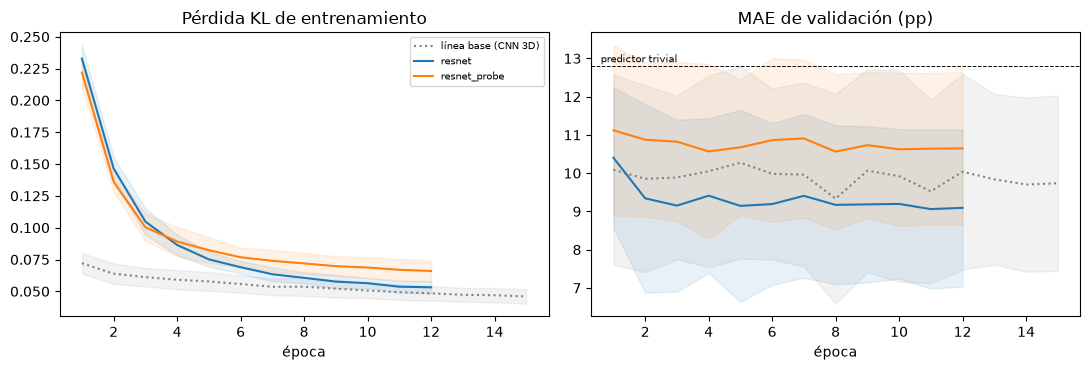

,train_KL_época1,train_KL_final,val_MAE_época1,val_MAE_final
línea base (CNN 3D),0.072,0.046,10.086,9.736
resnet,0.233,0.053,10.402,9.093
resnet_probe,0.222,0.066,11.119,10.647


In [35]:
def curves(folder_of):
    return np.stack([pd.read_csv(MODELS / folder_of(s) / f"fold{k}" / "history.csv")[["train_kl", "val_mae_pp"]].values
                     for s in SEEDS for k in range(5)])           # (15, épocas, 2)
series = {"línea base (CNN 3D)": curves(lambda s: "baseline" if s == 42 else f"baseline_s{s}")}
series |= {v: curves(lambda s, v=v: f"{v}_s{s}") for v in VARIANTS}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for j, ax in enumerate(axes):
    for (name, H), color in zip(series.items(), ("gray", "tab:blue", "tab:orange")):
        m, sd = H[:, :, j].mean(0), H[:, :, j].std(0); ep = np.arange(1, len(m) + 1)
        ax.plot(ep, m, color=color, ls=":" if name.startswith("línea") else "-", label=name); ax.fill_between(ep, m - sd, m + sd, alpha=0.1, color=color)
    ax.set_xlabel("época")
axes[0].set_title("Pérdida KL de entrenamiento"); axes[1].set_title("MAE de validación (pp)")
axes[1].axhline(12.80, color="k", ls="--", lw=0.7); axes[1].text(0.6, 12.9, "predictor trivial", fontsize=7); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGURES / f"curvas_{KEY}.png", dpi=130); plt.show()
display(pd.DataFrame({n: dict(train_KL_época1=H[:, 0, 0].mean(), train_KL_final=H[:, -1, 0].mean(),
                              val_MAE_época1=H[:, 0, 1].mean(), val_MAE_final=H[:, -1, 1].mean()) for n, H in series.items()}).T.round(3))

### A.5 Resultados

Mismo protocolo que la sección 5.4: MAE sobre las tres variables, en puntos porcentuales; CV sobre los 70 participantes (media ± desviación **entre folds**) y test de 15. Se muestran **cada semilla por separado** (para ver cuánto varía el resultado solo por el azar del entrenamiento) y el ensamble de las tres, junto a las referencias: predictor trivial, CNN 3D de la línea base y Ridge sobre trayectorias.

In [36]:
base_paths = [REP / "baseline_predictions.csv", REP / "baseline_predictions_s7.csv", REP / "baseline_predictions_s123.csv"]
models = {"Predictor trivial": trivial_predictions(F)}
for s, p in zip(SEEDS, base_paths): models[f"CNN 3D línea base s{s}"] = load_cnn_predictions([p])
models["CNN 3D línea base (ensamble)"] = load_cnn_predictions(base_paths)
for v in VARIANTS:
    paths = [REP / f"baseline_predictions_{v}_s{s}.csv" for s in SEEDS]
    for s, p in zip(SEEDS, paths): models[f"{v} s{s}"] = load_cnn_predictions([p])
    models[f"{v} (ensamble 3 semillas)"] = load_cnn_predictions(paths)
models["Características + Ridge"] = load_regression_predictions("D_evisan_to_visem_960")
comp = pd.DataFrame({k: score(*v, folds=F) for k, v in models.items()}).T
comp.to_csv(REP / f"comparacion_{KEY}.csv")
display(comp[["cv_mae", "cv_mae_std", "cv_rmse", "test_mae", "test_rmse", "cv_mae_prog"]].round(2))
for v in ("CNN 3D línea base",) + VARIANTS:
    cv = comp.loc[[f"{v} s{s}" if v != "CNN 3D línea base" else f"CNN 3D línea base s{s}" for s in SEEDS], "cv_mae"]
    print(f"{v}: MAE de CV por semilla {cv.mean():.2f} ± {cv.std():.2f} (desviación entre semillas; entre folds es ~2 pp)")

,cv_mae,cv_mae_std,cv_rmse,test_mae,test_rmse,cv_mae_prog
Predictor trivial,12.80,1.37,16.52,13.22,16.64,17.01
CNN 3D línea base s42,9.76,2.26,14.14,7.11,9.62,10.69
CNN 3D línea base s7,9.56,2.19,13.52,7.12,9.66,10.41
CNN 3D línea base s123,9.89,2.40,14.18,6.84,9.53,10.63
CNN 3D línea base (ensamble),9.71,2.28,13.89,7.00,9.58,10.56
resnet s42,9.29,2.13,12.21,8.16,10.66,10.97
resnet s7,9.19,1.99,12.13,8.23,10.71,10.69
resnet s123,8.80,2.02,11.76,8.05,10.57,10.40
resnet (ensamble 3 semillas),9.00,2.03,11.94,8.13,10.60,10.55
resnet_probe s42,10.71,2.04,13.68,9.98,12.83,13.48


CNN 3D línea base: MAE de CV por semilla 9.74 ± 0.17 (desviación entre semillas; entre folds es ~2 pp)
resnet: MAE de CV por semilla 9.09 ± 0.26 (desviación entre semillas; entre folds es ~2 pp)
resnet_probe: MAE de CV por semilla 10.65 ± 0.06 (desviación entre semillas; entre folds es ~2 pp)


### A.6 Análisis de errores

¿Fallan los mismos participantes que en la línea base y en el Ridge? Se compara el error por participante (predicciones fuera de muestra de los 85, ensambles de 3 semillas) y se mira si las notas de calidad del video (*drift*, residuo) o el evaluador se asocian con el error.

Correlación del error por participante con el de la línea base y con el de Ridge:


,err_base,err_ridge
err_resnet,0.78,0.73
err_resnet_probe,0.56,0.49


Error medio (pp) en videos con y sin nota de calidad (drift / debris):


,err_base,err_ridge,err_resnet,err_resnet_probe,n
,mean,mean,mean,mean,
nota_calidad,,,,,
False,7.9,7.1,8.6,10.4,72
True,16.4,11.4,10.4,11.1,13


Error medio (pp) por evaluador:


,err_base,err_ridge,err_resnet,err_resnet_probe,n
evaluator,,,,,
HH,11.4,8.1,8.2,9.8,18
IVS,10.9,6.3,10.9,13.3,3
JMA,6.7,6.0,8.4,11.0,27
OW,9.4,10.9,9.5,10.1,7
SSW,10.0,8.6,9.3,10.3,30


Participantes donde 'resnet' más empeora (arriba) y más mejora (abajo) frente a la línea base:


,progressive,evaluator,err_base,err_resnet,err_ridge
ID,,,,,
79,66,JMA,2.7,9.1,5.5
52,14,SSW,3.8,9.5,4.9
82,17,JMA,8.3,13.5,4.3
81,61,HH,6.2,11.3,10.8
44,50,SSW,9.6,2.2,11.4
7,0,HH,45.5,37.2,30.3
10,26,HH,37.0,16.6,13.3
8,43,HH,39.1,6.9,5.9


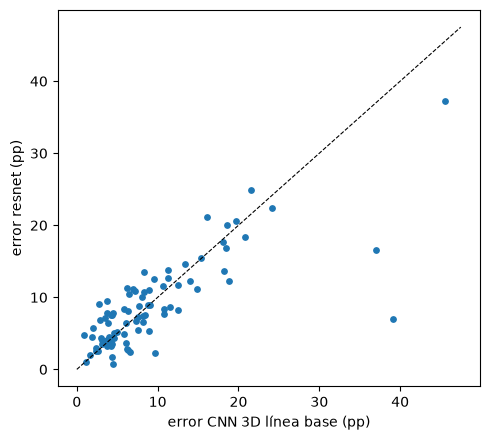

In [37]:
def err(p): return pd.concat([per_participant_error(p[0], F), per_participant_error(p[1], F)])
d = F.loc[err(models["Características + Ridge"]).index, ["progressive", "evaluator", "quality_note"]].assign(
    err_base=err(models["CNN 3D línea base (ensamble)"]), err_ridge=err(models["Características + Ridge"]))
for v in VARIANTS: d[f"err_{v}"] = err(models[f"{v} (ensamble 3 semillas)"])
cols = [c for c in d.columns if c.startswith("err_")]
print("Correlación del error por participante con el de la línea base y con el de Ridge:")
display(d[cols].corr().loc[[f"err_{v}" for v in VARIANTS], ["err_base", "err_ridge"]].round(2))
d["nota_calidad"] = d.quality_note.notna()
print("Error medio (pp) en videos con y sin nota de calidad (drift / debris):")
display(d.groupby("nota_calidad")[cols].agg(["mean"]).round(1).assign(n=d.groupby("nota_calidad").size()))
print("Error medio (pp) por evaluador:"); display(d.groupby("evaluator")[cols].mean().round(1).assign(n=d.groupby("evaluator").size()))
v0 = VARIANTS[0]; dd = d.assign(mejora=d.err_base - d[f"err_{v0}"]).sort_values("mejora")
print(f"Participantes donde '{v0}' más empeora (arriba) y más mejora (abajo) frente a la línea base:")
display(dd.iloc[list(range(4)) + list(range(-4, 0))][["progressive", "evaluator", "err_base", f"err_{v0}", "err_ridge"]].round(1))
fig, ax = plt.subplots(figsize=(5, 4.5)); ax.scatter(d.err_base, d[f"err_{v0}"], s=15); lim = max(d.err_base.max(), d[f"err_{v0}"].max()) + 2
ax.plot([0, lim], [0, lim], "k--", lw=0.8); ax.set_xlabel("error CNN 3D línea base (pp)"); ax.set_ylabel(f"error {v0} (pp)")
plt.tight_layout(); plt.savefig(FIGURES / f"errores_{KEY}.png", dpi=130); plt.show()

### A.7 Análisis y conclusiones

#### A.7.1 Qué pasó con cada hipótesis

| Variante | MAE CV (70) | MAE test (15) | MAE sobre los 85 | Frente a la CNN 3D base (85 participantes, dif. pareada e IC 95 %) |
| --- | --- | --- | --- | --- |
| CNN 3D base (ensamble) | 9,71 | 7,00 | 9,24 | — |
| ResNet18 afinada (`layer4`) | 9,00 | 8,13 | 8,84 | −0,39 pp [−1,57; +0,58]: **no significativa** |
| ResNet18 sonda lineal | 10,65 | 9,98 | 10,53 | +1,29 pp peor [−0,22; +2,72]: tendencia a peor, no significativa |
| Ridge sobre trayectorias | 7,97 | 6,81 | 7,76 | −1,47 pp [−2,79; −0,33]: **significativamente mejor** |

(Las diferencias pareadas son sobre el error por participante de los 85 participantes fuera de muestra, con *bootstrap* de participantes, 10.000 remuestreos.)

**Hipótesis 1 (afinado): un buen punto de partida basta aunque haya más parámetros libres.** Se cumple solo a medias. En validación cruzada la ResNet afinada baja el MAE de 9,71 a 9,00 y el RMSE de 13,9 a 11,9 (menos errores grandes), pero en test **empeora** (8,13 contra 7,00) y la diferencia sobre los 85 participantes **no se distingue del azar**. La pérdida de entrenamiento final (0,053) queda cerca de la de la línea base (0,046): sigue memorizando participantes, como era de esperar con 8,4 M de parámetros entrenables.

**Hipótesis 2 (sonda lineal): pocos parámetros libres sobre características fijas de ImageNet reducen el sobreajuste. No se cumple.** Con el backbone congelado la pérdida de entrenamiento final es la más alta de todas (0,066) y el error de validación es peor (10,65 en CV, 9,98 en test): el modelo **subajusta**. Las características de ImageNet, aprendidas con objetos naturales, no separan por sí solas una muestra móvil de una inmóvil en estas imágenes de movimiento; hay que adaptarlas (afinar `layer4`) para obtener algo.

#### A.7.2 Dónde mejora y dónde no
- **Robustez a videos con *drift* o residuo** (13 de los 85 con nota de calidad): error medio de 10,4 pp con la ResNet afinada contra 16,4 con la CNN 3D base y 11,4 con Ridge. Sin nota de calidad (72 videos) la ResNet no mejora (8,6 contra 7,9 de la base y 7,1 de Ridge). Participantes como el 8, el 10 y el 7 (los tres del evaluador HH) pasan de errores de 39, 37 y 45 pp a 7, 17 y 37 pp. Con 13 videos y un participante extremo (el 7) esto es un indicio, no una conclusión; no se identificó el mecanismo.
- **Contracción hacia la media.** La pendiente de la motilidad predicha frente a la real es de 0,62 en la línea base, **0,48 en la ResNet afinada** y 0,28 en la sonda lineal (1 sería perfecto; Ridge: 0,73). Los participantes con motilidad progresiva ≥ 50 % se subestiman en 11,4 pp (7,7 en la base) y los de < 15 % se sobreestiman en 18,4 pp (14,6 en la base). La ResNet empeora justo en participantes con motilidad alta que la base ya acertaba (p. ej. los participantes 79 y 81, de motilidad 66 % y 61 %).
- **Los errores no se diversifican:** la correlación del error por participante con la línea base es 0,78 y con Ridge 0,73. Fallan casi en los mismos participantes.

#### A.7.3 Conclusión
Partir de ImageNet **no** resolvió el problema de fondo: el error de validación sigue en torno a 9 pp, a ~1 pp de distancia significativa del regresor con trayectorias. El límite parece estar más en los datos (56 participantes de entrenamiento por fold) y en el ruido de las etiquetas que en la elección de la red. La sonda lineal es un resultado negativo útil: descarta que "menos parámetros" por sí solo ayude. El resultado se reporta tal como salió; no se probaron otras configuraciones sobre estos folds para no seleccionar sobre los datos de evaluación.

## Anexo B · CNN 3D regularizada

_Anexo B del cuaderno principal; su resumen está en la sección 5.4._

### B.1 Motivación e hipótesis

La CNN 3D de la línea base **sobreajusta** (pérdida de entrenamiento 0,072 → 0,046 mientras el error de validación se queda en ≈ 9–11 pp). Este experimento ataca el mismo problema **sin cambiar de familia de modelo**, reduciendo la capacidad y aumentando la regularización.

**Hipótesis.** Una red más pequeña con más regularización y más variación en los datos memorizará menos a cada participante, y su error de validación bajará frente a la CNN 3D original.

**Qué cambia y qué no.** Se mantienen idénticos los folds, los clips, la pérdida (KL), el protocolo y la regla de la última época. Cambian cuatro cosas orientadas a un mismo fin (menos memorización), así que si el resultado mejora no se podrá atribuir a una sola: es un experimento de "paquete de regularización", no una ablación.

### B.2 Diseño del experimento

- **Menos capacidad:** canales de los bloques a la mitad (8, 16, 32, 64 en lugar de 16, 32, 64, 128): **74 mil parámetros frente a 294 mil** (4 veces menos).
- **Más regularización:** Dropout(0,5) antes de la capa final (era 0,3), `Dropout3d(0,1)` tras cada bloque convolucional y weight decay 5e-2 (era 1e-2).
- **Más variación de los datos:** inversión temporal del clip (conserva la magnitud de la velocidad; solo invierte el sentido, que no es informativo para la motilidad) y variación aleatoria de brillo (×0,85–1,15, ±12 niveles de gris).
- **Entrenamiento:** igual que la línea base (AdamW, lr 1e-3 con coseno, 15 épocas, batch 16, AMP), 3 semillas.

**Decisiones fijadas antes de ver resultados:** una sola configuración, sin ajustar sobre el fold evaluado; el resultado, sea cual sea, se reporta.

### B.3 Configuración y reproducibilidad

Se cargan utilidades y se fijan semillas. Los entrenamientos se lanzan desde la terminal (`python src/exp_variants.py reg3d <semilla>`; ~1 h por semilla con la GPU compartida) y este cuaderno **solo lee** las predicciones y las curvas que dejan en `reports/` y `models/`, para poder ejecutarlo entero en segundos.

In [38]:
import sys, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
from results_utils import (load_folds, load_cnn_predictions, load_regression_predictions, trivial_predictions,
                           score, per_participant_error, TARGETS)
F = load_folds()
REP, MODELS, FIGURES = ROOT / "reports", ROOT / "models", ROOT / "reports" / "figures"
KEY, VARIANTS, SEEDS = "reg3d", ('reg3d',), (42, 7, 123)
random.seed(42); np.random.seed(42)
print("Variantes:", VARIANTS, "| semillas:", SEEDS)

Variantes: ('reg3d',) | semillas: (42, 7, 123)


Tamaño de cada modelo frente a la línea base. Importa el número de parámetros **entrenables**: es lo que la red puede memorizar.

In [39]:
from baseline_video import Baseline3D
from exp_variants import ResNetMotion, ResNetProbe, Reg3D
CLASSES = {"resnet": ResNetMotion, "resnet_probe": ResNetProbe, "reg3d": Reg3D}
def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable))
rows = {"CNN 3D (línea base)": Baseline3D()} | {v: CLASSES[v]() for v in VARIANTS}
display(pd.DataFrame({"parámetros totales": [n_params(m) for m in rows.values()],
                      "parámetros entrenables": [n_params(m, True) for m in rows.values()]}, index=list(rows)).style.format("{:,}"))

,parámetros totales,parámetros entrenables
CNN 3D (línea base),"293,811","293,811"
reg3d,"74,331","74,331"


### B.4 Curvas de entrenamiento

Pérdida KL de entrenamiento y MAE de validación por época. Cada línea es la media sobre los 5 folds y las 3 semillas (la banda es la desviación entre esas 15 corridas), con la línea base punteada. Permiten ver si el sobreajuste se redujo (la brecha entre ambas curvas) y si hay convergencia.

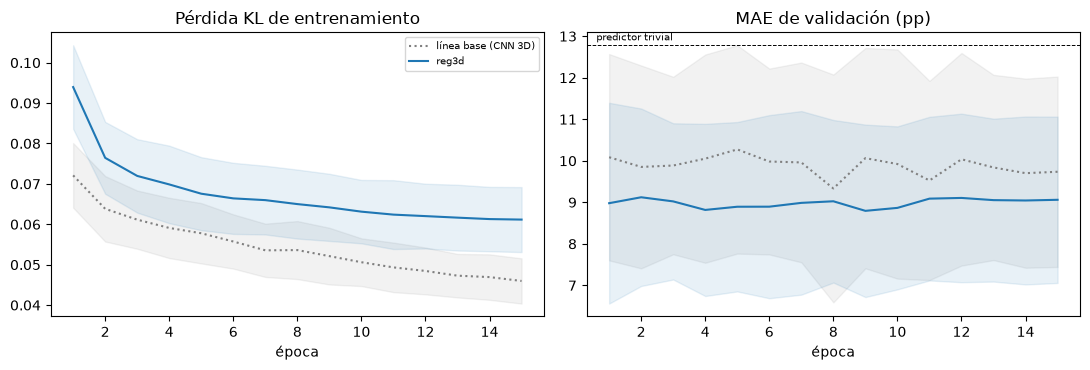

,train_KL_época1,train_KL_final,val_MAE_época1,val_MAE_final
línea base (CNN 3D),0.072,0.046,10.086,9.736
reg3d,0.094,0.061,8.979,9.061


In [40]:
def curves(folder_of):
    return np.stack([pd.read_csv(MODELS / folder_of(s) / f"fold{k}" / "history.csv")[["train_kl", "val_mae_pp"]].values
                     for s in SEEDS for k in range(5)])           # (15, épocas, 2)
series = {"línea base (CNN 3D)": curves(lambda s: "baseline" if s == 42 else f"baseline_s{s}")}
series |= {v: curves(lambda s, v=v: f"{v}_s{s}") for v in VARIANTS}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for j, ax in enumerate(axes):
    for (name, H), color in zip(series.items(), ("gray", "tab:blue", "tab:orange")):
        m, sd = H[:, :, j].mean(0), H[:, :, j].std(0); ep = np.arange(1, len(m) + 1)
        ax.plot(ep, m, color=color, ls=":" if name.startswith("línea") else "-", label=name); ax.fill_between(ep, m - sd, m + sd, alpha=0.1, color=color)
    ax.set_xlabel("época")
axes[0].set_title("Pérdida KL de entrenamiento"); axes[1].set_title("MAE de validación (pp)")
axes[1].axhline(12.80, color="k", ls="--", lw=0.7); axes[1].text(0.6, 12.9, "predictor trivial", fontsize=7); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGURES / f"curvas_{KEY}.png", dpi=130); plt.show()
display(pd.DataFrame({n: dict(train_KL_época1=H[:, 0, 0].mean(), train_KL_final=H[:, -1, 0].mean(),
                              val_MAE_época1=H[:, 0, 1].mean(), val_MAE_final=H[:, -1, 1].mean()) for n, H in series.items()}).T.round(3))

### B.5 Resultados

Mismo protocolo que la sección 5.4: MAE sobre las tres variables, en puntos porcentuales; CV sobre los 70 participantes (media ± desviación **entre folds**) y test de 15. Se muestran **cada semilla por separado** (para ver cuánto varía el resultado solo por el azar del entrenamiento) y el ensamble de las tres, junto a las referencias: predictor trivial, CNN 3D de la línea base y Ridge sobre trayectorias.

In [41]:
base_paths = [REP / "baseline_predictions.csv", REP / "baseline_predictions_s7.csv", REP / "baseline_predictions_s123.csv"]
models = {"Predictor trivial": trivial_predictions(F)}
for s, p in zip(SEEDS, base_paths): models[f"CNN 3D línea base s{s}"] = load_cnn_predictions([p])
models["CNN 3D línea base (ensamble)"] = load_cnn_predictions(base_paths)
for v in VARIANTS:
    paths = [REP / f"baseline_predictions_{v}_s{s}.csv" for s in SEEDS]
    for s, p in zip(SEEDS, paths): models[f"{v} s{s}"] = load_cnn_predictions([p])
    models[f"{v} (ensamble 3 semillas)"] = load_cnn_predictions(paths)
models["Características + Ridge"] = load_regression_predictions("D_evisan_to_visem_960")
comp = pd.DataFrame({k: score(*v, folds=F) for k, v in models.items()}).T
comp.to_csv(REP / f"comparacion_{KEY}.csv")
display(comp[["cv_mae", "cv_mae_std", "cv_rmse", "test_mae", "test_rmse", "cv_mae_prog"]].round(2))
for v in ("CNN 3D línea base",) + VARIANTS:
    cv = comp.loc[[f"{v} s{s}" if v != "CNN 3D línea base" else f"CNN 3D línea base s{s}" for s in SEEDS], "cv_mae"]
    print(f"{v}: MAE de CV por semilla {cv.mean():.2f} ± {cv.std():.2f} (desviación entre semillas; entre folds es ~2 pp)")

,cv_mae,cv_mae_std,cv_rmse,test_mae,test_rmse,cv_mae_prog
Predictor trivial,12.80,1.37,16.52,13.22,16.64,17.01
CNN 3D línea base s42,9.76,2.26,14.14,7.11,9.62,10.69
CNN 3D línea base s7,9.56,2.19,13.52,7.12,9.66,10.41
CNN 3D línea base s123,9.89,2.40,14.18,6.84,9.53,10.63
CNN 3D línea base (ensamble),9.71,2.28,13.89,7.00,9.58,10.56
reg3d s42,8.94,1.97,11.86,7.79,10.40,10.11
reg3d s7,9.06,1.89,12.09,7.86,10.45,10.18
reg3d s123,9.18,2.13,12.46,7.81,10.44,10.40
reg3d (ensamble 3 semillas),9.04,2.00,12.10,7.82,10.43,10.19
Características + Ridge,7.97,1.20,10.36,6.81,9.23,8.90


CNN 3D línea base: MAE de CV por semilla 9.74 ± 0.17 (desviación entre semillas; entre folds es ~2 pp)
reg3d: MAE de CV por semilla 9.06 ± 0.12 (desviación entre semillas; entre folds es ~2 pp)


### B.6 Análisis de errores

¿Fallan los mismos participantes que en la línea base y en el Ridge? Se compara el error por participante (predicciones fuera de muestra de los 85, ensambles de 3 semillas) y se mira si las notas de calidad del video (*drift*, residuo) o el evaluador se asocian con el error.

Correlación del error por participante con el de la línea base y con el de Ridge:


,err_base,err_ridge
err_reg3d,0.92,0.73


Error medio (pp) en videos con y sin nota de calidad (drift / debris):


,err_base,err_ridge,err_reg3d,n
,mean,mean,mean,
nota_calidad,,,,
False,7.9,7.1,8.2,72
True,16.4,11.4,12.5,13


Error medio (pp) por evaluador:


,err_base,err_ridge,err_reg3d,n
evaluator,,,,
HH,11.4,8.1,9.3,18
IVS,10.9,6.3,10.5,3
JMA,6.7,6.0,7.5,27
OW,9.4,10.9,8.8,7
SSW,10.0,8.6,9.6,30


Participantes donde 'reg3d' más empeora (arriba) y más mejora (abajo) frente a la línea base:


,progressive,evaluator,err_base,err_reg3d,err_ridge
ID,,,,,
79,66,JMA,2.7,7.1,5.5
62,68,JMA,2.8,6.5,3.7
64,72,JMA,3.8,7.3,3.1
74,68,JMA,4.3,7.6,3.9
25,37,IVS,18.8,14.0,14.0
7,0,HH,45.5,35.6,30.3
10,26,HH,37.0,23.5,13.3
8,43,HH,39.1,22.4,5.9


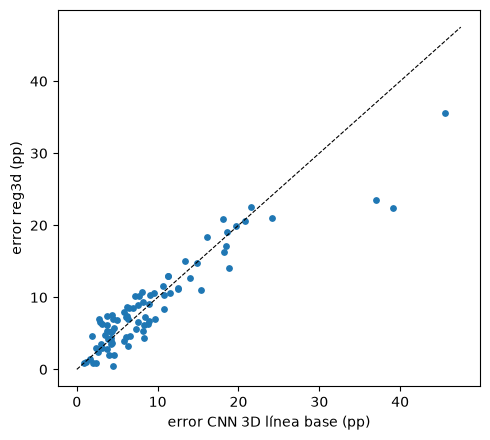

In [42]:
def err(p): return pd.concat([per_participant_error(p[0], F), per_participant_error(p[1], F)])
d = F.loc[err(models["Características + Ridge"]).index, ["progressive", "evaluator", "quality_note"]].assign(
    err_base=err(models["CNN 3D línea base (ensamble)"]), err_ridge=err(models["Características + Ridge"]))
for v in VARIANTS: d[f"err_{v}"] = err(models[f"{v} (ensamble 3 semillas)"])
cols = [c for c in d.columns if c.startswith("err_")]
print("Correlación del error por participante con el de la línea base y con el de Ridge:")
display(d[cols].corr().loc[[f"err_{v}" for v in VARIANTS], ["err_base", "err_ridge"]].round(2))
d["nota_calidad"] = d.quality_note.notna()
print("Error medio (pp) en videos con y sin nota de calidad (drift / debris):")
display(d.groupby("nota_calidad")[cols].agg(["mean"]).round(1).assign(n=d.groupby("nota_calidad").size()))
print("Error medio (pp) por evaluador:"); display(d.groupby("evaluator")[cols].mean().round(1).assign(n=d.groupby("evaluator").size()))
v0 = VARIANTS[0]; dd = d.assign(mejora=d.err_base - d[f"err_{v0}"]).sort_values("mejora")
print(f"Participantes donde '{v0}' más empeora (arriba) y más mejora (abajo) frente a la línea base:")
display(dd.iloc[list(range(4)) + list(range(-4, 0))][["progressive", "evaluator", "err_base", f"err_{v0}", "err_ridge"]].round(1))
fig, ax = plt.subplots(figsize=(5, 4.5)); ax.scatter(d.err_base, d[f"err_{v0}"], s=15); lim = max(d.err_base.max(), d[f"err_{v0}"].max()) + 2
ax.plot([0, lim], [0, lim], "k--", lw=0.8); ax.set_xlabel("error CNN 3D línea base (pp)"); ax.set_ylabel(f"error {v0} (pp)")
plt.tight_layout(); plt.savefig(FIGURES / f"errores_{KEY}.png", dpi=130); plt.show()

### B.7 Análisis y conclusiones

#### B.7.1 Qué pasó con la hipótesis

| Modelo | Parámetros | MAE CV (70) | MAE test (15) | MAE sobre los 85 |
| --- | --- | --- | --- | --- |
| CNN 3D base (ensamble 3 semillas) | 294 mil | 9,71 | 7,00 | 9,24 |
| CNN 3D regularizada (ensamble 3 semillas) | 74 mil | **9,04** | 7,82 | 8,82 |
| Ridge sobre trayectorias | 24 características | 7,97 | 6,81 | 7,76 |

**Hipótesis: menos capacidad y más regularización reducen la memorización y bajan el error de validación.** Se cumple de forma **parcial y pequeña**:
- **Menos memorización: sí.** La pérdida de entrenamiento final sube de 0,046 a 0,061: la red ajusta menos a los participantes de entrenamiento.
- **Menor error: poco.** El MAE de CV baja 0,67 pp (de 9,71 a 9,04; entre semillas la desviación es de solo 0,12 pp, así que la mejora no es ruido de entrenamiento) y el RMSE de 13,9 a 12,1. Pero en test **empeora** (7,82 contra 7,00) y sobre los 85 participantes la diferencia pareada es −0,41 pp con IC 95 % [−1,13; +0,22]: **no se distingue de cero**.
- **Sigue lejos del Ridge:** 1,06 pp peor, diferencia significativa (IC 95 % [+0,14; +2,00]).

#### B.7.2 Lectura de las curvas
La CNN regularizada llega a su error de validación desde la **primera época** (8,98 pp) y luego no mejora (9,06 al final), igual que la línea base (10,09 al inicio y 9,74 al final). Reducir la capacidad cuatro veces y añadir regularización no cambió ese comportamiento: el modelo aprende rápido una señal gruesa de cuánto movimiento hay, y lo que falta para afinar la estimación no está en la red sino en la información disponible (pocos participantes y etiquetas posiblemente ruidosas, algo no verificado: el evaluador como variable no explica el error, ver anexo C).

#### B.7.3 Costo de la regularización: más contracción hacia la media
La pendiente de la motilidad predicha frente a la real baja de 0,62 (base) a **0,55**, y el sesgo en motilidad alta (≥ 50 %) pasa de −7,7 a −10,7 pp, y en motilidad baja (< 15 %) de +14,6 a +16,4 pp. Los participantes en que más empeora respecto a la base (79, 62, 64 y 74) son los cuatro de motilidad alta (66–72 %) evaluados por JMA, el evaluador con menor error. Es el comportamiento típico de regularizar más: el modelo se vuelve más conservador y se acerca a predecir el promedio.

#### B.7.4 Dónde sí ayuda
En los 13 videos con nota de calidad (*drift*, residuo) el error baja de 16,4 a 12,5 pp, y en los participantes 7, 10 y 8 (evaluador HH) pasa de 46, 37 y 39 pp a 36, 24 y 22 pp. Con 13 videos es un indicio, y el participante 7 (0 % de progresiva) sigue siendo el peor caso de todos los modelos.

#### B.7.5 Conclusión
La regularización da una mejora modesta en CV, no confirmada en test ni estadísticamente, y a cambio de predicciones más conservadoras. **Los errores del modelo regularizado son casi los mismos que los de la línea base** (correlación 0,92 por participante): no resuelve los casos difíciles, solo los atenúa. La brecha con el regresor sobre trayectorias se mantiene. Esto refuerza la lectura del anexo A: el techo de los modelos directos con estos datos está en ~9 pp.

## Anexo C · Ablaciones del método con trayectorias

_Anexo C del cuaderno principal; su resumen está en la sección 5.3 y 5.6._

### C.1 Motivación

El método que mejor estima la motilidad (detector YOLO → seguimiento ByteTrack → 24 características de movimiento → Ridge) supera de forma significativa a todos los modelos de video directo (anexos A y B). Aquí se investiga **por qué funciona y qué lo limita**, con tres preguntas:

1. **¿Un mejor detector da una mejor estimación de motilidad?** Se comparan los detectores A (solo EVISAN), B (EVISAN → VISEM) y D (B con 960 px y más aumentos), que difieren mucho en mAP y en calidad de seguimiento.
2. **¿Qué familias de características aportan?** Conteo, velocidad, linealidad y fracción de trayectorias casi quietas, solas y quitando una a la vez.
3. **¿Cuánto video hace falta?** Estimación con 30, 60 y 120 s de video (una pregunta práctica para el laboratorio).

**Protocolo.** Siempre el mismo: validación cruzada agrupada por participante con los folds fijos de `folds.csv`; el test (15) se reporta aparte y **no se usa para elegir nada**. Las diferencias se comparan de forma **pareada** (el error de cada participante con un modelo contra el error con el otro) con *bootstrap* de participantes sobre los 85 participantes fuera de muestra.

### C.2 Configuración

Importaciones y utilidades comunes (`src/results_utils.py`, `src/motility_regression.py`).

In [43]:
import sys, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path(".").resolve(); sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")
from results_utils import load_folds, load_regression_predictions, per_participant_error, score, TARGETS
from motility_regression import fit_predict
from motion_features import features_from_tracks
F = load_folds(); REP, PROC, FIGURES = ROOT / "reports", ROOT / "data" / "processed", ROOT / "reports" / "figures"
random.seed(42); np.random.seed(42)
DET = {"A (solo EVISAN)": "A_evisan_only", "B (EVISAN→VISEM, 640 px)": "B_evisan_to_visem", "D (EVISAN→VISEM, 960 px)": "D_evisan_to_visem_960"}
rng = np.random.default_rng(42)
def paired(ea, eb, n=10000):
    # ea, eb: error por participante de dos modelos; devuelve diferencia media (ea - eb) e IC 95 % por bootstrap de participantes
    d = (ea - eb).values; bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), *np.percentile(bs, [2.5, 97.5])

### C.3 ¿Un mejor detector da una mejor estimación de motilidad?

Para cada detector se juntan tres medidas: **detección** (mAP@0.5 en VISEM-test), **seguimiento** (MOTA e IDF1 en validación, 4 participantes anotados) y **estimación final** (MAE del Ridge, CV sobre 70 y test de 15). Los tres detectores usan el mismo umbral de confianza (0,4) y las mismas características.

,mAP@0.5 VISEM-test,MOTA val,IDF1 val,MAE CV (70),± entre folds,MAE test (15),MAE 85
A (solo EVISAN),0.264,-0.816,0.132,8.100,2.369,7.201,7.941
"B (EVISAN→VISEM, 640 px)",0.470,0.056,0.451,7.308,1.163,6.331,7.136
"D (EVISAN→VISEM, 960 px)",0.492,0.294,0.511,7.970,1.196,6.809,7.765


Diferencias pareadas de error (pp) sobre 85 participantes, IC 95 % por bootstrap:
  error(D) − error(B) = +0.63 pp  IC95 [+0.29, +1.01]  (positivo: B mejor)
  error(A) − error(B) = +0.81 pp  IC95 [+0.02, +1.62]  (positivo: B mejor)


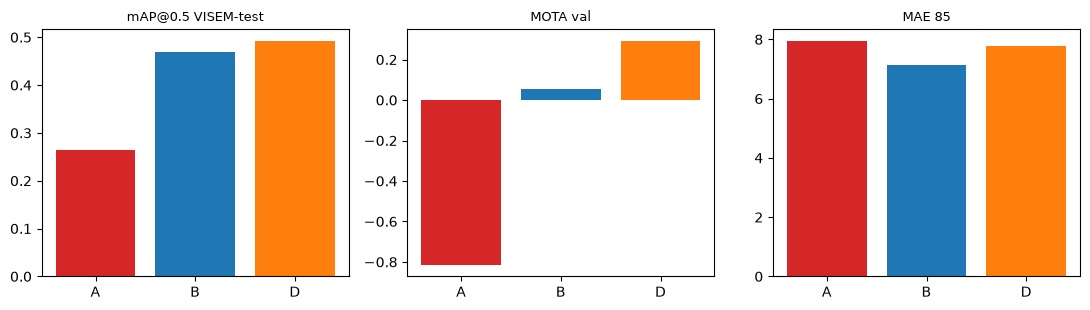

In [44]:
from results_utils import PRED
def ridge_preds(exp):
    # mismo Ridge para los tres detectores: CV por folds fijos (70) y, aparte, entrenado con los 70 y aplicado al test (15)
    feats = pd.read_csv(PROC / f"features_{exp}.csv").set_index("ID"); cols = list(feats.columns)
    d = F[["split", "fold"] + TARGETS].join(feats); tvd, ted = d[d.split == "trainval"], d[d.split == "test"]
    cv = pd.DataFrame(index=tvd.index, columns=PRED, dtype=float)
    for k in sorted(tvd.fold.unique()):
        tr, va = tvd[tvd.fold != k], tvd[tvd.fold == k]
        cv.loc[va.index] = fit_predict("ridge", tr[cols].values, tr[TARGETS].values, va[cols].values)
    te = pd.DataFrame(fit_predict("ridge", tvd[cols].values, tvd[TARGETS].values, ted[cols].values), index=ted.index, columns=PRED)
    return cv, te
ev = pd.read_csv(REP / "detector_eval.csv")
rows, errs = {}, {}
for name, exp in DET.items():
    trk = pd.read_csv(REP / f"tracking_eval_{exp}_val_conf0.4.csv", index_col=0).loc["media"]
    pred = ridge_preds(exp); sc = score(*pred, F)
    errs[name] = pd.concat([per_participant_error(pred[0], F), per_participant_error(pred[1], F)])
    rows[name] = {"mAP@0.5 VISEM-test": ev[(ev.experiment == exp) & (ev.eval_set == "VISEM_test")].mAP50.iloc[0],
                  "MOTA val": trk.mota, "IDF1 val": trk.idf1, "MAE CV (70)": sc["cv_mae"], "± entre folds": sc["cv_mae_std"],
                  "MAE test (15)": sc["test_mae"], "MAE 85": errs[name].mean()}
tab = pd.DataFrame(rows).T
display(tab.round(3))
E = pd.DataFrame(errs)
print("Diferencias pareadas de error (pp) sobre 85 participantes, IC 95 % por bootstrap:")
for a, b in [("D (EVISAN→VISEM, 960 px)", "B (EVISAN→VISEM, 640 px)"), ("A (solo EVISAN)", "B (EVISAN→VISEM, 640 px)")]:
    m, lo, hi = paired(E[a], E[b]); print(f"  error({a[0]}) − error({b[0]}) = {m:+.2f} pp  IC95 [{lo:+.2f}, {hi:+.2f}]  (positivo: {b[0]} mejor)")
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, col in zip(ax, ["mAP@0.5 VISEM-test", "MOTA val", "MAE 85"]):
    a.bar([n[0] for n in tab.index], tab[col], color=["tab:red", "tab:blue", "tab:orange"]); a.set_title(col, fontsize=9)
plt.tight_layout(); plt.savefig(FIGURES / "detector_vs_motilidad.png", dpi=130); plt.show()

### C.4 ¿Qué familias de características aportan?

Las 24 características se agrupan en cuatro familias:

| Familia | Características | Qué mide |
| --- | --- | --- |
| Conteo | `det_per_frame`, `n_tracks`, `n_long_tracks` | Cuántas células se detectan |
| Velocidad | `vcl_*`, `vap_*` (media, mediana, percentiles) | Rapidez del camino recorrido |
| Linealidad y avance | `vsl_*`, `lin_*`, `str__*`, `frac_lin_gt05` | Cuánto avanzan en línea recta |
| Casi quietas | `frac_vsl_lt5/10/20/40` | Fracción de trayectorias con desplazamiento neto muy pequeño |

Se evalúa el Ridge con cada familia sola y con todas **menos** una (validación cruzada de los 70, mismo protocolo). Es un análisis sobre CV; el test no interviene.

In [45]:
GROUPS = {"conteo": ["det_per_frame", "n_tracks", "n_long_tracks"],
          "velocidad": ["vcl_mean", "vcl_median", "vap_mean", "vap_median", "vap_p25", "vap_p75", "vap_p90"],
          "linealidad": ["vsl_mean", "vsl_median", "vsl_p25", "vsl_p75", "vsl_p90", "lin_mean", "lin_median", "str__mean", "str__median", "frac_lin_gt05"],
          "casi_quietas": ["frac_vsl_lt5", "frac_vsl_lt10", "frac_vsl_lt20", "frac_vsl_lt40"]}
tv = F[F.split == "trainval"]
def cv_mae(feats, cols):
    d = tv[["fold"] + TARGETS].join(feats[cols]); fm = []
    for k in sorted(d.fold.unique()):
        tr, va = d[d.fold != k], d[d.fold == k]
        P = fit_predict("ridge", tr[cols].values, tr[TARGETS].values, va[cols].values); fm.append(np.abs(P - va[TARGETS].values).mean())
    return np.mean(fm), np.std(fm)
res = {}
for exp in ("B_evisan_to_visem", "D_evisan_to_visem_960"):
    feats = pd.read_csv(PROC / f"features_{exp}.csv").set_index("ID"); allc = sum(GROUPS.values(), [])
    r = {"todas": cv_mae(feats, allc)}
    for g, cols in GROUPS.items(): r[f"solo {g}"] = cv_mae(feats, cols)
    for g in GROUPS: r[f"sin {g}"] = cv_mae(feats, [c for c in allc if c not in GROUPS[g]])
    res[exp[0]] = pd.Series({k: f"{v[0]:.2f} ± {v[1]:.2f}" for k, v in r.items()})
display(pd.DataFrame(res).rename(columns={"B": "detector B", "D": "detector D"}))
print("MAE de CV (pp, media ± desviación entre folds). Referencia: predictor trivial 12,80 ± 1,37.")

,detector B,detector D
todas,7.31 ± 1.16,7.97 ± 1.20
solo conteo,10.74 ± 2.36,10.96 ± 2.27
solo velocidad,10.60 ± 1.87,11.19 ± 1.71
solo linealidad,8.08 ± 1.40,8.31 ± 1.55
solo casi_quietas,8.03 ± 1.67,8.47 ± 1.53
sin conteo,7.59 ± 1.09,8.06 ± 1.15
sin velocidad,7.31 ± 1.28,7.87 ± 1.35
sin linealidad,7.59 ± 1.78,8.06 ± 1.57
sin casi_quietas,7.60 ± 1.31,8.26 ± 1.32


MAE de CV (pp, media ± desviación entre folds). Referencia: predictor trivial 12,80 ± 1,37.


### C.5 ¿Cuánto video hace falta?

Las trayectorias se calcularon sobre los primeros 120 s de cada video. Aquí se recortan a 30, 60 y 120 s, se recalculan las características (con la misma corrección de deriva y la misma longitud mínima de trayectoria de 1 s) y se repite la validación cruzada con el detector B. Es una pregunta práctica: si bastan 30 s, el análisis es cuatro veces más rápido.

In [46]:
manifest = pd.read_csv(PROC / "visem_gray" / "manifest.csv").set_index("ID")
def feats_upto(exp, seconds):
    rows = []
    for pid in F.index:
        df = pd.read_csv(PROC / "tracks" / exp / f"{pid}.csv.gz"); df = df[df.t_s <= seconds]
        rows.append(dict(ID=pid, **features_from_tracks(df, manifest.loc[pid, "fps"])))
    return pd.DataFrame(rows).set_index("ID")
dur = {}
for s in (30, 60, 120):
    fe = feats_upto("B_evisan_to_visem", s); cols = [c for c in pd.read_csv(PROC / "features_B_evisan_to_visem.csv").columns if c != "ID"]
    fe = fe.reindex(columns=cols).fillna(0.0); dur[s] = cv_mae(fe, cols)
display(pd.DataFrame({f"{s} s de video": f"{m:.2f} ± {sd:.2f}" for s, (m, sd) in dur.items()}, index=["MAE CV (pp)"]))

,30 s de video,60 s de video,120 s de video
MAE CV (pp),7.26 ± 1.57,7.46 ± 1.12,7.31 ± 1.16


### C.6 ¿Importa la corrección de deriva?

En la sección 5.5 la CNN 3D de video directo falla mucho más que el Ridge en los 13 videos con nota de calidad (*drift*, residuo). Una posible razón es que el pipeline de trayectorias **resta la deriva global** (el desplazamiento mediano de todas las trayectorias entre frames) y la CNN no. Se prueba quitando esa corrección: se recalculan las características sin ella (detector B, 120 s) y se compara el error en videos con y sin nota de calidad. Es un análisis de CV (70 participantes); en esa partición hay pocos videos con nota, así que se reporta el número de videos.

In [47]:
import motion_features as mf
def cv_errors(feats, cols):
    # error absoluto medio por participante (fuera de muestra) con el mismo CV agrupado
    d = tv[["fold"] + TARGETS].join(feats[cols]); out = {}
    for k in sorted(d.fold.unique()):
        tr, va = d[d.fold != k], d[d.fold == k]
        P = fit_predict("ridge", tr[cols].values, tr[TARGETS].values, va[cols].values)
        out.update(dict(zip(va.index, np.abs(P - va[TARGETS].values).mean(axis=1))))
    return pd.Series(out)
cols_all = [c for c in pd.read_csv(PROC / "features_B_evisan_to_visem.csv").columns if c != "ID"]
with_drift = feats_upto("B_evisan_to_visem", 120).reindex(columns=cols_all).fillna(0.0)
orig = mf.remove_drift
mf.remove_drift = lambda df: df.sort_values(["track_id", "frame"]).copy()      # desactiva la corrección
try:
    no_drift = feats_upto("B_evisan_to_visem", 120).reindex(columns=cols_all).fillna(0.0)
finally:
    mf.remove_drift = orig
e1, e0 = cv_errors(with_drift, cols_all), cv_errors(no_drift, cols_all)
noted = tv.quality_note.notna().reindex(e1.index)
display(pd.DataFrame({"con corrección de deriva": [e1.mean(), e1[noted].mean(), e1[~noted].mean()],
                      "sin corrección": [e0.mean(), e0[noted].mean(), e0[~noted].mean()]},
                     index=[f"todos (n={len(e1)})", f"con nota de calidad (n={int(noted.sum())})", f"sin nota (n={int((~noted).sum())})"]).round(2))
print("MAE (pp) por participante, validación cruzada. Notas de calidad en los 70:", tv.quality_note.dropna().to_dict())

,con corrección de deriva,sin corrección
todos (n=70),7.31,7.37
con nota de calidad (n=13),9.96,9.61
sin nota (n=57),6.70,6.86


MAE (pp) por participante, validación cruzada. Notas de calidad en los 70: {2: 'lots of debris', 6: 'drift', 7: 'minor drift', 8: 'minor drift', 9: 'minor drift', 10: 'minor drift', 41: 'minor drift', 42: 'minor drift', 43: 'drift', 44: 'drift', 46: 'minor drift', 52: 'drift', 85: 'drift'}


### C.7 Deep Learning sobre las trayectorias: red de conjuntos

Hasta aquí el DL era sobre el video (anexos A y B) y no superó al Ridge. Aquí se aplica DL **al método ganador**: cada participante es un *conjunto* de cientos de trayectorias y una red neuronal pequeña (`src/track_set_net.py`) aprende directamente cómo combinarlas.

**Arquitectura.** Cada trayectoria se describe con 6 números (VCL, VAP, VSL, LIN, STR y duración; las velocidades y la duración en escala logarítmica, todo estandarizado con las medias del entrenamiento). Una MLP compartida (6→32→32, ReLU) codifica cada trayectoria; los códigos se agrupan con **media y máximo** sobre el conjunto (esto hace al modelo invariante al orden y al número de trayectorias, el principio de *Deep Sets*), se añade la densidad de trayectorias por segundo y una capa lineal con dropout 0,2 da los tres porcentajes con softmax. Tiene 1.478 parámetros (la CNN 3D base tiene 293.811). **Por qué:** el Ridge usa estadísticos que elegimos a mano (media, percentiles, fracciones bajo un umbral); la red puede aprender sus propios estadísticos del conjunto y mezclar velocidad y linealidad trayectoria a trayectoria.

**Entrenamiento.** Pérdida KL contra la motilidad real (igual que la CNN 3D), AdamW (lr 3·10⁻³, decaimiento de pesos 10⁻²), planificador coseno, 300 épocas, 4 minilotes por época. **Aumento de datos:** en cada época, para cada participante se recorta una ventana temporal aleatoria de 45 a 120 s y, con probabilidad 0,5, se submuestrea entre el 50 % y el 100 % de las trayectorias (el participante es el mismo; cambia el muestreo). Mismos folds, 3 semillas y **última época** (no se elige época con la validación). **No se ajustaron hiperparámetros:** es la primera configuración que se probó, así que las cifras no están infladas por selección.

,cv_mae,cv_mae_std,cv_rmse,test_mae,test_rmse
Red de conjuntos (ensamble 3 semillas),7.18,1.39,9.43,6.45,8.81
Ridge + trayectorias (B),7.31,1.16,9.66,6.33,8.53
CNN 3D (ensamble 3 semillas),9.71,2.28,13.89,7.00,9.58
Promedio 50/50 red de conjuntos + Ridge,7.11,1.29,9.41,6.32,8.51


,cv_mae,test_mae
semilla 42,7.21,6.40
semilla 7,7.21,6.64
semilla 123,7.23,6.32


MAE sobre los 85 participantes fuera de muestra:
Red de conjuntos (ensamble 3 semillas)     7.05
Ridge + trayectorias (B)                   7.14
CNN 3D (ensamble 3 semillas)               9.24
Promedio 50/50 red de conjuntos + Ridge    6.97


,modelo_A,modelo_B,dif_A_menos_B,IC95_bajo,IC95_alto,distinguible
0,CNN 3D (ensamble 3 semillas),Red de conjuntos (ensamble 3 semillas),2.19,1.00,3.52,True
1,Ridge + trayectorias (B),Red de conjuntos (ensamble 3 semillas),0.09,-0.38,0.53,False
2,Ridge + trayectorias (B),Promedio 50/50 red de conjuntos + Ridge,0.17,-0.07,0.39,False
3,Red de conjuntos (ensamble 3 semillas),Promedio 50/50 red de conjuntos + Ridge,0.08,-0.16,0.33,False


Correlación del error por participante, red de conjuntos vs Ridge: 0.9 | vs CNN 3D: 0.68


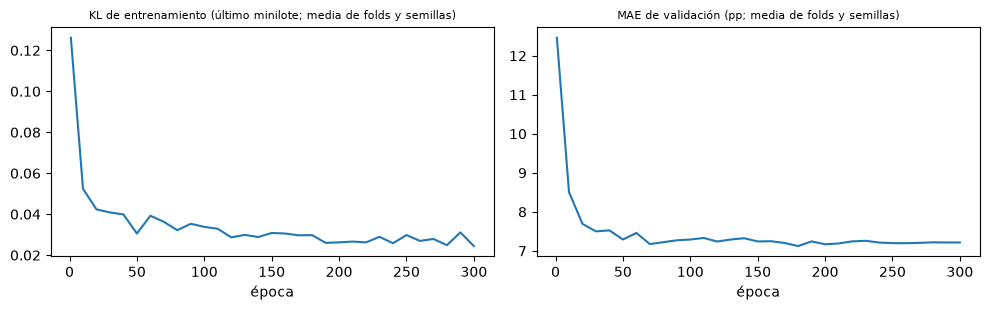

       train_kl  val_mae
epoch                   
1         0.126   12.461
50        0.031    7.292
100       0.034    7.291
200       0.026    7.169
300       0.024    7.215


In [48]:
from results_utils import load_cnn_predictions
SEEDS = (42, 7, 123)
sets_seed = {s: load_cnn_predictions([REP / f"baseline_predictions_trackset_s{s}.csv"]) for s in SEEDS}
sets = load_cnn_predictions([REP / f"baseline_predictions_trackset_s{s}.csv" for s in SEEDS])
cnn = load_cnn_predictions([REP / "baseline_predictions.csv", REP / "baseline_predictions_s7.csv", REP / "baseline_predictions_s123.csv"])
ridgeB = ridge_preds("B_evisan_to_visem")
avg = ((ridgeB[0] + sets[0]) / 2, (ridgeB[1] + sets[1]) / 2)
mods = {"Red de conjuntos (ensamble 3 semillas)": sets, "Ridge + trayectorias (B)": ridgeB, "CNN 3D (ensamble 3 semillas)": cnn,
        "Promedio 50/50 red de conjuntos + Ridge": avg}
tab7 = pd.DataFrame({k: score(*v, F) for k, v in mods.items()}).T[["cv_mae", "cv_mae_std", "cv_rmse", "test_mae", "test_rmse"]]
display(tab7.round(2))
display(pd.DataFrame({f"semilla {s}": score(*v, F) for s, v in sets_seed.items()}).T[["cv_mae", "test_mae"]].round(2))
E7 = pd.DataFrame({k: pd.concat([per_participant_error(v[0], F), per_participant_error(v[1], F)]) for k, v in mods.items()})
print("MAE sobre los 85 participantes fuera de muestra:"); print(E7.mean().round(2).to_string())
S, R, Cn, Av = list(mods)
rows = []
for a, b in [(Cn, S), (R, S), (R, Av), (S, Av)]:
    m, lo, hi = paired(E7[a], E7[b]); rows.append(dict(modelo_A=a, modelo_B=b, dif_A_menos_B=m, IC95_bajo=lo, IC95_alto=hi, distinguible=bool(lo > 0 or hi < 0)))
display(pd.DataFrame(rows).round(2))
print("Correlación del error por participante, red de conjuntos vs Ridge:", round(E7[S].corr(E7[R]), 2), "| vs CNN 3D:", round(E7[S].corr(E7[Cn]), 2))
hist = pd.concat([pd.read_csv(REP / f"trackset_history_s{s}.csv").assign(seed=s) for s in SEEDS])
h = hist.groupby("epoch")[["train_kl", "val_mae"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h.index, h.train_kl); ax[0].set_title("KL de entrenamiento (último minilote; media de folds y semillas)", fontsize=8); ax[0].set_xlabel("época")
ax[1].plot(h.index, h.val_mae); ax[1].set_title("MAE de validación (pp; media de folds y semillas)", fontsize=8); ax[1].set_xlabel("época")
plt.tight_layout(); plt.savefig(FIGURES / "curvas_red_conjuntos.png", dpi=130); plt.show()
print(h.iloc[[0, 5, 10, 20, 30]].round(3).to_string())

### C.8 Análisis y conclusiones

**1. Un mejor detector no dio una mejor estimación de motilidad.** El detector A (solo EVISAN) tiene el peor seguimiento por mucho (MOTA −0,82, IDF1 0,13, mAP@0,5 en VISEM-test de 0,26) y aun así el Ridge con sus trayectorias da MAE de CV 8,10 pp, frente a 12,80 del predictor trivial y 7,31 con B. El detector D, que ganó en seguimiento sobre validación (MOTA 0,29), da 7,97, peor que B. Diferencias pareadas sobre los 85 participantes fuera de muestra: D menos B = +0,63 pp [0,29; 1,01] y A menos B = +0,81 pp [0,02; 1,62] (positivo: B mejor; el segundo intervalo apenas excluye el 0). Lectura: las características de motilidad (fracción de trayectorias quietas, linealidad) son estadísticos agregados sobre cientos de células, y un detector con muchos falsos positivos y trayectorias partidas conserva casi toda la señal; MOTA e IDF1, medidos con 4 participantes, no predijeron el resultado final. La **transferencia directa EVISAN→VISEM falla en detección y seguimiento** (hallazgo del objetivo 1), pero su efecto sobre la motilidad es moderado (+0,8 pp), no catastrófico. Ojo: el MAE de test de A (7,20) se calculó con el mismo Ridge, solo para describir; no se usó para elegir nada.

**2. Qué aportan las familias de características.** Solas, **linealidad** (8,08) y **casi quietas** (8,03) casi alcanzan el modelo completo (7,31); **conteo** (10,74) y **velocidad** (10,60) solas quedan más cerca del trivial (12,80). Quitar una familia a la vez cambia poco: sin conteo 7,59, sin linealidad 7,59, sin casi quietas 7,60 y **sin velocidad 7,31, igual que con todas**. Con detector D el patrón es el mismo. Las diferencias de ~0,3 pp son mucho menores que la desviación entre folds (~1,2) y no se contrastaron, así que solo se puede decir que la información está **redundante** entre familias y que lo esencial es "cuánta fracción de células avanza en línea recta". La velocidad, una vez dadas las otras, no añade nada medible. Las velocidades están en píxeles por segundo (VISEM no trae la escala µm/píxel).

**3. Cuánto video hace falta.** MAE de CV con 30 s: 7,26 ± 1,57; 60 s: 7,46 ± 1,12; 120 s: 7,31 ± 1,16. No hay diferencia apreciable; con 30 s basta en este análisis, aunque la variabilidad entre folds es mayor (1,57). Es un resultado sobre la estimación con estas etiquetas (ruidosas); no demuestra que 30 s sean suficientes para un uso clínico.

**4. La corrección de deriva no explica el fallo de la CNN en los videos con nota.** Sin corregir la deriva el MAE de CV es 7,37 contra 7,31 con ella; en los 13 videos con nota de calidad es 9,61 sin corrección contra 9,96 con ella (la corrección no ayuda en ese grupo), y en los 57 sin nota 6,86 contra 6,70. Las diferencias (0,04 a 0,35 pp, con n = 13) son pequeñas y no se acompañan de incertidumbre. Lo que sí se ve es que **los videos con nota son más difíciles también para el Ridge** (≈ 10 contra ≈ 6,7 pp). La hipótesis planteada en 5.5 (la CNN sufre porque no corrige la deriva) **no queda respaldada**: el motivo del peor desempeño de la CNN en esos videos sigue sin explicar.

**5. DL sobre trayectorias: la red de conjuntos iguala al Ridge, no lo supera.** Con 1.478 parámetros, sin ajuste de hiperparámetros y 3 semillas (MAE de CV 7,21; 7,21; 7,23), el ensamble da 7,18 ± 1,39 en CV y 6,45 en test (Ridge: 7,31 ± 1,16 y 6,33). Es **significativamente mejor que la CNN 3D** (+2,19 pp [1,00; 3,52] sobre los 85) y **no se distingue del Ridge** (+0,09 [−0,38; 0,53]). El promedio 50/50 de ambos tampoco mejora de forma distinguible (Ridge menos promedio: +0,17 [−0,07; 0,39]). La correlación del error por participante con el Ridge es de 0,90: la red aprende esencialmente la misma información que las características diseñadas a mano. Las curvas muestran que el MAE de validación baja de 12,5 pp en la época 1 a 7,3 en la 50 y se queda plano (7,17 a 7,29 hasta la 300), sin señales de sobreajuste en validación; el KL de entrenamiento (último minilote, ruidoso) pasa de 0,13 a 0,02. Con 50 épocas habría bastado; se dejaron 300 para no elegir la parada con la validación.

**Conclusión del cuaderno.** El rendimiento del sistema parece limitado por la información disponible (características y etiquetas) y por tener solo 85 participantes, más que por el modelo o la calidad del detector: modelos muy distintos (Ridge, red de conjuntos, y en menor medida las CNN de video) convergen a ~7 pp o a ~9 pp con errores muy correlacionados, y detectores muy distintos dan 7,3 a 8,1. Las trayectorias aportan una ventaja real sobre el video directo (≈ 2 pp), no sobre el tipo de regresor que se use sobre ellas. Se comprobó que el evaluador, como variable, no explica el error (Ridge con el evaluador: CV 7,65 contra 7,31; solo el evaluador: 13,01, igual que la media), de modo que **no está demostrado que el límite sea ruido de etiqueta**: también puede faltar información en las características.

## Anexo D · Cuatro intentos de mejorar el Deep Learning

_Anexo D del cuaderno principal; su resumen está en la sección 5.4 y 6._

### D.1 Motivación

Tras los anexos A a C, el mejor modelo de Deep Learning es una red de conjuntos sobre trayectorias que **empata** con el Ridge (MAE de CV 7,18 y 7,31) y supera a las CNN de video (≈ 9 a 9,7). Aquí se intentan cuatro mejoras, **cada una con una hipótesis explícita y evaluada con el mismo protocolo** (folds fijos, CV de 70 y test de 15 aparte; diferencias pareadas sobre los 85 participantes con *bootstrap*):

1. **Variable no progresiva.** Es la que peor se predice en todos los modelos. ¿Por qué, y se puede mejorar?
2. **Ajuste de hiperparámetros con validación cruzada anidada.** La red de conjuntos se entrenó sin ajustar nada; ¿ajustar la mejora de forma honesta?
3. **Modelo de video preentrenado** (r3d_18, Kinetics-400). Cierra la comparación con el DL directo.
4. **Incertidumbre.** ¿Cuándo se puede (o no) confiar en una estimación individual?

### D.2 Configuración

Importaciones y utilidades comunes de `src/results_utils.py`.

In [49]:
import sys, warnings, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
ROOT = Path(".").resolve(); sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")
from results_utils import (load_folds, load_regression_predictions, load_cnn_predictions, per_participant_error, score,
                           trivial_predictions, TARGETS, PRED)
F = load_folds(); REP, FIGURES = ROOT / "reports", ROOT / "reports" / "figures"
random.seed(42); np.random.seed(42); rng = np.random.default_rng(42)
TV = F[F.split == "trainval"]
def paired(ea, eb, n=10000):
    d = (ea - eb).values; bs = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), *np.percentile(bs, [2.5, 97.5])
def errs(p): return pd.concat([per_participant_error(p[0], F), per_participant_error(p[1], F)])
trackset = load_cnn_predictions([REP / f"baseline_predictions_trackset_s{s}.csv" for s in (42, 7, 123)])
ridgeB = load_regression_predictions("B_evisan_to_visem")
cnn3d = load_cnn_predictions([REP / "baseline_predictions.csv", REP / "baseline_predictions_s7.csv", REP / "baseline_predictions_s123.csv"])

### D.3 Intento 1 · La variable no progresiva

**Hipótesis.** La no progresiva es difícil por motivos de los datos, no del modelo: tiene poca variación (la referencia trivial ya la acierta mejor que a las otras), es una categoría intermedia y puede depender de la progresiva de forma no lineal (poca no progresiva si la muestra es casi toda inmóvil o casi toda progresiva). Se mide primero cuánto aprende cada modelo **sobre la referencia trivial** de cada variable (habilidad = 1 − MAE/MAE trivial) y qué forma tiene la relación entre variables.

Desviación estándar de cada variable (85 participantes): {'progressive': 20.2, 'non_progressive': 9.5, 'immotile': 17.9}
Correlaciones entre variables:


,progressive,non_progressive,immotile
progressive,1.00,-0.47,-0.88
non_progressive,-0.47,1.00,-0.01
immotile,-0.88,-0.01,1.00


,progresiva,no progresiva,inmóvil
Predictor trivial,17.01,8.20,13.19
Ridge + trayectorias (B),8.02,7.32,6.59
Red de conjuntos,8.04,6.97,6.52
CNN 3D,10.56,8.75,9.83


Habilidad = 1 − MAE/MAE trivial (0 = igual que la media; negativo = peor que la media):


,progresiva,no progresiva,inmóvil
Ridge + trayectorias (B),0.53,0.11,0.50
Red de conjuntos,0.53,0.15,0.51
CNN 3D,0.38,-0.07,0.25


R² de no progresiva explicada por progresiva (sobre las etiquetas reales): lineal 0.22, cuadrática 0.52


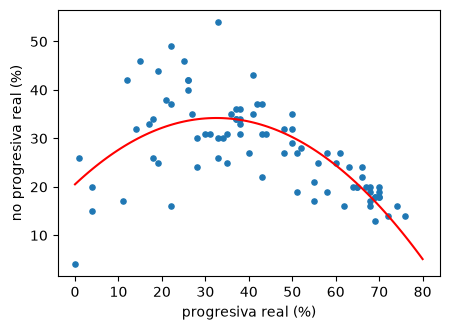

In [50]:
print("Desviación estándar de cada variable (85 participantes):", F[TARGETS].std().round(1).to_dict())
print("Correlaciones entre variables:"); display(F[TARGETS].corr().round(2))
triv = trivial_predictions(F); y = F.loc[triv[0].index, TARGETS].values; mt = np.abs(triv[0].values - y).mean(0)
rows = {"Predictor trivial": mt}
for k, (cv, te) in {"Ridge + trayectorias (B)": ridgeB, "Red de conjuntos": trackset, "CNN 3D": cnn3d}.items():
    rows[k] = np.abs(cv.loc[triv[0].index].values - y).mean(0)
mae_t = pd.DataFrame(rows, index=["progresiva", "no progresiva", "inmóvil"]).T
display(mae_t.round(2))
print("Habilidad = 1 − MAE/MAE trivial (0 = igual que la media; negativo = peor que la media):")
display((1 - mae_t.iloc[1:].div(mt, axis=1)).round(2))
x, yy = F.progressive.values, F.non_progressive.values
r2 = lambda d: 1 - ((yy - np.polyval(np.polyfit(x, yy, d), x)) ** 2).sum() / ((yy - yy.mean()) ** 2).sum()
print(f"R² de no progresiva explicada por progresiva (sobre las etiquetas reales): lineal {r2(1):.2f}, cuadrática {r2(2):.2f}")
fig, ax = plt.subplots(figsize=(4.6, 3.4)); ax.scatter(x, yy, s=14); g = np.linspace(0, 80, 100)
ax.plot(g, np.polyval(np.polyfit(x, yy, 2), g), "r"); ax.set_xlabel("progresiva real (%)"); ax.set_ylabel("no progresiva real (%)")
plt.tight_layout(); plt.savefig(FIGURES / "nopro_vs_pro.png", dpi=130); plt.show()

**Prueba de la estructura.** Si la no progresiva es una función en U invertida de la progresiva, se puede **predecir la progresiva y derivar de ella la no progresiva** con una parábola ajustada solo en los folds de entrenamiento (la inmóvil es lo que sobra para sumar 100). Se evalúa con la CV de los 70.

In [51]:
def u_structure(cv):
    new = cv.copy()
    for k in sorted(TV.fold.unique()):
        tr, va = TV[TV.fold != k], TV[TV.fold == k].index
        c = np.polyfit(tr.progressive, tr.non_progressive, 2); p = cv.loc[va, "pred_progressive"].values
        npg = np.minimum(np.clip(np.polyval(c, p), 0, None), 100 - p)
        new.loc[va, "pred_non_progressive"] = npg; new.loc[va, "pred_immotile"] = 100 - p - npg
    return new
rows = []
for name, (cv, te) in {"Ridge + trayectorias (B)": ridgeB, "Red de conjuntos": trackset}.items():
    for lab, x_ in (("original", cv), ("progresiva → U invertida", u_structure(cv))):
        yv = F.loc[x_.index, TARGETS].values; per = np.abs(x_.values - yv).mean(0)
        fm = [np.abs(x_.loc[TV[TV.fold == k].index].values - F.loc[TV[TV.fold == k].index, TARGETS].values).mean() for k in sorted(TV.fold.unique())]
        rows.append(dict(modelo=name, salida=lab, mae_prog=per[0], mae_nopro=per[1], mae_inmov=per[2], mae_cv=np.mean(fm), sd_folds=np.std(fm)))
display(pd.DataFrame(rows).round(2))

,modelo,salida,mae_prog,mae_nopro,mae_inmov,mae_cv,sd_folds
0,Ridge + trayectorias (B),original,8.02,7.32,6.59,7.31,1.16
1,Ridge + trayectorias (B),progresiva → U invertida,8.02,7.18,6.20,7.14,1.54
2,Red de conjuntos,original,8.04,6.97,6.52,7.18,1.39
3,Red de conjuntos,progresiva → U invertida,8.04,7.05,6.53,7.21,1.73


**Análisis.**
- **Es difícil por los datos.** La no progresiva varía poco (desviación 9,5 pp, contra 20,2 de la progresiva y 17,9 de la inmóvil), así que el predictor trivial ya la acierta con MAE de 8,2 en CV; no queda mucho que ganar. La habilidad sobre la referencia es de 0,53 (progresiva) y 0,50 a 0,51 (inmóvil) para el Ridge y la red de conjuntos, pero solo de **0,11 y 0,15** en la no progresiva. La **CNN 3D es peor que predecir la media** en esa variable (habilidad −0,07). En la red de conjuntos la correlación de Pearson predicho-real en CV es 0,86 en progresiva, 0,87 en inmóvil y **0,40** en no progresiva, y ninguna característica de movimiento pasa de |r| = 0,43 con ella (contra 0,85 y 0,87 con las otras).
- **Es una categoría intermedia con relación no lineal.** La no progresiva casi no se relaciona con la inmóvil (r = −0,01) y su relación con la progresiva es una U invertida: sobre las etiquetas reales, la progresiva explica el 22 % de su varianza con una recta y el 52 % con una parábola. Es coherente con que una muestra casi toda inmóvil o casi toda progresiva tenga poca no progresiva.
- **Aprovechar esa estructura no mejora de forma clara.** Derivar la no progresiva de la progresiva predicha con una parábola baja el MAE de CV del Ridge de 7,31 a 7,14 (no progresiva de 7,32 a 7,18) pero sube el de la red de conjuntos de 7,18 a 7,21 (no progresiva de 6,97 a 7,05), y la variación entre folds aumenta (de 1,16 a 1,54 en el Ridge y de 1,39 a 1,73 en la red). La red de conjuntos ya puede capturar la no linealidad por sí sola. **Conclusión:** la baja capacidad de predecir la no progresiva se debe sobre todo a la poca variación de la variable, a su carácter intermedio y probablemente a la subjetividad del evaluador al separar "lenta" de "inmóvil"; con estas etiquetas no hay una mejora de modelado evidente. No se adopta el cambio.

### D.4 Intento 2 · Ajuste de hiperparámetros con validación cruzada anidada

**Hipótesis.** La red de conjuntos se entrenó con la primera configuración (32 unidades, dropout 0,2) sin ajustar nada; una pequeña búsqueda podría mejorarla. **Cuidado metodológico:** si se elige la mejor configuración según la CV y se reporta esa misma CV, el resultado queda inflado. Por eso se usa CV **anidada**: en cada fold externo la configuración se elige solo con una CV interna sobre los otros 4 folds (`src/track_set_nested.py`), se reentrena con ellos y se predice el fold externo; el fold externo nunca interviene en la elección. Rejilla: 16, 32 y 64 unidades × dropout 0,2 y 0,5 (6 configuraciones), 100 épocas (la red converge hacia la 50), una semilla.

In [52]:
inner = pd.concat([pd.read_csv(REP / f"nested_trackset_inner_fold{k}.csv") for k in range(5)])
display(inner.pivot_table(index=["hidden", "drop"], columns="fold", values="inner_mae").assign(media=lambda d: d.mean(axis=1)).round(2))
d = pd.concat([pd.read_csv(REP / f"nested_trackset_fold{k}.csv") for k in range(5)])
print("Configuración elegida en cada fold externo:"); display(d.groupby("fold")[["hidden", "drop"]].first().T)
n_cv = d[d.split == "cv"].set_index("ID")[PRED]; n_te = d[d.split == "test"].groupby("ID")[PRED].mean()
s42 = load_cnn_predictions([REP / "baseline_predictions_trackset_s42.csv"])
tab = pd.DataFrame({"CV anidada (config. elegida por fold)": score(n_cv, n_te, F), "Configuración por defecto (semilla 42)": score(*s42, F)}).T
display(tab[["cv_mae", "cv_mae_std", "test_mae"]].round(2))
m, lo, hi = paired(errs((n_cv, n_te)), errs(s42)); print(f"error(anidada) − error(por defecto) = {m:+.2f} pp  IC95 [{lo:+.2f}, {hi:+.2f}]")

fold            0     1     2     3     4  media
hidden drop                                     
16     0.2   6.95  7.20  7.73  8.01  7.99   7.57
       0.5   7.62  7.88  8.42  8.86  8.55   8.27
32     0.2   7.17  6.73  7.79  7.86  7.51   7.41
       0.5   7.36  7.10  8.01  8.26  7.87   7.72
64     0.2   7.02  6.54  7.74  7.79  7.30   7.28
       0.5   7.01  6.77  7.89  7.98  7.42   7.42

Configuración elegida en cada fold externo:


fold,0,1,2,3,4
hidden,16.0,64.0,16.0,64.0,64.0
drop,0.2,0.2,0.2,0.2,0.2


,cv_mae,cv_mae_std,test_mae
CV anidada (config. elegida por fold),7.22,1.48,6.8
Configuración por defecto (semilla 42),7.21,1.19,6.4


error(anidada) − error(por defecto) = +0.08 pp  IC95 [-0.23, +0.40]


**Análisis.**
- **Ajustar no ayudó.** La CV anidada da MAE de **7,22 ± 1,48** contra 7,21 ± 1,19 de la configuración por defecto con la misma semilla; la diferencia pareada sobre los 85 es +0,08 pp [−0,23; 0,40]. El test de esta corrida (6,80, una semilla, promedio de los 5 modelos externos) es peor que el de por defecto (6,40), pero con 15 participantes no se interpreta.
- **Lo que sí enseña la búsqueda:** el dropout de 0,2 es mejor que el de 0,5 en los 5 folds y para los tres tamaños (MAE interno medio con 0,2: 7,57 con 16 unidades, 7,41 con 32 y 7,28 con 64; con 0,5: 8,27, 7,72 y 7,42). Dicho de otro modo, **la red no sobreajusta y le sobra poca regularización**; más capacidad ayuda algo en la CV interna, aunque los folds externos eligieron 16 unidades en dos casos (folds 0 y 2) y 64 en tres (folds 1, 3 y 4): la elección es inestable, otra señal de que las diferencias entre configuraciones son del orden del ruido.
- Los modelos internos se entrenan con 3 folds (~42 participantes), por lo que los MAE internos son algo pesimistas; sirven para comparar configuraciones, no como estimación del rendimiento. **Conclusión:** la configuración por defecto es adecuada y se conserva; el límite no está en los hiperparámetros.

### D.5 Intento 3 · Modelo de video preentrenado (r3d_18)

**Hipótesis.** Los modelos de video entrenados desde cero (CNN 3D) o con imágenes preentrenadas (ResNet18) quedan en ≈ 9 pp. Un modelo de **video** preentrenado en Kinetics-400 (ResNet 3D de 18 capas, `torchvision`) podría extraer mejores características de movimiento. Se afina solo `layer4` y una cabeza nueva (dropout 0,5 + lineal) con lr 3·10⁻⁴, 12 épocas, mismos clips, folds, pérdida (KL) y política de última época que las demás variantes. Cada frame tiene 3 canales: brillo normalizado, brillo menos la media temporal y |diferencia entre frames|. **Parámetros entrenables: 24,9 millones** (más que cualquier otro modelo del proyecto), lo que ya anticipa riesgo de sobreajuste con 56 participantes por fold.

,cv_mae,cv_mae_std,cv_rmse,test_mae,test_rmse
r3d_18 preentrenado (este cuaderno),9.59,2.45,13.09,7.18,9.03
ResNet18 afinada (anexo A),9.00,2.03,11.94,8.13,10.60
CNN 3D regularizada (anexo B),9.04,2.00,12.10,7.82,10.43
CNN 3D base,9.71,2.28,13.89,7.00,9.58
Red de conjuntos,7.18,1.39,9.43,6.45,8.81
Ridge + trayectorias (B),7.31,1.16,9.66,6.33,8.53


,cv_mae,test_mae
semilla 42,9.47,7.18
semilla 7,10.04,7.24
semilla 123,9.48,7.12


,modelo_A,modelo_B,dif_A_menos_B,IC95_bajo,IC95_alto,distinguible
0,r3d_18 preentrenado (este cuaderno),CNN 3D base,-0.08,-0.82,0.66,False
1,r3d_18 preentrenado (este cuaderno),Red de conjuntos,2.11,1.04,3.21,True
2,r3d_18 preentrenado (este cuaderno),Ridge + trayectorias (B),2.03,1.00,3.11,True
3,r3d_18 preentrenado (este cuaderno),ResNet18 afinada (anexo A),0.32,-0.52,1.24,False


MAE sobre los 85 participantes:
r3d_18 preentrenado (este cuaderno)    9.16
ResNet18 afinada (anexo A)             8.84
CNN 3D regularizada (anexo B)          8.82
CNN 3D base                            9.24
Red de conjuntos                       7.05
Ridge + trayectorias (B)               7.14


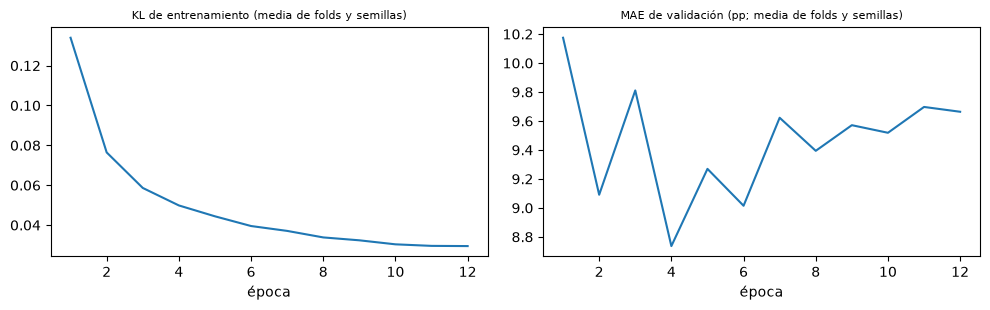

       train_kl  val_mae_pp
epoch                      
1         0.134      10.174
2         0.076       9.091
3         0.059       9.811
4         0.050       8.736
5         0.044       9.269
6         0.040       9.015
7         0.037       9.622
8         0.034       9.394
9         0.032       9.571
10        0.030       9.518
11        0.030       9.697
12        0.029       9.664


In [53]:
SEEDS = (42, 7, 123)
r3d = load_cnn_predictions([REP / f"baseline_predictions_r3d_s{s}.csv" for s in SEEDS])
resnet = load_cnn_predictions([REP / f"baseline_predictions_resnet_s{s}.csv" for s in SEEDS])
reg3d = load_cnn_predictions([REP / f"baseline_predictions_reg3d_s{s}.csv" for s in SEEDS])
mods = {"r3d_18 preentrenado (este cuaderno)": r3d, "ResNet18 afinada (anexo A)": resnet, "CNN 3D regularizada (anexo B)": reg3d,
        "CNN 3D base": cnn3d, "Red de conjuntos": trackset, "Ridge + trayectorias (B)": ridgeB}
display(pd.DataFrame({k: score(*v, F) for k, v in mods.items()}).T[["cv_mae", "cv_mae_std", "cv_rmse", "test_mae", "test_rmse"]].round(2))
display(pd.DataFrame({f"semilla {s}": score(*load_cnn_predictions([REP / f"baseline_predictions_r3d_s{s}.csv"]), F) for s in SEEDS}).T[["cv_mae", "test_mae"]].round(2))
E = pd.DataFrame({k: errs(v) for k, v in mods.items()}); rows = []
R3, RS, RG, CB, ST, RD = list(mods)
for a, b in [(R3, CB), (R3, ST), (R3, RD), (R3, RS)]:
    m, lo, hi = paired(E[a], E[b]); rows.append(dict(modelo_A=a, modelo_B=b, dif_A_menos_B=m, IC95_bajo=lo, IC95_alto=hi, distinguible=bool(lo > 0 or hi < 0)))
display(pd.DataFrame(rows).round(2))
print("MAE sobre los 85 participantes:"); print(E.mean().round(2).to_string())
hist = pd.concat([pd.read_csv(REP.parent / "models" / f"r3d_s{s}" / f"fold{k}" / "history.csv").assign(seed=s, fold=k) for s in SEEDS for k in range(5)])
h = hist.groupby("epoch")[["train_kl", "val_mae_pp"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h.index, h.train_kl); ax[0].set_title("KL de entrenamiento (media de folds y semillas)", fontsize=8); ax[0].set_xlabel("época")
ax[1].plot(h.index, h.val_mae_pp); ax[1].set_title("MAE de validación (pp; media de folds y semillas)", fontsize=8); ax[1].set_xlabel("época")
plt.tight_layout(); plt.savefig(FIGURES / "curvas_r3d.png", dpi=130); plt.show(); print(h.round(3).to_string())

**Análisis.**
- **El preentrenamiento en video no cambió el resultado.** El r3d_18 da MAE de CV **9,59 ± 2,45** y de test 7,18 (semillas: CV 9,47, 10,04 y 9,48). Sobre los 85 participantes no se distingue de la CNN 3D base (−0,08 pp [−0,82; 0,66]) ni de la ResNet18 afinada (+0,32 [−0,52; 1,24]), y es **significativamente peor que el Ridge con trayectorias** (+2,03 pp [1,00; 3,11]) y que la red de conjuntos (+2,11 [1,04; 3,21]).
- **Sobreajusta, como se anticipaba con 24,9 millones de parámetros entrenables y 56 participantes por fold.** El KL de entrenamiento baja de 0,134 a 0,029, mientras el MAE de validación (media de folds y semillas) toca un mínimo de 8,74 pp en la época 4 y termina en 9,66 en la 12; es la misma firma que la CNN 3D base (el entrenamiento mejora, la validación no). Se reporta la última época, igual que en las demás variantes, para no elegir la época con el fold que se evalúa; el mínimo de la época 4 es un promedio y no un resultado alcanzable de forma honesta.
- **Con esto el bloque de DL directo queda cerrado:** cuatro familias distintas (CNN 3D desde cero, CNN 3D regularizada, ResNet18 con imágenes de movimiento, r3d_18 preentrenado en video) terminan en 9,0 a 9,7 pp de CV, sin diferencias distinguibles entre sí. Eso apunta a que el límite del video directo parece estar en la cantidad de participantes y en la información disponible, no en la arquitectura ni en el preentrenamiento (no probamos que sea ruido de etiqueta).

### D.6 Intento 4 · Incertidumbre: ¿cuándo fiarse de una estimación?

**Hipótesis A.** Si varios modelos de familias distintas (Ridge, red de conjuntos, CNN 3D) **discrepan** sobre un participante, ese participante es más difícil y su error será mayor. **Hipótesis B.** Se pueden dar intervalos honestos con *predicción conformal dividida*: con los residuos de la CV (70, fuera de muestra) se calcula, para cada variable, el cuantil que cubre el 80 % o el 90 % de los errores, y se verifica la cobertura en el test (15), que no intervino. La predicción puntual es el promedio de Ridge y red de conjuntos.

In [54]:
both = lambda p: pd.concat([p[0], p[1]])
Rb, Sb, Cb = both(ridgeB), both(trackset), both(cnn3d); ids = Rb.index; Y = F.loc[ids, TARGETS].values
fin = (Rb.values + Sb.values) / 2; err = np.abs(fin - Y).mean(1)
print("MAE del promedio Ridge + red de conjuntos sobre los 85:", err.mean().round(2))
for lab, mem in (("Ridge vs red de conjuntos", [Rb, Sb]), ("Ridge, red de conjuntos y CNN 3D", [Rb, Sb, Cb])):
    u = np.std([m.loc[ids].values for m in mem], axis=0).mean(1); rho, p = spearmanr(u, err)
    print(f"{lab}: correlación de Spearman entre desacuerdo y error = {rho:.2f} (p = {p:.2f})")
u3 = np.std([m.loc[ids].values for m in (Rb, Sb, Cb)], axis=0).mean(1)
note = F.loc[ids, "quality_note"].notna().values
print(f"Desacuerdo medio con nota de calidad (n={note.sum()}): {u3[note].mean():.2f} · sin nota (n={(~note).sum()}): {u3[~note].mean():.2f}")
thr = np.quantile(u3, 2 / 3); print(f"Error en el tercio de mayor desacuerdo: {err[u3 >= thr].mean():.2f} · resto: {err[u3 < thr].mean():.2f}")
pos = {i: n for n, i in enumerate(ids)}; cvi, tei = [pos[i] for i in ridgeB[0].index], [pos[i] for i in ridgeB[1].index]
res = np.abs(fin[cvi] - Y[cvi]); rows = []
for alpha in (0.2, 0.1):
    n = len(res); qh = np.array([np.quantile(res[:, j], min(1, np.ceil((n + 1) * (1 - alpha)) / n)) for j in range(3)])
    cov = (np.abs(fin[tei] - Y[tei]) <= qh).mean(0)
    rows.append(dict(nivel=f"{int((1 - alpha) * 100)} %", **{f"± {t} (pp)": q for t, q in zip(["progresiva", "no progresiva", "inmóvil"], qh)},
                     **{f"cobertura test {t}": c for t, c in zip(["progresiva", "no progresiva", "inmóvil"], cov)}, cobertura_media=cov.mean()))
display(pd.DataFrame(rows).round(2))

MAE del promedio Ridge + red de conjuntos sobre los 85: 6.97
Ridge vs red de conjuntos: correlación de Spearman entre desacuerdo y error = 0.13 (p = 0.22)
Ridge, red de conjuntos y CNN 3D: correlación de Spearman entre desacuerdo y error = 0.15 (p = 0.16)
Desacuerdo medio con nota de calidad (n=13): 6.32 · sin nota (n=72): 2.21
Error en el tercio de mayor desacuerdo: 7.71 · resto: 6.58


,nivel,± progresiva (pp),± no progresiva (pp),± inmóvil (pp),cobertura test progresiva,cobertura test no progresiva,cobertura test inmóvil,cobertura_media
0,80 %,13.14,11.42,10.86,0.87,1.0,0.73,0.87
1,90 %,18.63,15.40,14.24,0.93,1.0,0.87,0.93


**Análisis.**
- **El desacuerdo entre modelos no predice el error de cada participante:** correlación de Spearman de 0,13 (Ridge contra red de conjuntos, p = 0,22) y 0,15 (con la CNN 3D, p = 0,16), ambas no significativas; el error en el tercio de mayor desacuerdo es 7,71 contra 6,58 en el resto. **Sí delata los videos con nota de calidad** (desacuerdo medio 6,32 contra 2,21 sin nota), porque la CNN 3D falla mucho en ellos mientras los modelos de trayectorias no. Sirve como bandera de calidad del video, no como estimador del error.
- **Los intervalos conformales son muy anchos:** con la predicción promedio (MAE 6,97 sobre los 85), un intervalo al 80 % es de ±13,1 pp en progresiva, ±11,4 en no progresiva y ±10,9 en inmóvil; al 90 %, ±18,6, ±15,4 y ±14,2. La cobertura en el test (15 participantes que no intervinieron en la calibración) fue de 0,87 (80 %) y 0,93 (90 %) en promedio, consistente con lo nominal dado que con 15 participantes cada uno vale 6,7 puntos de cobertura (por variable, la inmóvil quedó en 0,73 al 80 % y la no progresiva en 1,00).
- **Qué significa:** una estimación individual tiene una incertidumbre de más de ±10 pp, y para la no progresiva (desviación de 9,5 pp en toda la población) el intervalo es casi tan ancho como la variable misma, es decir, **casi no informa**. Es una limitación importante: el sistema es un apoyo al análisis de la muestra, no una medición individual precisa.

### D.7 Conclusiones del cuaderno

Ninguno de los cuatro intentos produjo un modelo que supere al Ridge con trayectorias (MAE de CV 7,31), y todos dieron información útil:

| Intento | Resultado | Lectura |
| --- | --- | --- |
| 1 · No progresiva | Habilidad de 0,11 a 0,15 sobre la media (CNN 3D: −0,07); imponer la U invertida no mejora | Limitada por los datos: poca varianza, categoría intermedia |
| 2 · CV anidada | 7,22 contra 7,21 por defecto (+0,08 pp [−0,23; 0,40]) | La configuración por defecto es adecuada |
| 3 · r3d_18 | CV 9,59 / test 7,18; peor que Ridge en 2,03 pp [1,00; 3,11] | El preentrenamiento en video no ayuda; sobreajusta |
| 4 · Incertidumbre | Intervalos al 90 % de ±14 a ±19 pp; cobertura en test 0,93 | Una estimación individual es incierta; la no progresiva casi no informa |

**Mensaje principal.** (i) Lo que mejora la estimación es **cambiar la representación** (de video a trayectorias, ≈ 2 pp), no cambiar de modelo ni de arquitectura; (ii) con 85 participantes y una etiqueta por video, el rendimiento queda en 6 a 7 pp de error absoluto y con errores muy correlacionados entre modelos distintos; (iii) el sistema debe presentarse como apoyo al análisis de la muestra, con una incertidumbre individual de ±10 pp o más, y no como una medición precisa. Limitaciones: todos los análisis usan 15 participantes de test y 85 en total, una sola etiqueta por video, y los intentos 2 y 4 usan una sola configuración de semilla y de promedio.

## Anexo E · Características CASA adicionales
_Anexo E del cuaderno principal; su resumen está en la sección 5.8._

### E.1 Motivación e hipótesis
Los 24 descriptores usados hasta aquí (VCL, VAP, VSL, LIN, STR y fracciones de trayectorias casi quietas) no incluyen los parámetros de **oscilación y giro** de un CASA clásico. La variable no progresiva (movimiento que no avanza en línea recta, incluidos giros y vaivén) es la peor predicha por todos los modelos (habilidad de 0,11 a 0,15 sobre la media, Anexo D). **Hipótesis:** añadir ALH (amplitud del desplazamiento lateral), BCF (frecuencia de cruce), giro medio (MAD) y la fracción de trayectorias "en el sitio" (mucho camino y poco avance) mejora la estimación, sobre todo de la no progresiva. `src/extra_features.py` los calcula con la misma corrección de deriva y longitud mínima de 1 s.

### E.2 Diseño
**Se fijan de antemano tres modelos y una sola comparación contra el Ridge actual**, para no repetir un error de una exploración previa en la que se miraron 6 combinaciones y se tomó la mejor (eso infla el resultado): R0 = Ridge con los 24 descriptores; R1 = Ridge con 24 + 12 nuevos; G1 = gradient boosting con 24 + 12. Misma CV de folds fijos, test una vez y diferencias pareadas con *bootstrap* sobre los 85 participantes fuera de muestra, para el error total y para la no progresiva.

In [55]:
import sys, warnings
warnings.filterwarnings("ignore"); sys.path.insert(0, str(ROOT / "src"))
from results_utils import load_folds, score, TARGETS, PRED
from motility_regression import fit_predict
Fo = load_folds()
base_f = pd.read_csv(ROOT / "data" / "processed" / "features_B_evisan_to_visem.csv").set_index("ID")
extra_f = pd.read_csv(ROOT / "data" / "processed" / "features_extra_B_evisan_to_visem.csv").set_index("ID").fillna(0)
dd = Fo.join(base_f).join(extra_f); cb_, ce_ = list(base_f.columns), list(extra_f.columns)
tv_, te_ = dd[dd.split == "trainval"], dd[dd.split == "test"]
def run_e(cols, model):
    cv = pd.DataFrame(index=tv_.index, columns=PRED, dtype=float)
    for k in sorted(tv_.fold.unique()):
        tr, va = tv_[tv_.fold != k], tv_[tv_.fold == k]; cv.loc[va.index] = fit_predict(model, tr[cols].values, tr[TARGETS].values, va[cols].values)
    return cv, pd.DataFrame(fit_predict(model, tv_[cols].values, tv_[TARGETS].values, te_[cols].values), index=te_.index, columns=PRED)
PE = {"R0 · Ridge, 24 descriptores": run_e(cb_, "ridge"), "R1 · Ridge, 24 + 12 nuevos": run_e(cb_ + ce_, "ridge"), "G1 · Gradient boosting, 24 + 12": run_e(cb_ + ce_, "gradient_boosting")}
def err_e(p, var=None):
    return pd.concat([pd.Series(np.abs(x.values - Fo.loc[x.index, TARGETS].values).mean(1) if var is None else np.abs(x.values - Fo.loc[x.index, TARGETS].values)[:, var], index=x.index) for x in p])
tabE = {}
for k, p in PE.items():
    sc = score(*p, Fo); tabE[k] = dict(MAE_CV=sc["cv_mae"], sd_folds=sc["cv_mae_std"], MAE_test=sc["test_mae"], MAE_85=err_e(p).mean(),
                                       nopro_CV=np.abs(p[0].values - Fo.loc[p[0].index, TARGETS].values).mean(0)[1], nopro_85=err_e(p, 1).mean())
display(pd.DataFrame(tabE).T.round(2))
rng_e = np.random.default_rng(42); k0 = list(PE)[0]
for k in list(PE)[1:]:
    for lab, var in (("error total", None), ("no progresiva", 1)):
        d_ = (err_e(PE[k0], var) - err_e(PE[k], var)).values; bs_ = [d_[rng_e.integers(0, len(d_), len(d_))].mean() for _ in range(10000)]
        print(f"{lab}: error(R0) − error({k[:2]}) = {d_.mean():+.2f} pp  IC95 [{np.percentile(bs_, 2.5):+.2f}, {np.percentile(bs_, 97.5):+.2f}]  (positivo: el modelo nuevo es mejor)")

,MAE_CV,sd_folds,MAE_test,MAE_85,nopro_CV,nopro_85
"R0 · Ridge, 24 descriptores",7.31,1.16,6.33,7.14,7.32,6.77
"R1 · Ridge, 24 + 12 nuevos",7.35,1.21,6.39,7.18,7.20,6.62
"G1 · Gradient boosting, 24 + 12",7.35,0.78,7.53,7.38,6.57,6.30


error total: error(R0) − error(R1) = -0.05 pp  IC95 [-0.35, +0.24]  (positivo: el modelo nuevo es mejor)
no progresiva: error(R0) − error(R1) = +0.15 pp  IC95 [-0.30, +0.57]  (positivo: el modelo nuevo es mejor)
error total: error(R0) − error(G1) = -0.25 pp  IC95 [-0.85, +0.35]  (positivo: el modelo nuevo es mejor)
no progresiva: error(R0) − error(G1) = +0.47 pp  IC95 [-0.35, +1.32]  (positivo: el modelo nuevo es mejor)


### E.3 Análisis
**Las características adicionales no mejoran la estimación.** Con ellas el Ridge da MAE de CV 7,35 contra 7,31 (diferencia pareada del error total −0,05 pp [−0,35; 0,24], es decir, ninguna), y el gradient boosting 7,35 en CV pero **7,53 en test** (contra 6,33 del Ridge de referencia). En la **no progresiva**, el gradient boosting baja el error de 6,77 a 6,30 sobre los 85 participantes, pero esa diferencia (0,47 pp) tiene un intervalo que incluye el 0 ([−0,35; 1,32]); no se distingue del azar. La exploración previa que mostraba 6,4 de MAE en la no progresiva venía de elegir la mejor entre varias combinaciones, y con este diseño fijado de antemano no se sostiene. **Conclusión:** ALH, BCF y el giro medio no aportan información que el modelo pueda aprovechar con 85 participantes; se descartan y el sistema final conserva los 24 descriptores. Es un resultado negativo que apoya, otra vez, que el límite no está en tener más descriptores de movimiento.

## Anexo F · Detector más grande (YOLO11s)
_Anexo F del cuaderno principal; su resumen está en las secciones 5.1 y 6._

### F.1 Motivación e hipótesis
El detector es la parte más débil del sistema (mAP@0,5 de 0,47 a 0,49 en VISEM-test y recall de ~0,55) y sus curvas muestran sobreajuste desde la época 1 o 2. **Hipótesis:** un modelo con más capacidad (YOLO11s, 9,4 M de parámetros contra 2,6 M de YOLO11n) a 960 px detecta mejor las células pequeñas y mejora la estimación de motilidad.

### F.2 Diseño y criterio fijado antes de ver resultados
Mismo recorrido que B y D: **E1** = YOLO11s preentrenado en COCO → EVISAN (640 px, 50 épocas); **E2** = E1 → VISEM-Tracking (960 px, mismos aumentos que D, lr0 0,001 y parada temprana con paciencia 5, porque en B y D la mejor época fue la 1 o la 2). **Criterio de adopción, escrito antes de ver los resultados:** como seguir los 85 videos con E2 a 960 px tomaría ~3 h, se compara E2 con B usando **los primeros 30 s** de cada video (el Anexo C mostró que 30 s dan el mismo error que 120 s); E2 se adopta solo si su MAE de CV (70) con el Ridge es menor que el de B a 30 s **y** la diferencia pareada sobre esos 70 excluye el 0. El test se mira una vez, después.

In [56]:
ev_f = pd.read_csv(ROOT / "reports" / "detector_eval.csv")
order_f = ["A_evisan_only", "E1_evisan_s", "B_evisan_to_visem", "D_evisan_to_visem_960", "E2_evisan_to_visem_s960"]
for metric in ("mAP50", "recall"):
    print(metric); display(ev_f.pivot(index="experiment", columns="eval_set", values=metric).loc[order_f, ["EVISAN_test", "VISEM_val", "VISEM_test"]].round(3))
trk_f = {k: pd.read_csv(ROOT / "reports" / f"tracking_eval_{e}_val_conf0.4.csv", index_col=0).loc["media", ["mota", "idf1", "precision", "recall"]]
         for k, e in {"B": "B_evisan_to_visem", "D": "D_evisan_to_visem_960", "E2": "E2_evisan_to_visem_s960"}.items()}
print("Seguimiento en validación (4 participantes):"); display(pd.DataFrame(trk_f).T.round(3))
hf = pd.read_csv(ROOT / "models" / "detector" / "E2_evisan_to_visem_s960" / "results.csv"); hf.columns = [c.strip() for c in hf.columns]
display(hf[["epoch", "train/box_loss", "val/box_loss", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].round(3).set_index("epoch"))

mAP50


eval_set,EVISAN_test,VISEM_val,VISEM_test
experiment,,,
A_evisan_only,0.886,0.226,0.264
E1_evisan_s,0.877,0.236,0.212
B_evisan_to_visem,0.273,0.594,0.470
D_evisan_to_visem_960,0.524,0.623,0.492
E2_evisan_to_visem_s960,0.603,0.575,0.448


recall


eval_set,EVISAN_test,VISEM_val,VISEM_test
experiment,,,
A_evisan_only,0.811,0.425,0.444
E1_evisan_s,0.835,0.435,0.372
B_evisan_to_visem,0.672,0.584,0.548
D_evisan_to_visem_960,0.434,0.636,0.578
E2_evisan_to_visem_s960,0.556,0.626,0.548


Seguimiento en validación (4 participantes):


,mota,idf1,precision,recall
B,0.056,0.451,0.524,0.632
D,0.294,0.511,0.661,0.655
E2,0.304,0.530,0.647,0.654


,train/box_loss,val/box_loss,metrics/mAP50(B),metrics/mAP50-95(B)
epoch,,,,
1,2.047,2.388,0.562,0.171
2,1.833,2.357,0.575,0.178
3,1.759,2.384,0.518,0.162
4,1.685,2.489,0.565,0.177
5,1.613,2.503,0.553,0.169
6,1.546,2.589,0.464,0.124
7,1.496,2.641,0.522,0.151


**Aplicación del criterio.** El mismo Ridge, con las trayectorias de B y de E2 limitadas a los primeros 30 s, la misma CV de 70 participantes y la diferencia pareada calculada solo sobre esos 70, como se fijó antes de ver los resultados. El test se muestra después, solo para describir.

In [57]:
pf = {"B · 30 s": ridge_preds("B_evisan_to_visem_30s"), "E2 · 30 s": ridge_preds("E2_evisan_to_visem_s960_30s")}
display(pd.DataFrame({k: score(*v, F) for k, v in pf.items()}).T[["cv_mae", "cv_mae_std", "test_mae"]].round(2))
e_b, e_e = per_participant_error(pf["B · 30 s"][0], F), per_participant_error(pf["E2 · 30 s"][0], F)
d_f = (e_e - e_b).values; rng_f = np.random.default_rng(42); bs_f = [d_f[rng_f.integers(0, len(d_f), len(d_f))].mean() for _ in range(10000)]
print(f"Solo CV (70): error(E2) − error(B) = {d_f.mean():+.2f} pp  IC95 [{np.percentile(bs_f, 2.5):+.2f}, {np.percentile(bs_f, 97.5):+.2f}]  (negativo: E2 mejor)")

,cv_mae,cv_mae_std,test_mae
B · 30 s,7.26,1.57,5.97
E2 · 30 s,8.04,1.92,6.20


Solo CV (70): error(E2) − error(B) = +0.77 pp  IC95 [+0.35, +1.23]  (negativo: E2 mejor)


### F.3 Análisis
- **Más capacidad no mejora la detección.** E1 (YOLO11s solo con EVISAN) no supera a A en su propio dominio (mAP@0,5 de 0,877 contra 0,886 en EVISAN-test) y transfiere peor a VISEM (0,212 contra 0,264). Tras afinar, E2 queda por debajo de B y D en VISEM: 0,575 en validación y **0,448 en test** (B 0,470; D 0,492). Conserva más de EVISAN (0,603 contra 0,273 de B), por el lr más bajo. Las curvas repiten el patrón de B y D: la pérdida de cajas de validación sube desde la época 2 mientras la de entrenamiento baja, y la parada temprana corta en la época 7.
- **En seguimiento de validación E2 es el mejor** (MOTA 0,304, IDF1 0,530; D 0,294 y 0,511; B 0,056 y 0,451), sobre todo porque no falla en el participante 19 como B. Es la misma situación que con D: gana en la medida intermedia sobre 4 participantes.
- **En la tarea final es peor.** Con los primeros 30 s de cada video y el mismo Ridge, E2 da MAE de CV **8,04 ± 1,92** contra **7,26 ± 1,57** de B; la diferencia pareada sobre los 70 de CV es **+0,77 pp [0,35; 1,23]** (B mejor). Según el criterio fijado antes de ver los resultados, **E2 no se adopta**. El test, mirado una sola vez después de la decisión, va en la misma dirección (6,20 contra 5,97).
- **Lectura.** Un detector 3,6 veces mayor no aporta ni en detección ni en motilidad, lo que apunta a que el límite del detector está en los datos anotados (12 participantes de entrenamiento, 30 s cada uno, con sesgo a motilidad baja) más que en la capacidad del modelo. Y por segunda vez (D y ahora E2) una ventaja en MOTA sobre 4 participantes de validación no se traduce en una mejor estimación de motilidad: **para elegir el detector, la tarea final es mejor guía que el seguimiento medido en tan pocos participantes.**